# F1 Podium Prediction Companion: Milestone 1 notebook

Predict, for one driver in one race, whether they finish on the podium (`positionOrder <= 3`), using only what is known after qualifying and before the race. The notebook runs top to bottom with a single **Run All**.

| Section | Contents | Brief item |
|---|---|---|
| **Section 1** | Setup, audit and EDA before cleaning, primary and foreign key checks, cleaning rules R1 to R4, EDA after cleaning, base table and split labels | Data cleaning and auditing, EDA |
| **Section 2** | Carry-over checks (rule R5), data-engineering questions Q1 to Q3 with plots and written answers | Data-engineering questions |
| **Section 3** | Feature engineering, automated leakage tests, feature EDA, leakage and validity table, effect of preprocessing on values, preprocessing experiments A to F | Feature selection and engineering, preprocessing-order experiments, split |
| **Section 4** | How each model works and its limits, nine modelling attempts (LR, RF, NN), selection, train / validation / test comparison for all five metrics | Predictive modelling |
| **Section 5** | Feature-group ablation: drop one group, only one group, build-up | Experiments |
| **Section 6** | Permutation importance, SHAP (global and local), LIME, sanity checks | Model explainability |
| **Section 7** | Inference function with input validation and reduced models for unknown inputs, demonstrated on complete and partially missing records | Inference function |
| **Section 8** | Known limitations and final conclusions | Analytical report: limitations |

Headings are numbered inside each section (for example 2.1 in Section 2 is Question 1), so always read a heading together with its section title. Each section ends by writing its printed results and figures to `/kaggle/working/sectionN_results.pdf`.

# F1 Podium Prediction: Section 1, Audit, Cleaning and Base Table

Prediction unit: one driver in one race. Target: `positionOrder <= 3`. Cutoff: after qualifying, before the race. Anything that describes the race itself (results, points, status, laps, pit stops, post-race standings) is never a feature.

Contents
1. Setup and loading (raw files stay untouched)
2. Audit and EDA before cleaning
3. Primary key and foreign key checks
4. Cleaning with a logged rule for every row removed
5. Audit and EDA after cleaning
6. Base table and split labels

## 1. Setup and loading

`RAW` holds untouched string copies of the 14 CSVs and is only used for auditing. `T` holds working copies where the `\N` sentinel and empty fields are converted to `NaN` and numeric columns get numeric types. Cleaning only ever writes to copies of `T`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Record everything printed or displayed so the last cell can write it to a PDF.
import sys
import IPython.display as _ipd

class _Tee:
    _is_tee = True
    def __init__(self, stream):
        self.stream, self.buf = stream, []
    def write(self, s):
        self.buf.append(s)
        return self.stream.write(s)
    def flush(self):
        return self.stream.flush()
    def __getattr__(self, name):
        return getattr(self.stream, name)

if not getattr(sys.stdout, "_is_tee", False):
    sys.stdout = _Tee(sys.stdout)
TEE = sys.stdout

def display(obj, *args, **kwargs):
    TEE.buf.append("\n" + (obj.to_string() if hasattr(obj, "to_string") else str(obj)) + "\n")
    return _ipd.display(obj, *args, **kwargs)

hits = glob.glob("/kaggle/input/**/results.csv", recursive=True)
ROOT = os.path.dirname(hits[0])
SENTINELS = ["\\N", ""]

RAW, T = {}, {}
for f in sorted(glob.glob(os.path.join(ROOT, "*.csv"))):
    name = os.path.basename(f)[:-4]
    RAW[name] = pd.read_csv(f, dtype=str, keep_default_na=False)
    T[name] = pd.read_csv(f, na_values=SENTINELS, keep_default_na=False)

assert len(RAW) == 14, f"expected 14 tables, found {len(RAW)}: {sorted(RAW)}"
print("Data folder:", ROOT)
print(pd.Series({k: v.shape for k, v in T.items()}, name="shape").to_string())

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
circuits                     (77, 9)
constructor_results       (12625, 5)
constructor_standings     (13391, 7)
constructors                (212, 5)
driver_standings          (34863, 7)
drivers                     (861, 9)
lap_times                (589081, 6)
pit_stops                 (11371, 7)
qualifying                (10494, 9)
races                     (1125, 18)
results                  (26759, 18)
seasons                      (75, 2)
sprint_results             (360, 16)
status                      (139, 2)


## 2. Audit and EDA before cleaning

### 2.1 Sentinel share per column

The first thing to know is where `\N` appears and how much of each column it covers.

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.865347
1,races,sprint_time,1110,98.666667
2,races,sprint_date,1107,98.400000
3,races,fp3_time,1072,95.288889
4,races,fp1_time,1057,93.955556
5,races,fp2_time,1057,93.955556
6,races,quali_time,1057,93.955556
7,races,fp3_date,1053,93.600000
8,drivers,number,802,93.147503
9,races,fp1_date,1035,92.000000


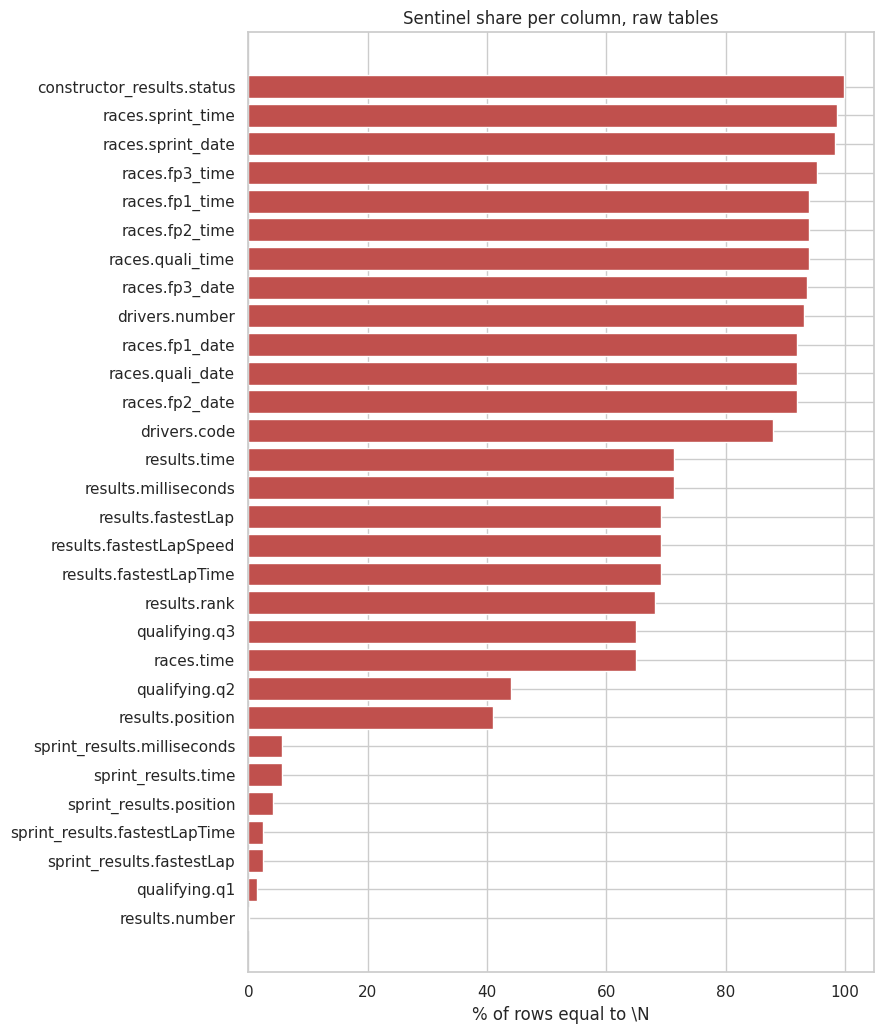

In [2]:
rows = []
for name, df in RAW.items():
    for col in df.columns:
        n = int((df[col] == "\\N").sum())
        if n:
            rows.append((name, col, n, 100 * n / len(df)))
miss = pd.DataFrame(rows, columns=["table", "column", "n_sentinel", "pct"]).sort_values("pct", ascending=False)
display(miss.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 0.3 * len(miss) + 1.5))
ax.barh(miss["table"] + "." + miss["column"], miss["pct"], color="#c0504d")
ax.invert_yaxis()
ax.set_xlabel("% of rows equal to \\N")
ax.set_title("Sentinel share per column, raw tables")
save_show(fig, "01_sentinel_share_raw")

Reading the table: `results.position` is empty for every driver who was not classified, which is real information and not an error. `qualifying.q2` and `q3` are empty for drivers knocked out earlier. The `races` session dates are empty before those sessions were recorded. None of the key columns used for joins contain `\N`.

### 2.2 Field size, qualifying coverage and podium base rate by season

These three plots drive the training-window decision and explain why the podium base rate is not constant over time.

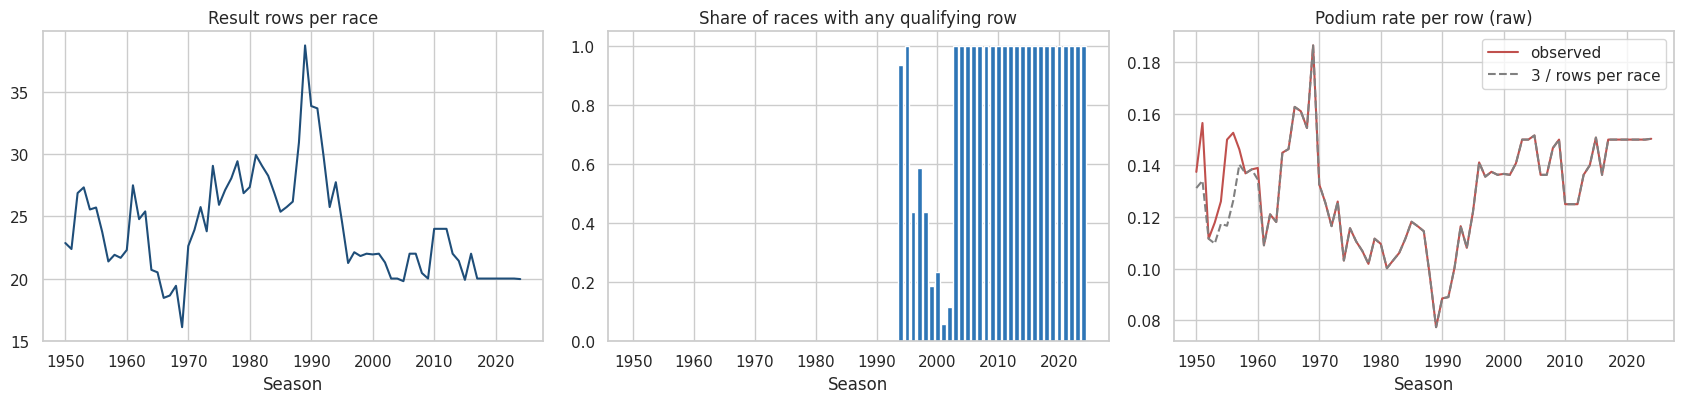

,rows,races,podium_rate,entries_per_race,expected_rate,qual_races,qual_race_share
year,,,,,,,
1950,160,7,0.138,22.857,0.131,NaN,0.000
1960,223,10,0.139,22.300,0.135,NaN,0.000
1980,383,14,0.110,27.357,0.110,NaN,0.000
1994,444,16,0.108,27.750,0.108,15.0,0.938
1996,340,16,0.141,21.250,0.141,7.0,0.438
2001,374,17,0.136,22.000,0.136,1.0,0.059
2003,320,16,0.150,20.000,0.150,16.0,1.000
2010,456,19,0.125,24.000,0.125,19.0,1.000
2020,340,17,0.150,20.000,0.150,17.0,1.000


In [3]:
races = T["races"][["raceId", "year", "round", "circuitId", "name", "date"]].copy()
res0 = T["results"].merge(races, on="raceId", how="left")
res0["podium_raw"] = (res0["positionOrder"] <= 3).astype(int)

season = res0.groupby("year").agg(rows=("resultId", "count"), races=("raceId", "nunique"),
                                  podium_rate=("podium_raw", "mean"))
season["entries_per_race"] = season["rows"] / season["races"]
season["expected_rate"] = 3 / season["entries_per_race"]

q_raw = T["qualifying"].merge(races[["raceId", "year"]], on="raceId", how="left")
season["qual_races"] = q_raw.groupby("year")["raceId"].nunique()
season["qual_race_share"] = season["qual_races"].fillna(0) / season["races"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(season.index, season["entries_per_race"], color="#1f4e79")
axes[0].set_title("Result rows per race")
axes[0].set_xlabel("Season")

axes[1].bar(season.index, season["qual_race_share"], color="#2e75b6")
axes[1].set_title("Share of races with any qualifying row")
axes[1].set_xlabel("Season")
axes[1].set_ylim(0, 1.05)

axes[2].plot(season.index, season["podium_rate"], label="observed", color="#c0504d")
axes[2].plot(season.index, season["expected_rate"], label="3 / rows per race", color="grey", ls="--")
axes[2].set_title("Podium rate per row (raw)")
axes[2].set_xlabel("Season")
axes[2].legend()
save_show(fig, "02_season_overview_raw")
display(season.loc[[1950, 1960, 1980, 1994, 1996, 2001, 2003, 2010, 2020, 2024]].round(3))

### 2.3 Rows with `grid = 0`

`grid = 0` mixes three different situations: drivers who never started, drivers who started from the pit lane, and a few historical oddities. They need different treatment, so we look at `positionText` and `status` first.

grid = 0 rows: 1638 of 26759 (6.1%)


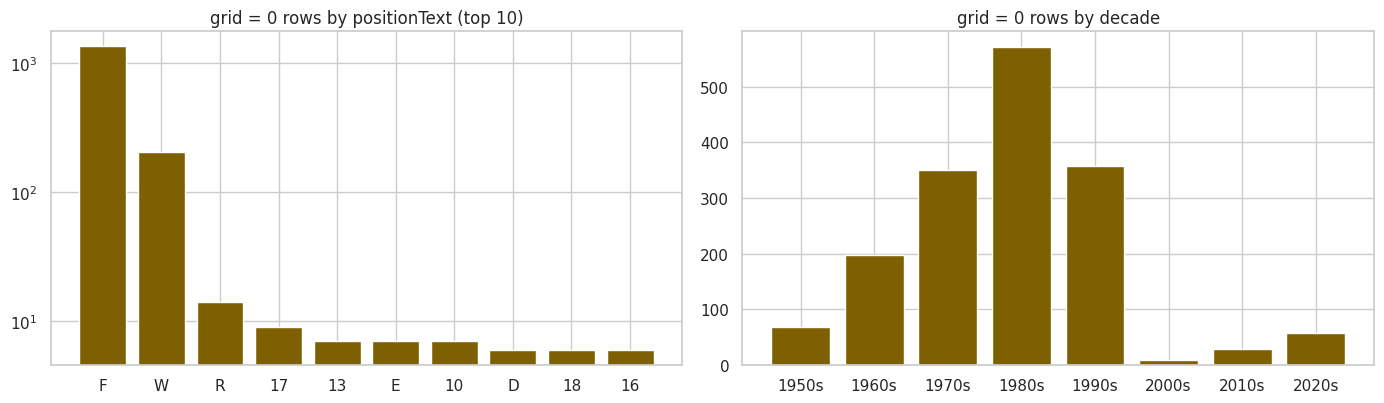

,rows
status,
Did not qualify,1013
Did not prequalify,331
Withdrew,164
+1 Lap,27
Finished,22
Accident,20
Injury,8
+2 Laps,7
Engine,6


In [4]:
status = T["status"][["statusId", "status"]]
g0 = res0[res0["grid"] == 0].merge(status, on="statusId", how="left")
print(f"grid = 0 rows: {len(g0)} of {len(res0)} ({100*len(g0)/len(res0):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
pt = g0["positionText"].value_counts().head(10)
axes[0].bar(pt.index.astype(str), pt.values, color="#7f6000")
axes[0].set_title("grid = 0 rows by positionText (top 10)")
axes[0].set_yscale("log")

dec = (g0["year"] // 10 * 10).value_counts().sort_index()
axes[1].bar(dec.index.astype(str) + "s", dec.values, color="#7f6000")
axes[1].set_title("grid = 0 rows by decade")
save_show(fig, "03_grid_zero_breakdown")
display(g0["status"].value_counts().head(12).to_frame("rows"))

Most `grid = 0` rows are `F` (failed to qualify, including the 107% rule) or `W` (withdrew) and never started. The remainder, mostly from 2000 onward and carrying a finishing position or a retirement, are pit-lane starts.

## 3. Key checks

### 3.1 Primary keys: unique and non-null

For the two tables where the grain matters, the natural key `(raceId, driverId)` is checked as well. `results` is expected to fail it.

In [5]:
PK = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "driver_standings": ["driverStandingsId"],
    "pit_stops": ["raceId", "driverId", "stop"], "lap_times": ["raceId", "driverId", "lap"],
}
NATURAL = {"results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
           "sprint_results": ["raceId", "driverId"]}

def key_check(name, cols, kind):
    df = T[name]
    return {"table": name, "kind": kind, "key": ", ".join(cols), "rows": len(df),
            "null_rows": int(df[cols].isna().any(axis=1).sum()),
            "duplicate_rows": int(df.duplicated(cols).sum())}

pk_report = pd.DataFrame([key_check(n, c, "primary") for n, c in PK.items()] +
                         [key_check(n, c, "natural") for n, c in NATURAL.items()])
display(pk_report)

,table,kind,key,rows,null_rows,duplicate_rows
0,circuits,primary,circuitId,77,0,0
1,constructors,primary,constructorId,212,0,0
2,drivers,primary,driverId,861,0,0
3,races,primary,raceId,1125,0,0
4,seasons,primary,year,75,0,0
5,status,primary,statusId,139,0,0
6,results,primary,resultId,26759,0,0
7,qualifying,primary,qualifyId,10494,0,0
8,sprint_results,primary,resultId,360,0,0
9,constructor_results,primary,constructorResultsId,12625,0,0


### 3.2 Foreign keys: every reference must exist in its parent table

In [6]:
FK = [
    ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
    ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
]

def fk_check(child, col, parent, pcol):
    c = T[child][col]
    parents = set(T[parent][pcol].dropna())
    return {"child": f"{child}.{col}", "parent": f"{parent}.{pcol}", "rows": len(c),
            "null": int(c.isna().sum()), "orphans": int((~c.dropna().isin(parents)).sum())}

fk_report = pd.DataFrame([fk_check(*f) for f in FK])
display(fk_report)
print("Total orphan references:", int(fk_report["orphans"].sum()))

,child,parent,rows,null,orphans
0,results.raceId,races.raceId,26759,0,0
1,results.driverId,drivers.driverId,26759,0,0
2,results.constructorId,constructors.constructorId,26759,0,0
3,results.statusId,status.statusId,26759,0,0
4,races.circuitId,circuits.circuitId,1125,0,0
5,races.year,seasons.year,1125,0,0
6,qualifying.raceId,races.raceId,10494,0,0
7,qualifying.driverId,drivers.driverId,10494,0,0
8,qualifying.constructorId,constructors.constructorId,10494,0,0
9,driver_standings.raceId,races.raceId,34863,0,0


Total orphan references: 0


Primary keys are unique and non-null for every table. The only failure is the intended one: `results` has repeated `(raceId, driverId)` pairs, which breaks the grain of our modeling table and is handled in section 4. The foreign key table shows whether any reference is orphaned; the joins below rely on these being clean.

## 4. Cleaning

Every rule below is applied to a copy, in order, and logged with the number of rows it touches.

### 4.1 Semantic typing

Dates become datetimes and lap times become seconds. Lap-time strings look like `1:27.452` (minutes, seconds, milliseconds).

In [7]:
def lap_to_seconds(s):
    """'1:27.452' -> 87.452, '58.123' -> 58.123, NaN stays NaN."""
    if pd.isna(s):
        return np.nan
    s = str(s)
    if ":" in s:
        m, sec = s.split(":")
        return int(m) * 60 + float(sec)
    return float(s)

qual = T["qualifying"].copy()
for c in ["q1", "q2", "q3"]:
    qual[c + "_sec"] = qual[c].map(lap_to_seconds)

res_t = T["results"].copy()
res_t["fastestLapTime_sec"] = res_t["fastestLapTime"].map(lap_to_seconds)   # post-race, kept for EDA only

races_t = T["races"].copy()
races_t["date"] = pd.to_datetime(races_t["date"])
drivers_t = T["drivers"].copy()
drivers_t["dob"] = pd.to_datetime(drivers_t["dob"])

print(qual[["q1", "q1_sec", "q2", "q2_sec", "q3", "q3_sec"]].dropna(subset=["q3"]).head(3).to_string(index=False))
print("\nraces.date dtype:", races_t["date"].dtype, "| drivers.dob dtype:", drivers_t["dob"].dtype)
print("q1_sec range:", round(float(qual["q1_sec"].min()), 2), "to", round(float(qual["q1_sec"].max()), 2))

      q1  q1_sec       q2  q2_sec       q3  q3_sec
1:26.572  86.572 1:25.187  85.187 1:26.714  86.714
1:26.103  86.103 1:25.315  85.315 1:26.869  86.869
1:25.664  85.664 1:25.452  85.452 1:27.079  87.079

races.date dtype: datetime64[ns] | drivers.dob dtype: datetime64[ns]
q1_sec range: 53.9 to 1002.64


Durations are typed as well, even where they are only used for EDA: pit-stop durations come as text such as `22.552` or `1:01.235`, race times as milliseconds, and session start times as clock strings. All of these are post-race or descriptive fields and none of them becomes a feature.

In [8]:
def duration_to_seconds(s):
    """'22.552' -> 22.552, '1:01.235' -> 61.235, '1:01:20.3' -> 3680.3, NaN stays NaN."""
    if pd.isna(s):
        return np.nan
    secs = 0.0
    try:
        for part in str(s).split(":"):
            secs = secs * 60 + float(part)
    except ValueError:
        return np.nan
    return secs

pit_t = T["pit_stops"].copy()
pit_t["duration_sec"] = pit_t["duration"].map(duration_to_seconds)        # post-race, EDA only
laps_t = T["lap_times"].copy()
laps_t["lap_sec"] = laps_t["milliseconds"] / 1000                          # post-race, EDA only
res_t["race_time_sec"] = res_t["milliseconds"] / 1000                      # post-race, EDA only
races_t["start_time"] = pd.to_timedelta(races_t["time"], errors="coerce")  # clock time of the start, UTC

print("pit_stops.duration -> seconds:", pit_t["duration_sec"].notna().sum(), "of", len(pit_t),
      "| range", round(float(pit_t["duration_sec"].min()), 2), "to", round(float(pit_t["duration_sec"].max()), 2))
print("lap_times -> seconds: range", round(float(laps_t["lap_sec"].min()), 2), "to", round(float(laps_t["lap_sec"].max()), 2))
print("results race time -> seconds: filled for", int(res_t["race_time_sec"].notna().sum()), "rows (classified finishers on the lead lap)")
print("races.time -> timedelta:", races_t["start_time"].dtype, "| filled for", int(races_t["start_time"].notna().sum()), "races")

pit_stops.duration -> seconds: 11371 of 11371 | range 12.9 to 3069.02
lap_times -> seconds: range 55.4 to 7507.55
results race time -> seconds: filled for 7680 rows (classified finishers on the lead lap)
races.time -> timedelta: timedelta64[ns] | filled for 394 races


### 4.2 Row-level rules

The working table `res` is `results` joined to `races` for year, round, circuit and date.

| Rule | Action | Why |
|---|---|---|
| R1 | Drop the Indianapolis 500 races of 1950-1960 | Almost no F1 regular entered, drivers rarely raced elsewhere, grid structure differs, and it distorts home-race analysis |
| R2 | Drop non-starters: `positionText` F or W, or status Did not qualify / Did not prequalify | They have no grid slot and never raced, so "will this driver podium" is undefined |
| R3 | One row per `(raceId, driverId)`: keep the row with a non-zero grid, then the lowest grid, then the lowest `resultId` | Shared drives. The rule uses only pre-race information. Picking the best `positionOrder` would select rows using the target |
| R4 | Flag `pit_lane_start` where `grid = 0`, and set `grid_clean` to the last grid slot of that race plus one | Pit-lane starters start behind everyone, so a numeric grid is more honest than 0 |

In [9]:
log = []
def log_step(rule, before, after, note=""):
    log.append({"rule": rule, "rows_before": before, "rows_removed": before - after,
                "rows_after": after, "note": note})

res = res_t.merge(races_t[["raceId", "year", "round", "circuitId", "name", "date"]], on="raceId", how="left")
res["podium"] = (res["positionOrder"] <= 3).astype(int)
assert res["positionOrder"].notna().all()
log.append({"rule": "start", "rows_before": len(res), "rows_removed": 0, "rows_after": len(res),
            "note": "results joined to races"})

# R1: Indianapolis 500, 1950-1960
is_indy = res["name"].eq("Indianapolis 500") & res["year"].between(1950, 1960)
n_races_indy = res.loc[is_indy, "raceId"].nunique()
before = len(res)
res = res[~is_indy].copy()
log_step("R1 Indy 500 1950-1960", before, len(res), f"{n_races_indy} races removed")

# R2: non-starters
non_start = res["positionText"].isin(["F", "W"]) | res["statusId"].isin([81, 97])
print("R2 rows removed by positionText:", res.loc[non_start, "positionText"].value_counts().to_dict())
print("R2 rows removed that had grid > 0:", int((non_start & (res["grid"] > 0)).sum()))
before = len(res)
res = res[~non_start].copy()
log_step("R2 non-starters", before, len(res), "positionText F/W or status DNQ/DNPQ")

# R3: duplicates (shared drives)
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask]
print(f"R3 duplicate pairs: {dups.groupby(['raceId', 'driverId']).ngroups}, rows involved: {len(dups)}")
print("R3 duplicate rows by decade:", (dups["year"] // 10 * 10).value_counts().sort_index().to_dict())

res["_has_grid"] = (res["grid"] > 0).astype(int)
res = res.sort_values(["raceId", "driverId", "_has_grid", "grid", "resultId"],
                      ascending=[True, True, False, True, True])
kept = res.drop_duplicates(["raceId", "driverId"], keep="first")

# how often does the rule change the podium label compared with "any row podium"?
any_pod = dups.groupby(["raceId", "driverId"])["podium"].max()
kept_pod = kept.set_index(["raceId", "driverId"])["podium"].reindex(any_pod.index)
print("R3 pairs where a dropped row was a podium but the kept row was not:", int((any_pod > kept_pod).sum()))

before = len(res)
res = kept.drop(columns="_has_grid").copy()
log_step("R3 duplicates (shared drives)", before, len(res), "keep non-zero grid, lowest grid, lowest resultId")

# R4: pit-lane starters
res["pit_lane_start"] = (res["grid"] == 0).astype(int)
last_slot = res.loc[res["grid"] > 0].groupby("raceId")["grid"].max().rename("last_slot")
res = res.merge(last_slot, on="raceId", how="left")
res["last_slot"] = res["last_slot"].fillna(0)
res["grid_clean"] = np.where(res["pit_lane_start"] == 1, res["last_slot"] + 1, res["grid"]).astype(int)
log_step("R4 pit-lane flag", len(res), len(res), f"{int(res['pit_lane_start'].sum())} rows flagged, none removed")
print("R4 pit-lane starters by decade:", (res.loc[res.pit_lane_start == 1, "year"] // 10 * 10)
      .value_counts().sort_index().to_dict())

cleaning_log = pd.DataFrame(log)
display(cleaning_log)

R2 rows removed by positionText: {'F': 1368, 'W': 336}
R2 rows removed that had grid > 0: 153
R3 duplicate pairs: 61, rows involved: 125
R3 duplicate rows by decade: {1950: 117, 1960: 8}
R3 pairs where a dropped row was a podium but the kept row was not: 17
R4 pit-lane starters by decade: {1980: 10, 1990: 4, 2010: 20, 2020: 53}


,rule,rows_before,rows_removed,rows_after,note
0,start,26759,0,26759,results joined to races
1,R1 Indy 500 1950-1960,26759,405,26354,11 races removed
2,R2 non-starters,26354,1704,24650,positionText F/W or status DNQ/DNPQ
3,R3 duplicates (shared drives),24650,64,24586,"keep non-zero grid, lowest grid, lowest resultId"
4,R4 pit-lane flag,24586,0,24586,"87 rows flagged, none removed"


### 4.3 Validation of the cleaned table

Three checks: the grain is now unique, every race still has about three podium finishers, and no non-starter survives. Races with fewer than three podium rows are a known side effect of shared drives (the kept row of a shared car may not be the podium one) and of removing the Indy 500.

In [10]:
assert not res.duplicated(["raceId", "driverId"]).any(), "grain violated"
assert not res["positionText"].isin(["F", "W"]).any()
assert not res["statusId"].isin([81, 97]).any()
print("Unique (raceId, driverId): OK, rows =", len(res))

pod_per_race = res.groupby("raceId")["podium"].sum()
print("\nPodium rows per race:\n", pod_per_race.value_counts().sort_index().to_string())
odd = pod_per_race[pod_per_race != 3].index
odd_years = res[res["raceId"].isin(odd)].groupby("raceId")["year"].first()
print("\nRaces with podium count != 3 by decade:", (odd_years // 10 * 10).value_counts().sort_index().to_dict())
print("Of which in 2003 or later:", int((odd_years >= 2003).sum()))

Unique (raceId, driverId): OK, rows = 24586

Podium rows per race:
 podium
2       3
3    1109
4       1
5       1

Races with podium count != 3 by decade: {1950: 5}
Of which in 2003 or later: 0


## 5. Audit and EDA after cleaning

### 5.1 Effect of cleaning on field size and podium base rate

Same quantities as section 2.2, before and after. Cleaning should bring the rows per race down to actual starters and lift the podium rate in eras with large qualifying fields.

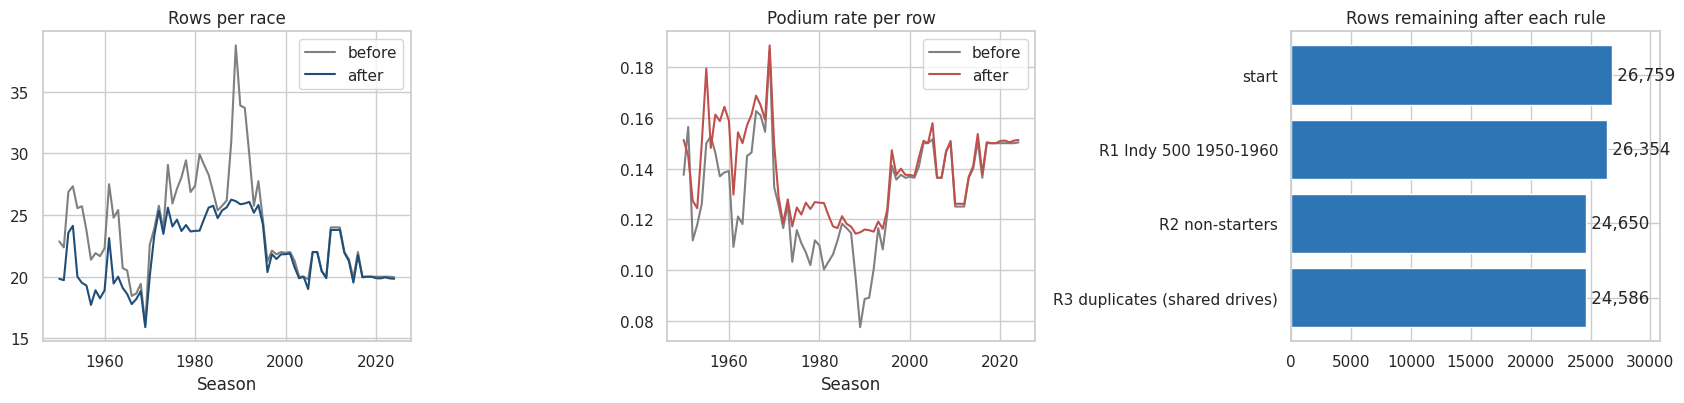

In [11]:
def season_summary(df):
    g = df.groupby("year").agg(rows=("resultId", "count"), races=("raceId", "nunique"),
                               podium_rate=("podium", "mean"))
    g["per_race"] = g["rows"] / g["races"]
    return g

before_s = season_summary(res0.assign(podium=res0["podium_raw"]))
after_s = season_summary(res)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(before_s.index, before_s["per_race"], label="before", color="grey")
axes[0].plot(after_s.index, after_s["per_race"], label="after", color="#1f4e79")
axes[0].set_title("Rows per race"); axes[0].legend(); axes[0].set_xlabel("Season")

axes[1].plot(before_s.index, before_s["podium_rate"], label="before", color="grey")
axes[1].plot(after_s.index, after_s["podium_rate"], label="after", color="#c0504d")
axes[1].set_title("Podium rate per row"); axes[1].legend(); axes[1].set_xlabel("Season")

steps = cleaning_log[cleaning_log["rule"] != "R4 pit-lane flag"]
axes[2].barh(steps["rule"], steps["rows_after"], color="#2e75b6")
axes[2].invert_yaxis()
axes[2].set_title("Rows remaining after each rule")
for i, v in enumerate(steps["rows_after"]):
    axes[2].text(v, i, f" {v:,}", va="center")
axes[2].set_xlim(0, steps["rows_after"].max() * 1.15)
save_show(fig, "04_cleaning_effect")

### 5.2 Grid position against podium rate (modern era)

First look at why grid position is expected to be the strongest single feature. Pit-lane starters are shown separately.

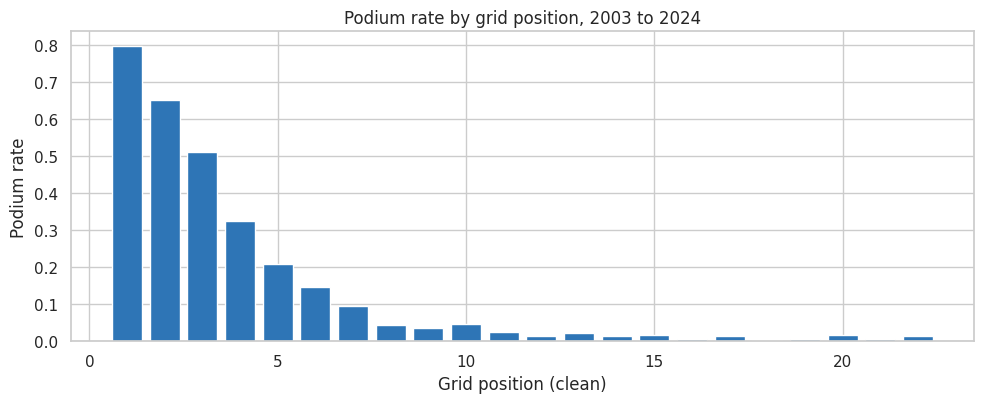

Pole podium rate: 79.81% | front row: 72.50% | pit-lane starts: 0.00% (n=73)


In [12]:
modern = res[res["year"] >= 2003]
g = modern.groupby("grid_clean")["podium"].agg(["mean", "count"])
g = g[(g["count"] >= 30) & (g.index <= 22)]
pit = modern[modern["pit_lane_start"] == 1]["podium"]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(g.index, g["mean"], color="#2e75b6")
ax.set_xlabel("Grid position (clean)"); ax.set_ylabel("Podium rate")
ax.set_title("Podium rate by grid position, 2003 to 2024")
save_show(fig, "05_grid_vs_podium")
print(f"Pole podium rate: {g.loc[1, 'mean']:.2%} | front row: {modern[modern.grid_clean <= 2]['podium'].mean():.2%} "
      f"| pit-lane starts: {pit.mean():.2%} (n={len(pit)})")

### 5.3 Qualifying coverage on the cleaned rows

This repeats the coverage check at row level, which is what a qualifying feature actually depends on. A row has coverage if `qualifying.csv` holds a record for that driver in that race.

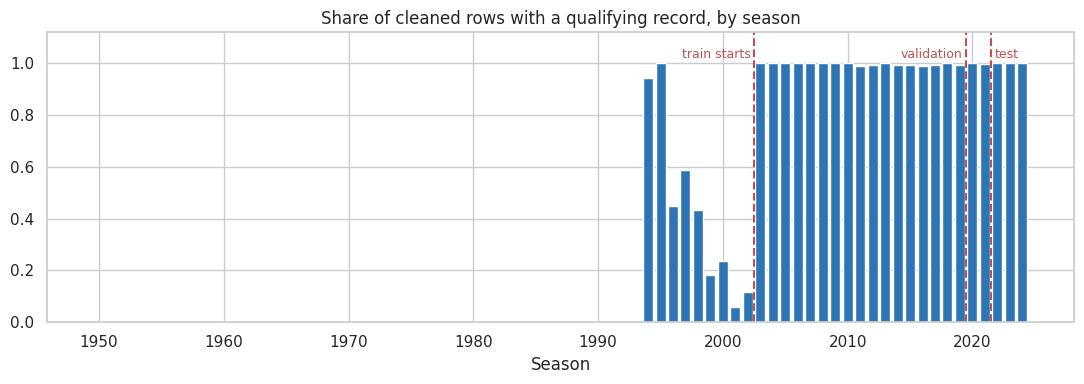

Row coverage by period:
  1950-1993: 0.0% of 12,366 rows
  1994-2002: 46.2% of 3,310 rows
  2003-2024: 99.8% of 8,910 rows


In [13]:
qk = qual[["raceId", "driverId"]].drop_duplicates().assign(has_q=1)
chk = res.merge(qk, on=["raceId", "driverId"], how="left")
chk["has_q"] = chk["has_q"].fillna(0)
cov = chk.groupby("year")["has_q"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(cov.index, cov.values, color="#2e75b6")
for x, label, ha in [(2003, "train starts", "right"), (2020, "validation", "right"), (2022, "test", "left")]:
    ax.axvline(x - 0.5, color="#c0504d", ls="--")
    ax.text(x - 0.5 + (0.3 if ha == "left" else -0.3), 1.02, label, color="#c0504d", fontsize=9, ha=ha)
ax.set_ylim(0, 1.12)
ax.set_title("Share of cleaned rows with a qualifying record, by season")
ax.set_xlabel("Season")
save_show(fig, "06_qualifying_coverage_clean")

print("Row coverage by period:")
for lo, hi in [(1950, 1993), (1994, 2002), (2003, 2024)]:
    s = chk[chk["year"].between(lo, hi)]
    print(f"  {lo}-{hi}: {s['has_q'].mean():.1%} of {len(s):,} rows")

## 6. Base table and split labels

`base` is the unique driver-race table every later section builds on. It keeps identifiers, the pre-race grid fields and the target. `statusId` is kept only so Question 3 can group retirement causes; it is post-race and is never a feature.

**Split: train 2003-2019, validation 2020-2021, test 2022-2024.** Rows from 1950-2002 are labelled `history`.

Why this split:
- **Split by time, not at random.** The model is meant to predict races that have not happened yet, using what is known from earlier seasons. A random split would put races from 2023 into training and races from 2010 into testing, so the model would learn from the future. It would also put teammates from the same race on both sides of the split, so the test score would no longer measure performance on unseen races. Splitting by season keeps every race, and every season, whole on one side.
- **It copies how the model would be used.** Fit on past seasons, choose settings on the next seasons, then report once on the newest seasons that nobody looked at.
- **Training starts in 2003 because of qualifying data.** Section 5.3 shows that qualifying records cover 0% of rows before 1994, 46% in 1994-2002 and 99.8% from 2003. Qualifying is one of the strongest feature groups, so training on seasons where it is mostly missing would teach the model about the missing-value pattern rather than about qualifying. Experiment C in Section 3 checks this choice by training from 1950, 1980 and 1996 instead.
- **Validation is two seasons (2020-2021), test is three (2022-2024).** Two seasons (39 races, 775 rows) is the smallest period that still gives about 115 podiums to tune thresholds on. The test seasons are the 2022 ground-effect regulations, which the training seasons never saw, so the test score is a deliberately hard, honest check of how the model copes with a rule change.
- **History rows are not wasted.** 1950-2002 rows stay in the table for the EDA, the data-engineering questions and as earlier races for the form features (a driver's 2003 form uses their 2002 races). They are never training rows in the main experiment.

In [14]:
base = res[["resultId", "raceId", "driverId", "constructorId", "year", "round", "circuitId", "name", "date",
            "grid", "grid_clean", "pit_lane_start", "positionOrder", "podium", "statusId"]].rename(
            columns={"name": "race_name"})
base["split"] = np.select([base["year"] < 2003, base["year"] <= 2019, base["year"] <= 2021],
                          ["history", "train", "val"], default="test")
base = base.sort_values(["date", "round", "grid_clean", "driverId"]).reset_index(drop=True)

assert not base.duplicated(["raceId", "driverId"]).any()
assert base["podium"].isin([0, 1]).all()

summary = base.groupby("split").agg(rows=("resultId", "count"), races=("raceId", "nunique"),
                                    podium_rate=("podium", "mean")).loc[["history", "train", "val", "test"]]
display(summary.round(4))
display(base.head())
print("base shape:", base.shape)

base.to_csv("/kaggle/working/base_results.csv", index=False)

,rows,races,podium_rate
split,,,
history,15676,686,0.1313
train,6783,321,0.1420
val,775,39,0.1510
test,1352,68,0.1509


,resultId,raceId,driverId,constructorId,year,round,circuitId,race_name,date,grid,grid_clean,pit_lane_start,positionOrder,podium,statusId,split
0,20025,833,642,51,1950,1,9,British Grand Prix,1950-05-13,1,1,0,1,1,1,history
1,20026,833,786,51,1950,1,9,British Grand Prix,1950-05-13,2,2,0,2,1,1,history
2,20036,833,579,51,1950,1,9,British Grand Prix,1950-05-13,3,3,0,12,0,44,history
3,20027,833,686,51,1950,1,9,British Grand Prix,1950-05-13,4,4,0,3,1,1,history
4,20038,833,669,105,1950,1,9,British Grand Prix,1950-05-13,5,5,0,14,0,60,history


base shape: (24586, 16)


### Decisions recorded in this section

- Raw files untouched; all cleaning on copies; every row removal logged in `cleaning_log`.
- The grain is `(raceId, driverId)`, enforced by an assertion.
- Duplicates are resolved with a pre-race rule, not by the target.
- Pit-lane starters are kept and flagged, non-starters are dropped.
- Qualifying features will only be reliable from 2003, which is why the main training window starts there.

- Rule R2 removes drivers who never took the start. Section 2.0 shows that 153 of them did have a grid slot (47 from 2003 on), for example withdrawals after qualifying and cars that failed before the start. Whether such a driver will start is not known at the prediction cutoff, so this rule uses a little information from after the cutoff. We keep the rule because the target ("will this driver finish on the podium in this race?") is undefined for a car that never races, and none of these rows could have been a podium. The effect on the training window is 47 non-podium rows out of about 7,000.

## 7. Export the Section 1 report

Writes `section1_results.pdf` with the Section 1 printed output and tables followed by the Section 1 figures (files `01_` to `06_`). The same function is reused at the end of every later section.

In [15]:
import textwrap, datetime
from matplotlib.backends.backend_pdf import PdfPages

def export_report(out_pdf, start, prefix, title, width=200, per_page=80):
    text = "".join(TEE.buf[start:])
    lines = [title, f"Generated {datetime.datetime.now():%Y-%m-%d %H:%M} | pandas {pd.__version__} | numpy {np.__version__}", ""]
    for ln in text.splitlines():
        lines.extend(textwrap.wrap(ln, width, drop_whitespace=False, replace_whitespace=False,
                                   break_long_words=True) or [""])
    figs = sorted(glob.glob(f"{FIG_DIR}/{prefix}*.png"))
    with PdfPages(out_pdf) as pdf:
        for i in range(0, len(lines), per_page):
            fig = plt.figure(figsize=(11.69, 8.27))
            fig.text(0.03, 0.97, "\n".join(lines[i:i + per_page]), family="monospace", fontsize=5.6, va="top", ha="left")
            pdf.savefig(fig)
            plt.close(fig)
        for p in figs:
            fig = plt.figure(figsize=(11.69, 8.27))
            ax = fig.add_axes([0.02, 0.02, 0.96, 0.92])
            ax.imshow(plt.imread(p))
            ax.axis("off")
            fig.suptitle(os.path.basename(p), fontsize=9)
            pdf.savefig(fig)
            plt.close(fig)
    print(f"Wrote {out_pdf}: {-(-len(lines) // per_page)} text pages + {len(figs)} figure pages")

export_report("/kaggle/working/section1_results.pdf", 0, "0", "F1 Podium Prediction, Section 1 results")

Wrote /kaggle/working/section1_results.pdf: 3 text pages + 6 figure pages


# Section 2: Data-Engineering Questions

Three questions, each with its own join path, a plot, a code-generated answer and a short note on grain, missingness and the pre-race cutoff. Section 1 must have run first: this section uses `base`, `qual`, `res0` and the typed tables in `T`.

These are descriptive questions about the whole history, not model training, so they use all seasons that the data supports and do not follow the train, validation and test split.

### 2.0 Carry-over checks from Section 1

Two things were not verifiable from the Section 1 report: the 153 non-starter rows that had a grid slot, and an impossible qualifying lap of about 1000 seconds.

In [16]:
import statsmodels.formula.api as smf
from scipy import stats

S2_START = len(TEE.buf)   # the Section 2 report starts here

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (arrays allowed)."""
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    nn = np.maximum(n, 1)
    p = k / nn
    denom = 1 + z**2 / nn
    centre = (p + z**2 / (2 * nn)) / denom
    half = z * np.sqrt(p * (1 - p) / nn + z**2 / (4 * nn**2)) / denom
    return centre - half, centre + half

# --- check A: non-starter rows (rule R2) that had a grid slot
stat_tbl = T["status"][["statusId", "status"]]
drv_names = T["drivers"][["driverId", "forename", "surname"]]
is_indy_all = res0["name"].eq("Indianapolis 500") & res0["year"].between(1950, 1960)
ns = res0[(res0["positionText"].isin(["F", "W"]) | res0["statusId"].isin([81, 97])) & ~is_indy_all]
ns = ns.merge(stat_tbl, on="statusId", how="left").merge(drv_names, on="driverId", how="left")
ns_g = ns[ns["grid"] > 0]
print(f"R2 removed rows with grid > 0: {len(ns_g)}")
display(pd.crosstab(ns_g["year"] // 10 * 10, ns_g["positionText"]).rename_axis("decade"))
display(ns_g["status"].value_counts().head(8).to_frame("rows"))
recent = ns_g[ns_g["year"] >= 2003]
print(f"Of these, 2003 or later: {len(recent)}")
display(recent[["year", "name", "forename", "surname", "grid", "positionText", "positionOrder", "status"]]
        .sort_values(["year", "name"]).head(40))

R2 removed rows with grid > 0: 153


positionText,F,W
decade,,
1950,1,20
1960,1,9
1970,1,21
1980,1,12
1990,16,18
2000,0,24
2010,0,21
2020,0,8


,rows
status,
Withdrew,64
Engine,13
Did not qualify,12
Accident,11
Gearbox,8
107% Rule,7
Collision,4
Injured,4


Of these, 2003 or later: 47


,year,name,forename,surname,grid,positionText,positionOrder,status
15,2003,Austrian Grand Prix,Heinz-Harald,Frentzen,15,W,20,Clutch
16,2003,Monaco Grand Prix,Jenson,Button,20,W,20,Injured
0,2005,Bahrain Grand Prix,Christian,Klien,7,W,20,Electrical
1,2005,United States Grand Prix,Jarno,Trulli,1,W,7,Withdrew
2,2005,United States Grand Prix,Kimi,Räikkönen,2,W,8,Withdrew
3,2005,United States Grand Prix,Jenson,Button,3,W,9,Withdrew
4,2005,United States Grand Prix,Giancarlo,Fisichella,4,W,10,Withdrew
5,2005,United States Grand Prix,Fernando,Alonso,6,W,11,Withdrew
6,2005,United States Grand Prix,Takuma,Sato,8,W,12,Withdrew
7,2005,United States Grand Prix,Mark,Webber,9,W,13,Withdrew


**Decision on these rows.** The 47 rows from 2003 onward are drivers who qualified (they have a grid slot) but did not take the start: the 2005 United States Grand Prix withdrawals, injuries, and cars that failed before the start (for example Vettel, Bahrain 2016, from P3). Rule R2 keeps them out. This is a judgement call: at the prediction cutoff nobody knows yet that the driver will not start, so strictly the rule uses information from after the cutoff. We keep it because a podium is undefined for a car that never races, and all 47 rows are non-podiums, so removing them cannot inflate the podium rate of starters in any meaningful way. The choice is recorded as a limitation.

In [17]:
# --- check B: implausible qualifying laps
qq = qual.merge(T["races"][["raceId", "year", "name"]], on="raceId", how="left")
qq["q1_ratio"] = qq["q1_sec"] / qq.groupby("raceId")["q1_sec"].transform("median")
print("q1 lap / race median q1, quantiles:")
print(qq["q1_ratio"].quantile([0, .001, .01, .5, .99, .999, 1]).round(3).to_string())

bad_q1 = qq[qq["q1_ratio"] > 1.5].merge(drv_names, on="driverId", how="left")
print(f"\nq1 laps above 1.5x the race median: {len(bad_q1)}")
display(bad_q1[["year", "name", "forename", "surname", "q1", "q1_sec", "q1_ratio"]].sort_values("q1_ratio",
        ascending=False).head(15))

# rule R5: a lap above 1.5x the median of the same session in the same race is treated as invalid
for c in ["q1_sec", "q2_sec", "q3_sec"]:
    med = qual.groupby("raceId")[c].transform("median")
    bad = qual[c] > 1.5 * med
    print(f"R5 {c}: {int(bad.sum())} laps set to NaN")
    qual.loc[bad, c] = np.nan
print("q1_sec range after R5:", round(float(qual["q1_sec"].min()), 2), "to", round(float(qual["q1_sec"].max()), 2))
print("repeated (raceId, position) in qualifying:", int(qual.duplicated(["raceId", "position"]).sum()))

q1 lap / race median q1, quantiles:
0.000    0.890
0.001    0.950
0.010    0.973
0.500    1.000
0.990    1.054
0.999    1.137
1.000    9.881

q1 laps above 1.5x the race median: 1


,year,name,forename,surname,q1,q1_sec,q1_ratio
0,1995,Japanese Grand Prix,Mark,Blundell,16:42.640,1002.64,9.880806


R5 q1_sec: 1 laps set to NaN
R5 q2_sec: 1 laps set to NaN
R5 q3_sec: 0 laps set to NaN
q1_sec range after R5: 53.9 to 153.88
repeated (raceId, position) in qualifying: 0


## 2.1 Question 1: which circuits convert a front-row start into a podium, and does the ranking change after 2014?

Join path: `base` (one row per driver per race) with `qualifying` on `(raceId, driverId)` for the qualifying position, and with `circuits` through `circuitId`.

Decisions:
- Window 2003-2024, where qualifying covers 99.8% of rows. The eras are 2003-2013 and 2014-2024 (hybrid era onward).
- Front row means position 1 or 2. It is defined twice: by qualifying position (`qpos`) and by grid (`grid_clean`, after penalties). Only rows that have both are used so the two definitions share the same sample.
- Conversion rate is front-row starters who finished on the podium divided by front-row starters. Intervals are 95% Wilson intervals.
- A circuit needs at least 8 races overall for the ranking and at least 5 races in each era for the era comparison. In the code the per-era rule is written as at least 10 front-row starts, which is the same thing: every race has exactly two front-row starters.

In [18]:
circ = T["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
qpos = qual[["raceId", "driverId", "position"]].rename(columns={"position": "qpos"})
q1 = base.merge(qpos, on=["raceId", "driverId"], how="left").merge(circ, on="circuitId", how="left")
q1 = q1[q1["year"] >= 2003].copy()
print(f"rows 2003-2024: {len(q1)}, missing qualifying position: {int(q1['qpos'].isna().sum())} (dropped)")
q1 = q1[q1["qpos"].notna()].copy()
q1["era"] = np.where(q1["year"] <= 2013, "2003-2013", "2014-2024")
q1["front_grid"] = q1["grid_clean"] <= 2
q1["front_q"] = q1["qpos"] <= 2

print("\nFront row by qualifying (rows) vs front row by grid (columns):")
display(pd.crosstab(q1["front_q"], q1["front_grid"], margins=True))
print("Podium rate of front-row starters: by qualifying "
      f"{q1.loc[q1.front_q, 'podium'].mean():.1%}, by grid {q1.loc[q1.front_grid, 'podium'].mean():.1%}")

def overall(df, flag):
    f = df[df[flag]]
    g = f.groupby("circuit").agg(n=("podium", "size"), pod=("podium", "sum"), races=("raceId", "nunique")).reset_index()
    g["rate"] = g["pod"] / g["n"]
    g["lo"], g["hi"] = wilson(g["pod"], g["n"])
    return g[g["races"] >= 8].sort_values("rate", ascending=False).reset_index(drop=True)

def by_era(df, flag):
    f = df[df[flag]]
    g = f.groupby(["circuit", "era"]).agg(n=("podium", "size"), pod=("podium", "sum")).reset_index()
    g["rate"] = g["pod"] / g["n"]
    w = g.pivot(index="circuit", columns="era", values="rate").join(
        g.pivot(index="circuit", columns="era", values="n"), lsuffix="_rate", rsuffix="_n")
    w = w.rename(columns={"2003-2013_rate": "rate_pre", "2014-2024_rate": "rate_post",
                          "2003-2013_n": "n_pre", "2014-2024_n": "n_post"})
    w = w.dropna()
    w = w[(w["n_pre"] >= 10) & (w["n_post"] >= 10)].copy()     # at least 5 races per era
    w["delta"] = w["rate_post"] - w["rate_pre"]
    return w

ov_grid, ov_q = overall(q1, "front_grid"), overall(q1, "front_q")
era_grid, era_q = by_era(q1, "front_grid"), by_era(q1, "front_q")

cmp_ov = ov_grid[["circuit", "races", "n", "rate"]].merge(
    ov_q[["circuit", "rate"]], on="circuit", suffixes=("_grid", "_qual"))
cmp_ov["gap_grid_minus_qual"] = cmp_ov["rate_grid"] - cmp_ov["rate_qual"]
print(f"\nOverall front-row conversion, 2003-2024 ({len(cmp_ov)} circuits with 8+ races):")
display(cmp_ov.round(3))

print("Era comparison, grid definition (circuits with 5+ races in each era):")
display(era_grid.sort_values("rate_post", ascending=False).round(3))

print("\nDo circuits differ at all? Chi-square test across circuits (10+ front-row starts each):")
q1_chi = {}
for label, flag in [("grid", "front_grid"), ("qualifying", "front_q")]:
    for era in ["2003-2013", "2014-2024"]:
        f = q1[q1[flag] & (q1["era"] == era)]
        c = f.groupby("circuit")["podium"].agg(["sum", "size"])
        c = c[c["size"] >= 10]
        chi2, p_chi, _, _ = stats.chi2_contingency(np.column_stack([c["sum"], c["size"] - c["sum"]]))
        q1_chi[(label, era)] = float(p_chi)
        print(f"  {label:10s} {era}: {len(c)} circuits, chi2={chi2:.1f}, p={p_chi:.3f}")

rho_g = stats.spearmanr(era_grid["rate_pre"], era_grid["rate_post"])
rho_q = stats.spearmanr(era_q["rate_pre"], era_q["rate_post"])
print(f"Rank correlation between eras: grid definition rho={rho_g.statistic:.2f} (p={rho_g.pvalue:.3f}, "
      f"{len(era_grid)} circuits); qualifying definition rho={rho_q.statistic:.2f} (p={rho_q.pvalue:.3f}, "
      f"{len(era_q)} circuits)")

rows 2003-2024: 8910, missing qualifying position: 21 (dropped)

Front row by qualifying (rows) vs front row by grid (columns):


front_grid,False,True,All
front_q,,,
False,8001,36,8037
True,37,815,852
All,8038,851,8889


Podium rate of front-row starters: by qualifying 71.0%, by grid 72.5%

Overall front-row conversion, 2003-2024 (24 circuits with 8+ races):


,circuit,races,n,rate_grid,rate_qual,gap_grid_minus_qual
0,Circuit of the Americas,12,24,0.833,0.792,0.042
1,Circuit de Monaco,21,41,0.829,0.780,0.049
2,Sochi Autodrom,8,16,0.812,0.812,0.000
3,Suzuka Circuit,18,36,0.806,0.806,0.000
4,Yas Marina Circuit,16,32,0.781,0.750,0.031
5,Circuit de Spa-Francorchamps,20,40,0.775,0.775,0.000
6,Autodromo Nazionale di Monza,22,44,0.750,0.727,0.023
7,Red Bull Ring,14,28,0.750,0.714,0.036
8,Circuit de Barcelona-Catalunya,22,44,0.750,0.727,0.023
9,Silverstone Circuit,23,46,0.739,0.761,-0.022


Era comparison, grid definition (circuits with 5+ races in each era):


era,rate_pre,rate_post,n_pre,n_post,delta
circuit,,,,,
Circuit de Monaco,0.773,0.895,22.0,19.0,0.122
Suzuka Circuit,0.722,0.889,18.0,18.0,0.167
Yas Marina Circuit,0.600,0.864,10.0,22.0,0.264
Circuit de Spa-Francorchamps,0.722,0.818,18.0,22.0,0.096
Circuit de Barcelona-Catalunya,0.682,0.818,22.0,22.0,0.136
Autódromo José Carlos Pace,0.591,0.789,22.0,19.0,0.199
Shanghai International Circuit,0.650,0.786,20.0,14.0,0.136
Circuit Gilles Villeneuve,0.600,0.778,20.0,18.0,0.178
Silverstone Circuit,0.727,0.750,22.0,24.0,0.023



Do circuits differ at all? Chi-square test across circuits (10+ front-row starts each):
  grid       2003-2013: 20 circuits, chi2=10.8, p=0.929
  grid       2014-2024: 19 circuits, chi2=15.0, p=0.663
  qualifying 2003-2013: 20 circuits, chi2=10.4, p=0.943
  qualifying 2014-2024: 19 circuits, chi2=14.5, p=0.695
Rank correlation between eras: grid definition rho=0.36 (p=0.211, 14 circuits); qualifying definition rho=0.54 (p=0.047, 14 circuits)


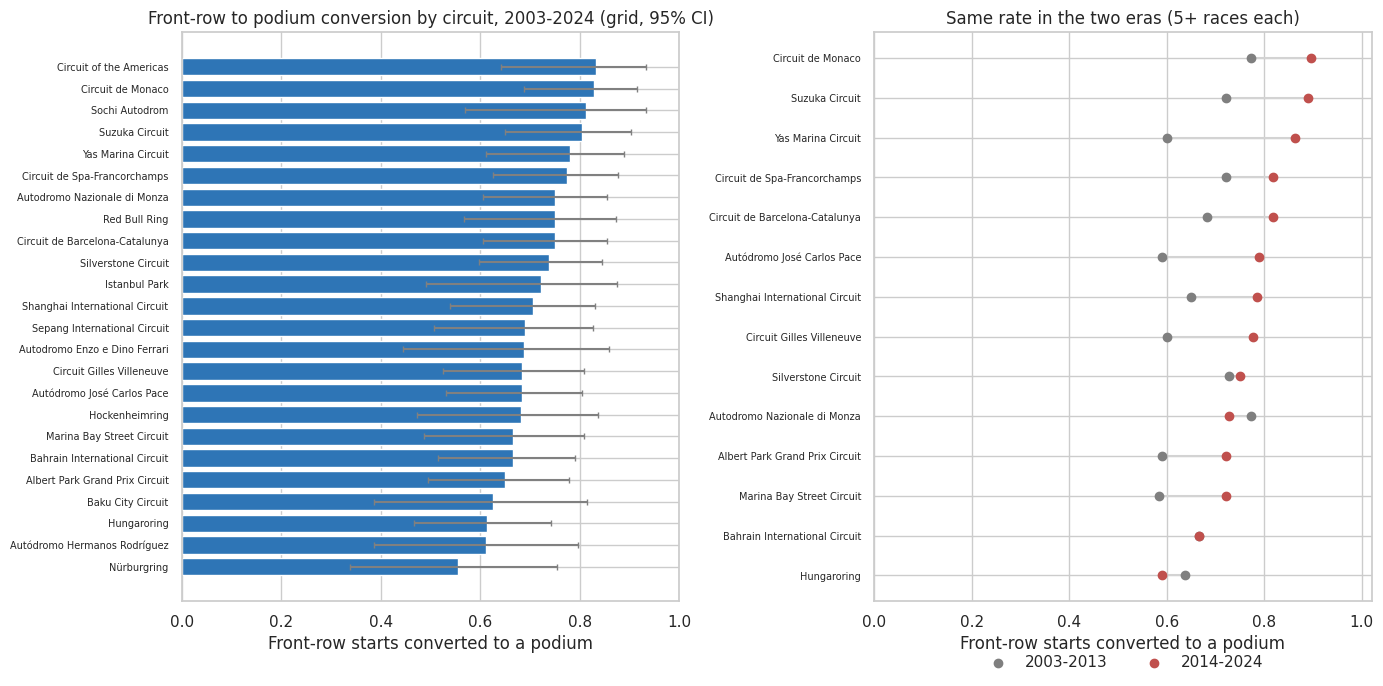

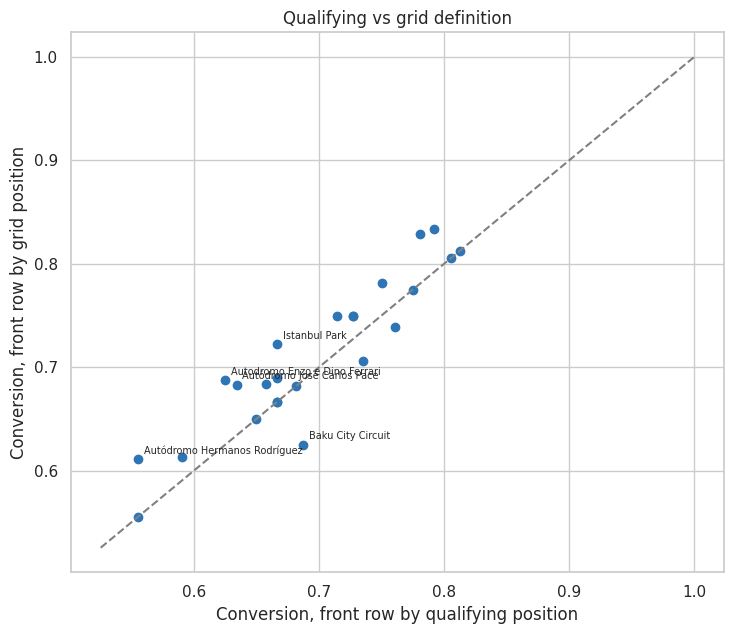

Q1 answer (grid definition, 2003-2024):
  highest: Circuit of the Americas 83%; Circuit de Monaco 83%; Sochi Autodrom 81%
  lowest:  Hungaroring 61%; Autódromo Hermanos Rodríguez 61%; Nürburgring 56%
  largest drop after 2014: Autodromo Nazionale di Monza -5%; Hungaroring -5%
  largest rise after 2014: Yas Marina Circuit +26%; Autódromo José Carlos Pace +20%; Circuit Gilles Villeneuve +18%
  era rank correlation rho=0.36


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
d = ov_grid.iloc[::-1]
axes[0].barh(d["circuit"], d["rate"], xerr=[d["rate"] - d["lo"], d["hi"] - d["rate"]],
             color="#2e75b6", ecolor="grey", capsize=2)
axes[0].set_xlim(0, 1)
axes[0].set_title("Front-row to podium conversion by circuit, 2003-2024 (grid, 95% CI)")
axes[0].tick_params(axis="y", labelsize=7)

ws = era_grid.sort_values("rate_post")
y = np.arange(len(ws))
axes[1].hlines(y, ws["rate_pre"], ws["rate_post"], color="lightgrey")
axes[1].scatter(ws["rate_pre"], y, color="#7f7f7f", label="2003-2013", zorder=3)
axes[1].scatter(ws["rate_post"], y, color="#c0504d", label="2014-2024", zorder=3)
axes[1].set_yticks(y)
axes[1].set_yticklabels(ws.index, fontsize=7)
axes[1].set_xlim(0, 1.02)
axes[1].set_title("Same rate in the two eras (5+ races each)")
axes[0].set_xlabel("Front-row starts converted to a podium")
axes[1].set_xlabel("Front-row starts converted to a podium")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, frameon=False)
save_show(fig, "s2_q1_circuit_conversion")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(cmp_ov["rate_qual"], cmp_ov["rate_grid"], color="#2e75b6")
lim = [min(cmp_ov[["rate_qual", "rate_grid"]].min()) - 0.03, 1.0]
ax.plot(lim, lim, color="grey", ls="--")
for _, r in cmp_ov.reindex(cmp_ov["gap_grid_minus_qual"].abs().sort_values(ascending=False).index).head(5).iterrows():
    ax.annotate(r["circuit"], (r["rate_qual"], r["rate_grid"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Conversion, front row by qualifying position")
ax.set_ylabel("Conversion, front row by grid position")
ax.set_title("Qualifying vs grid definition")
save_show(fig, "s2_q1_qual_vs_grid")

top3 = ov_grid.head(3)[["circuit", "rate"]].values
bot3 = ov_grid.tail(3)[["circuit", "rate"]].values
movers = era_grid["delta"].sort_values()
print("Q1 answer (grid definition, 2003-2024):")
print("  highest:", "; ".join(f"{c} {r:.0%}" for c, r in top3))
print("  lowest: ", "; ".join(f"{c} {r:.0%}" for c, r in bot3))
drops, rises = movers[movers < 0], movers[movers > 0]
print("  largest drop after 2014:", "; ".join(f"{c} {v:+.0%}" for c, v in drops.head(3).items()) or "none")
print("  largest rise after 2014:", "; ".join(f"{c} {v:+.0%}" for c, v in rises.tail(3)[::-1].items()) or "none")
print(f"  era rank correlation rho={rho_g.statistic:.2f}")

In [20]:
def era_table(df, flag):
    f = df[df[flag]]
    t = f.groupby("era")["podium"].agg(["size", "sum"]).rename(columns={"size": "starts", "sum": "podiums"})
    t["rate"] = t["podiums"] / t["starts"]
    t["lo"], t["hi"] = wilson(t["podiums"], t["starts"])
    return t

q1_era = {}
for label, flag in [("grid", "front_grid"), ("qualifying", "front_q")]:
    t = era_table(q1, flag)
    q1_era[label] = t
    pre, post = t.loc["2003-2013"], t.loc["2014-2024"]
    p_f = stats.fisher_exact([[int(post["podiums"]), int(post["starts"] - post["podiums"])],
                              [int(pre["podiums"]), int(pre["starts"] - pre["podiums"])]])[1]
    q1_era[label + "_p"] = float(p_f)
    print(f"Front-row conversion by era, {label} definition:")
    display(t.round(3))
    print(f"  change {100 * (post['rate'] - pre['rate']):+.1f} pp, Fisher exact p={p_f:.4g}\n")

n_up, n_down = int((era_grid["delta"] > 0).sum()), int((era_grid["delta"] < 0).sum())
q1_sign_p = float(stats.binomtest(n_up, n_up + n_down, 0.5).pvalue) if n_up + n_down else float("nan")
q1_updown = (n_up, n_down, len(era_grid), float(era_grid["delta"].mean()))
print(f"Circuits with 5+ races in both eras: {len(era_grid)}. Rose: {n_up}, fell: {n_down}, "
      f"flat: {len(era_grid) - n_up - n_down}. Mean change {100 * era_grid['delta'].mean():+.1f} pp, "
      f"sign test p={q1_sign_p:.3f}")

Front-row conversion by era, grid definition:


,starts,podiums,rate,lo,hi
era,,,,,
2003-2013,398,272,0.683,0.636,0.727
2014-2024,453,345,0.762,0.720,0.799


  change +7.8 pp, Fisher exact p=0.01123

Front-row conversion by era, qualifying definition:


,starts,podiums,rate,lo,hi
era,,,,,
2003-2013,398,269,0.676,0.628,0.720
2014-2024,454,336,0.740,0.698,0.778


  change +6.4 pp, Fisher exact p=0.04127

Circuits with 5+ races in both eras: 14. Rose: 11, fell: 2, flat: 1. Mean change +10.7 pp, sign test p=0.022


Grain, missingness and cutoff for Q1: one row per driver per race, taken from the cleaned `base`. About 0.2% of 2003-2024 rows have no qualifying record and are dropped from this question. Qualifying position and grid are both known before the lights go out, and the podium is the outcome we count, so no post-race information is used as a condition.

## 2.2 Question 2: do drivers podium more often at home, after controlling for grid position?

Join path: `base` with `drivers` (nationality) and, through `races.circuitId`, with `circuits` (country). A driver is at home when their nationality maps to the circuit's country. Compound nationalities such as `Argentine-Italian` count as home in either country.

Two controls for grid position:
1. Direct standardisation: compare home podium rate with the rate home drivers would get if they converted like away drivers from the same grid bins.
2. A logistic regression of podium on a home flag, grid bin and decade, with standard errors clustered by driver, since the same driver appears in many races. The adjusted difference is the average change in podium probability when the home flag is switched on.

The main sample is every season where the mapping works. 2003 onward is a robustness check.

In [21]:
CANON = {"uk": "UK", "united kingdom": "UK", "great britain": "UK", "usa": "USA", "united states": "USA",
         "uae": "UAE", "united arab emirates": "UAE", "korea": "South Korea", "south korea": "South Korea"}
def canon(s):
    return CANON.get(str(s).strip().lower(), str(s).strip())

NAT_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Argentinian": "Argentina", "Australian": "Australia",
    "Austrian": "Austria", "Singaporean": "Singapore",
    "Azerbaijani": "Azerbaijan", "Bahraini": "Bahrain", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chinese": "China", "Dutch": "Netherlands", "Emirati": "UAE",
    "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Italian": "Italy",
    "Japanese": "Japan", "Korean": "South Korea", "Malaysian": "Malaysia", "Mexican": "Mexico",
    "Monegasque": "Monaco", "Moroccan": "Morocco", "Portuguese": "Portugal", "Qatari": "Qatar",
    "Russian": "Russia", "Saudi": "Saudi Arabia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland", "Turkish": "Turkey",
}
NAT_CANON = {k: canon(v) for k, v in NAT_TO_COUNTRY.items()}

drv_nat = T["drivers"][["driverId", "nationality"]]
q2 = base.merge(drv_nat, on="driverId", how="left").merge(circ[["circuitId", "country"]], on="circuitId", how="left")
q2["country"] = q2["country"].map(canon)

pairs = q2[["nationality", "country"]].drop_duplicates().copy()
pairs["home"] = [int(any(NAT_CANON.get(p.strip()) == c for p in str(n).split("-")))
                 for n, c in zip(pairs["nationality"], pairs["country"])]
q2 = q2.merge(pairs, on=["nationality", "country"], how="left")

circuit_countries = set(q2["country"].dropna())
mapped_countries = set(NAT_CANON.values())
print("Circuit countries with no nationality mapping:", sorted(circuit_countries - mapped_countries))
NO_CIRCUIT = {"Finnish", "Danish", "Polish", "Czech", "Colombian", "Venezuelan", "Chilean", "Uruguayan",
              "Indonesian", "Thai", "New Zealander", "Irish", "Rhodesian", "Liechtensteiner", "Hong Kong",
              "East German"}   # nationalities whose country never hosted a race in this data, so they can never be home
unmapped = q2[~q2["nationality"].fillna("").map(lambda s: any(p.strip() in NAT_CANON for p in s.split("-")))]
print("Nationalities with no circuit country (never home):",
      unmapped.loc[unmapped["nationality"].isin(NO_CIRCUIT), "nationality"].value_counts().to_dict())
print("UNEXPECTED nationalities missing from the mapping (rows):",
      unmapped.loc[~unmapped["nationality"].isin(NO_CIRCUIT), "nationality"].value_counts().to_dict())

review = (q2.groupby("nationality").agg(drivers=("driverId", "nunique"), rows=("resultId", "size"),
                                        home_rows=("home", "sum")).sort_values("rows", ascending=False))
review["maps_to"] = [", ".join(sorted({NAT_CANON[p.strip()] for p in str(n).split("-") if p.strip() in NAT_CANON}))
                     or "no circuit country" for n in review.index]
print("\nNationality mapping review (every nationality in the modeling table):")
display(review)
cc = q2.groupby("country").agg(races=("raceId", "nunique"), home_rows=("home", "sum")).sort_values("races", ascending=False)
print("Circuit countries, races held and home starts found:")
display(cc)
print(f"\nHome rows: {int(q2['home'].sum())} of {len(q2)} ({q2['home'].mean():.1%}), "
      f"{q2.loc[q2.home == 1, 'driverId'].nunique()} drivers, {q2.loc[q2.home == 1, 'circuitId'].nunique()} circuits")
print("Home rows by nationality (top 8):", q2.loc[q2.home == 1, "nationality"].value_counts().head(8).to_dict())
print(f"Raw podium rate: home {q2.loc[q2.home == 1, 'podium'].mean():.2%}, away {q2.loc[q2.home == 0, 'podium'].mean():.2%}")

Circuit countries with no nationality mapping: []
Nationalities with no circuit country (never home): {'Finnish': 1155, 'New Zealander': 386, 'Danish': 217, 'Thai': 123, 'Colombian': 115, 'Venezuelan': 114, 'Polish': 99, 'Irish': 67, 'Chilean': 24, 'Rhodesian': 14, 'Indonesian': 12, 'Liechtensteiner': 10, 'Uruguayan': 6, 'East German': 5, 'Czech': 3}
UNEXPECTED nationalities missing from the mapping (rows): {}

Nationality mapping review (every nationality in the modeling table):


,drivers,rows,home_rows,maps_to
nationality,,,,
British,151,4273,446,UK
Italian,83,3000,399,Italy
French,71,2915,206,France
German,45,2314,199,Germany
Brazilian,32,1849,114,Brazil
Finnish,8,1155,0,no circuit country
Spanish,13,878,60,Spain
Australian,16,866,28,Australia
American,49,835,112,USA


Circuit countries, races held and home starts found:


,races,home_rows
country,,
Italy,107,400
Germany,79,199
UK,79,446
Monaco,70,8
Belgium,69,60
USA,68,112
France,63,206
Spain,61,60
Canada,53,32



Home rows: 1927 of 24586 (7.8%), 499 drivers, 67 circuits
Home rows by nationality (top 8): {'British': 446, 'Italian': 399, 'French': 206, 'German': 199, 'Brazilian': 114, 'American': 112, 'Belgian': 60, 'Spanish': 60}
Raw podium rate: home 11.62%, away 13.76%


In [22]:
GBINS = [0, 1, 2, 3, 6, 10, 15, 100]
GLABELS = ["P1", "P2", "P3", "P4-6", "P7-10", "P11-15", "P16+"]
q2["gbin"] = pd.cut(q2["grid_clean"], bins=GBINS, labels=GLABELS)

def standardise(d):
    t = d.groupby(["gbin", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home")
    share_home = t[("size", 1)] / t[("size", 1)].sum()
    expected = float((share_home * t[("mean", 0)]).sum())
    actual = float(d.loc[d.home == 1, "podium"].mean())
    return t, actual, expected

def fit_home(d, label):
    d = d.copy()
    d["decade"] = (d["year"] // 10 * 10).astype(str)
    d["gbin_s"] = d["gbin"].astype(str)      # text columns are treated as categories without calling C(), which a notebook variable could shadow
    m = smf.logit("podium ~ home + gbin_s + decade", data=d).fit(
        disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": d["driverId"]})
    ci = m.conf_int().loc["home"]
    p1 = m.predict(d.assign(home=1)).mean()
    p0 = m.predict(d.assign(home=0)).mean()
    return {"sample": label, "rows": len(d), "home_rows": int(d["home"].sum()),
            "odds_ratio": float(np.exp(m.params["home"])), "or_lo": float(np.exp(ci[0])), "or_hi": float(np.exp(ci[1])),
            "p_value": float(m.pvalues["home"]), "adj_diff_pp": float(100 * (p1 - p0))}

samples = {"all seasons": q2, "2003 onward": q2[q2["year"] >= 2003]}
rows = []
for label, d in samples.items():
    t, actual, expected = standardise(d)
    print(f"[{label}] home podium rate {actual:.2%}; expected if converting like away drivers from the same grid bins "
          f"{expected:.2%}; standardised difference {100 * (actual - expected):+.2f} pp")
    rows.append(fit_home(d, label))

print("\nGrid-bin table, all seasons (mean = podium rate, size = rows):")
t_all, _, _ = standardise(q2)
display(t_all.round(3))
reg = pd.DataFrame(rows)
print("Logistic regression: podium ~ home + grid bin + decade (SE clustered by driver)")
display(reg.round(3))

# Within-driver check: how much better than the grid-only expectation does each driver do at home?
d0 = q2.copy()
d0["decade"] = (d0["year"] // 10 * 10).astype(str)
d0["gbin_s"] = d0["gbin"].astype(str)
m0 = smf.logit("podium ~ gbin_s + decade", data=d0).fit(disp=0, maxiter=200)
d0["resid"] = d0["podium"] - m0.predict(d0)
per = d0.groupby(["driverId", "home"])["resid"].agg(["mean", "size"]).unstack("home")
per.columns = [f"{a}_{'home' if b == 1 else 'away'}" for a, b in per.columns]
elig = per[(per["size_home"] >= 3) & (per["size_away"] >= 3)].copy()
elig["diff"] = elig["mean_home"] - elig["mean_away"]
dv = elig["diff"].to_numpy()
boot = np.random.default_rng(SEED).choice(dv, size=(5000, len(dv)), replace=True).mean(axis=1)
within_mean, within_lo, within_hi = float(dv.mean()), *np.percentile(boot, [2.5, 97.5])
within_p = float(stats.wilcoxon(dv).pvalue)
print(f"\nWithin-driver check ({len(dv)} drivers with 3+ home and 3+ away starts): mean podium gain over the "
      f"grid-only expectation at home vs away = {100 * within_mean:+.1f} pp "
      f"(bootstrap 95% CI {100 * within_lo:+.1f} to {100 * within_hi:+.1f}, Wilcoxon p={within_p:.3f})")

[all seasons] home podium rate 11.62%; expected if converting like away drivers from the same grid bins 12.27%; standardised difference -0.64 pp
[2003 onward] home podium rate 14.29%; expected if converting like away drivers from the same grid bins 16.26%; standardised difference -1.97 pp

Grid-bin table, all seasons (mean = podium rate, size = rows):


mean         size     
home        0      1     0    1
gbin                           
P1      0.645  0.590  1036   83
P2      0.562  0.545  1032   77
P3      0.459  0.529  1039   70
P4-6    0.261  0.265  3108  226
P7-10   0.093  0.072  4094  335
P11-15  0.030  0.024  5094  414
P16+    0.007  0.003  7256  722

Logistic regression: podium ~ home + grid bin + decade (SE clustered by driver)


,sample,rows,home_rows,odds_ratio,or_lo,or_hi,p_value,adj_diff_pp
0,all seasons,24586,1927,0.919,0.749,1.128,0.418,-0.688
1,2003 onward,8910,364,0.760,0.398,1.451,0.405,-1.926



Within-driver check (191 drivers with 3+ home and 3+ away starts): mean podium gain over the grid-only expectation at home vs away = -0.3 pp (bootstrap 95% CI -1.9 to +1.3, Wilcoxon p=0.133)


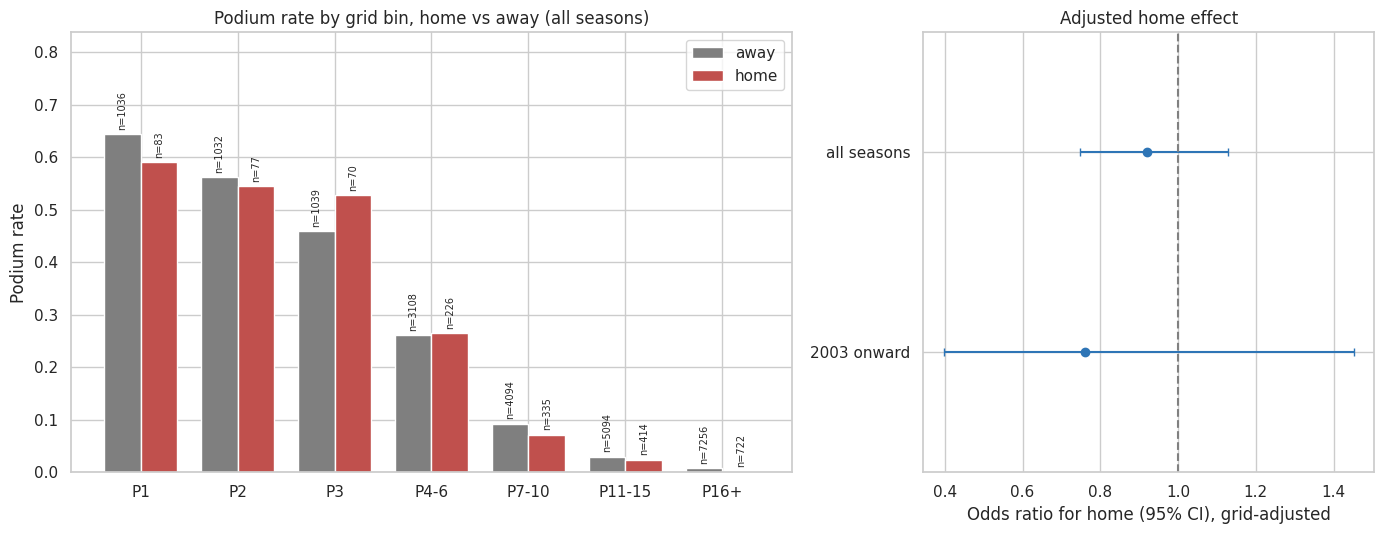

Q2 answer:
  all seasons: adjusted odds ratio 0.92 (95% CI 0.75 to 1.13), adjusted difference -0.7 pp, p=0.418
  2003 onward: odds ratio 0.76 (95% CI 0.40 to 1.45), adjusted difference -1.9 pp, p=0.405
  within-driver: -0.3 pp (95% CI -1.9 to +1.3)


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
t, _, _ = standardise(q2)
x = np.arange(len(t))
w = 0.38
axes[0].bar(x - w / 2, t[("mean", 0)], w, label="away", color="#7f7f7f")
axes[0].bar(x + w / 2, t[("mean", 1)], w, label="home", color="#c0504d")
for i, (m0, m1, n0, n1) in enumerate(zip(t[("mean", 0)], t[("mean", 1)], t[("size", 0)], t[("size", 1)])):
    axes[0].text(i - w / 2, m0 + 0.008, f"n={int(n0)}", rotation=90, fontsize=7, va="bottom", ha="center")
    axes[0].text(i + w / 2, m1 + 0.008, f"n={int(n1)}", rotation=90, fontsize=7, va="bottom", ha="center")
axes[0].set_ylim(0, max(t[("mean", 0)].max(), t[("mean", 1)].max()) * 1.3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(t.index.astype(str))
axes[0].set_ylabel("Podium rate")
axes[0].set_title("Podium rate by grid bin, home vs away (all seasons)")
axes[0].legend()

yy = np.arange(len(reg))[::-1]
axes[1].errorbar(reg["odds_ratio"], yy, xerr=[reg["odds_ratio"] - reg["or_lo"], reg["or_hi"] - reg["odds_ratio"]],
                 fmt="o", color="#2e75b6", capsize=3)
axes[1].axvline(1, color="grey", ls="--")
axes[1].set_yticks(yy)
axes[1].set_yticklabels(reg["sample"])
axes[1].set_ylim(-0.6, len(reg) - 0.4)
axes[1].set_xlabel("Odds ratio for home (95% CI), grid-adjusted")
axes[1].set_title("Adjusted home effect")
save_show(fig, "s2_q2_home_race")

r_all = reg.iloc[0]
print("Q2 answer:")
print(f"  all seasons: adjusted odds ratio {r_all.odds_ratio:.2f} (95% CI {r_all.or_lo:.2f} to {r_all.or_hi:.2f}), "
      f"adjusted difference {r_all.adj_diff_pp:+.1f} pp, p={r_all.p_value:.3f}")
r_mod = reg.iloc[1]
print(f"  2003 onward: odds ratio {r_mod.odds_ratio:.2f} (95% CI {r_mod.or_lo:.2f} to {r_mod.or_hi:.2f}), "
      f"adjusted difference {r_mod.adj_diff_pp:+.1f} pp, p={r_mod.p_value:.3f}")
print(f"  within-driver: {100 * within_mean:+.1f} pp (95% CI {100 * within_lo:+.1f} to {100 * within_hi:+.1f})")

Grain, missingness and cutoff for Q2: one row per driver per race from `base`. The home flag depends only on nationality and circuit country, both known long before the race, so it is a valid pre-race feature as well as an analysis variable. The mapping is the main missingness risk: any nationality without a circuit country can never be home, and the unmapped list printed above shows what that affects. Limitations: car quality is not controlled (grid position absorbs part of it), and a few home drivers who were also dominant, such as British and Brazilian champions, can drive the result, so the estimate describes association and not a causal home advantage.

## 2.3 Question 3: which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?

Join path: `base` (race starts only, since non-starters are already removed) with `status` through `statusId`, and with `constructors` through `constructorId`.

A mechanical retirement is a race start that ended early because a component of the car failed. It excludes crashes, driver causes and regulation decisions. The 139 status values are grouped into five categories:

- `finished`: Finished and every "+N Laps".
- `mech_core`: clear component failures (engine, gearbox, hydraulics, brakes, electrical, power unit, cooling and similar). This is the primary definition.
- `mech_ambiguous`: component-related but plausibly caused by contact or debris (tyres, punctures, wings, wheel, undertray, fire, stalled, out of fuel, handling and similar). Used only in a sensitivity check.
- `accident`: accident, collision, spun off, collision damage.
- `other`: disqualified, excluded, withdrawn, medical and other regulation or non-car causes.

Constructors that were renamed are merged into one lineage for this question only (for example Toro Rosso, AlphaTauri and RB), because reliability belongs to the team rather than the name. The lineage mapping is printed for review.

The status column is a post-race outcome, so this analysis uses it as the thing being measured and it is never a model feature.

In [24]:
FINISHED_RE = r"^(Finished|\+\d+ Laps?)$"
MECH_CORE = {
    "Engine", "Gearbox", "Suspension", "Transmission", "Electrical", "Brakes", "Clutch", "Fuel system", "Turbo",
    "Hydraulics", "Overheating", "Ignition", "Oil leak", "Throttle", "Halfshaft", "Oil pressure", "Fuel pump",
    "Differential", "Steering", "Radiator", "Power Unit", "Wheel bearing", "Injection", "Fuel pressure",
    "Water leak", "Alternator", "Exhaust", "Chassis", "Mechanical", "Magneto", "Driveshaft", "Axle",
    "Heat shield fire", "Battery", "Power loss", "Distributor", "Oil pump", "Oil pipe", "Electronics",
    "Vibrations", "Water pressure", "Water pump", "Technical", "Pneumatics", "ERS", "Supercharger",
    "Spark plugs", "Fuel pipe", "Water pipe", "Track rod", "Oil line", "Drivetrain", "Engine misfire",
    "Engine fire", "Crankshaft", "CV joint", "Brake duct", "Cooling system", "Launch control", "Fuel",
}
MECH_AMBIG = {
    "Wheel", "Wheel nut", "Wheel rim", "Tyre", "Puncture", "Tyre puncture", "Broken wing", "Rear wing",
    "Front wing", "Undertray", "Damage", "Debris", "Handling", "Fire", "Stalled", "Out of fuel",
    "Driver Seat", "Seat", "Safety belt", "Fuel rig",
}
ACCIDENT = {"Accident", "Collision", "Spun off", "Collision damage", "Fatal accident"}

def categorize(name):
    if pd.Series([name]).str.match(FINISHED_RE).iloc[0]:
        return "finished"
    if name in MECH_CORE:
        return "mech_core"
    if name in MECH_AMBIG:
        return "mech_ambiguous"
    if name in ACCIDENT:
        return "accident"
    return "other"

status_cat = T["status"][["statusId", "status"]].copy()
status_cat["cat"] = status_cat["status"].map(categorize)

LINEAGE = {
    "Toro Rosso": "RB (Toro Rosso, AlphaTauri, RB)", "AlphaTauri": "RB (Toro Rosso, AlphaTauri, RB)",
    "RB F1 Team": "RB (Toro Rosso, AlphaTauri, RB)",
    "Force India": "Aston Martin (Force India, Racing Point)", "Racing Point": "Aston Martin (Force India, Racing Point)",
    "Aston Martin": "Aston Martin (Force India, Racing Point)",
    "Lotus F1": "Alpine (Lotus, Renault, Alpine)", "Renault": "Alpine (Lotus, Renault, Alpine)",
    "Alpine F1 Team": "Alpine (Lotus, Renault, Alpine)",
    "Sauber": "Sauber (Sauber, Alfa Romeo)", "Alfa Romeo": "Sauber (Sauber, Alfa Romeo)",
    "Kick Sauber": "Sauber (Sauber, Alfa Romeo)",
    "Marussia": "Marussia (Marussia, Manor)", "Manor Marussia": "Marussia (Marussia, Manor)",
}
cons = T["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})

q3 = (base[base["year"] >= 2014]
      .merge(status_cat[["statusId", "status", "cat"]], on="statusId", how="left")
      .merge(cons, on="constructorId", how="left"))
q3["lineage"] = q3["constructor"].map(lambda n: LINEAGE.get(n, n))
q3["era3"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
q3["mech_core"] = (q3["cat"] == "mech_core").astype(int)
q3["mech_broad"] = q3["cat"].isin(["mech_core", "mech_ambiguous"]).astype(int)
assert q3["cat"].notna().all()

print("Status grouping, 2014-2024 starts in brackets (every status with at least one start):")
cnt = q3["status"].value_counts()
for cat in ["finished", "mech_core", "mech_ambiguous", "accident", "other"]:
    names = [f"{s} ({cnt[s]})" for s in status_cat.loc[status_cat.cat == cat, "status"] if s in cnt.index]
    print(f"\n{cat} [{sum(cnt[s] for s in status_cat.loc[status_cat.cat == cat, 'status'] if s in cnt.index)} starts]:")
    print("  " + ", ".join(names if cat != "finished" else ["Finished and +N Laps"]))
print("\nStatus values never used in 2014-2024 (not shown above):",
      int((~status_cat["status"].isin(cnt.index)).sum()), "of", len(status_cat))

ns14 = ns[ns["year"] >= 2014]
print("\nNon-starters 2014-2024 excluded by rule R2 (not race starts), by status group:",
      ns14["status"].map(categorize).value_counts().to_dict())

print("\nLineage mapping applied (constructor names seen 2014-2024 -> lineage, starts):")
lin = q3.groupby(["lineage", "constructor"]).size().rename("starts").reset_index()
display(lin[lin["lineage"] != lin["constructor"]])

Status grouping, 2014-2024 starts in brackets (every status with at least one start):

finished [3825 starts]:
  Finished and +N Laps

mech_core [361 starts]:
  Engine (79), Gearbox (40), Transmission (3), Clutch (2), Hydraulics (14), Electrical (14), Radiator (3), Suspension (25), Brakes (48), Differential (1), Overheating (8), Mechanical (7), Driveshaft (1), Fuel pressure (5), Water pressure (7), Throttle (2), Steering (2), Technical (2), Electronics (4), Exhaust (4), Oil leak (10), Water leak (4), Fuel pump (1), Oil pressure (2), Power loss (12), Vibrations (2), Drivetrain (1), Battery (5), Turbo (6), Water pump (1), Spark plugs (1), Power Unit (39), ERS (4), Brake duct (1), Cooling system (1)

mech_ambiguous [40 starts]:
  Tyre (4), Puncture (7), Front wing (3), Wheel (11), Out of fuel (1), Wheel nut (3), Rear wing (3), Seat (1), Damage (2), Debris (1), Undertray (4)

accident [305 starts]:
  Accident (85), Collision (150), Spun off (11), Collision damage (59)

other [67 starts]:
 

,lineage,constructor,starts
0,"Alpine (Lotus, Renault, Alpine)",Alpine F1 Team,179
1,"Alpine (Lotus, Renault, Alpine)",Lotus F1,75
2,"Alpine (Lotus, Renault, Alpine)",Renault,199
3,"Aston Martin (Force India, Racing Point)",Aston Martin,178
4,"Aston Martin (Force India, Racing Point)",Force India,198
5,"Aston Martin (Force India, Racing Point)",Racing Point,75
9,"Marussia (Marussia, Manor)",Manor Marussia,77
10,"Marussia (Marussia, Manor)",Marussia,31
13,"RB (Toro Rosso, AlphaTauri, RB)",AlphaTauri,165
14,"RB (Toro Rosso, AlphaTauri, RB)",RB F1 Team,48


In [25]:
MIN_STARTS = 60
agg = q3.groupby(["lineage", "era3"]).agg(starts=("podium", "size"), core=("mech_core", "sum"),
                                         broad=("mech_broad", "sum")).reset_index()
agg["rate_core"] = agg["core"] / agg["starts"]
agg["rate_broad"] = agg["broad"] / agg["starts"]
agg["lo"], agg["hi"] = wilson(agg["core"], agg["starts"])

overall_era = q3.groupby("era3").agg(starts=("podium", "size"), core=("mech_core", "sum"), broad=("mech_broad", "sum"))
overall_era["rate_core"] = overall_era["core"] / overall_era["starts"]
overall_era["rate_broad"] = overall_era["broad"] / overall_era["starts"]
print("All constructors pooled:")
display(overall_era.round(4))

for era in ["2014-2021", "2022-2024"]:
    e = agg[(agg["era3"] == era)].sort_values("rate_core", ascending=False)
    print(f"Mechanical-retirement rate by constructor lineage, {era} (core definition):")
    display(e[["lineage", "starts", "core", "rate_core", "lo", "hi", "rate_broad"]].round(3).reset_index(drop=True))

wide3 = agg.pivot(index="lineage", columns="era3", values=["starts", "rate_core", "rate_broad"])
wide3.columns = [f"{a}_{b}" for a, b in wide3.columns]
both = wide3.dropna()
both = both[(both["starts_2014-2021"] >= MIN_STARTS) & (both["starts_2022-2024"] >= MIN_STARTS)].copy()
both["delta_core"] = both["rate_core_2022-2024"] - both["rate_core_2014-2021"]
print(f"Lineages with {MIN_STARTS}+ starts in both eras ({len(both)}):")
display(both.sort_values("delta_core").round(3))
rho3 = stats.spearmanr(both["rate_core_2014-2021"], both["rate_broad_2014-2021"])
rho3b = stats.spearmanr(both["rate_core_2022-2024"], both["rate_broad_2022-2024"])
print(f"Sensitivity, rank correlation core vs broad definition: 2014-2021 rho={rho3.statistic:.2f}, "
      f"2022-2024 rho={rho3b.statistic:.2f}")

from statsmodels.stats.multitest import multipletests
cnt = agg.pivot(index="lineage", columns="era3", values=["starts", "core"])
rows_ = []
for name_ in both.index:
    n1, k1 = int(cnt.loc[name_, ("starts", "2014-2021")]), int(cnt.loc[name_, ("core", "2014-2021")])
    n2, k2 = int(cnt.loc[name_, ("starts", "2022-2024")]), int(cnt.loc[name_, ("core", "2022-2024")])
    rows_.append((name_, k1 / n1, k2 / n2, stats.fisher_exact([[k2, n2 - k2], [k1, n1 - k1]])[1]))
q3_change = pd.DataFrame(rows_, columns=["lineage", "rate_early", "rate_late", "p_raw"]).set_index("lineage")
q3_change["p_holm"] = multipletests(q3_change["p_raw"], method="holm")[1]
q3_change["change_pp"] = 100 * (q3_change["rate_late"] - q3_change["rate_early"])
print("\nChange in mechanical-retirement rate per lineage, Fisher exact test "
      "(Holm adjusts for the number of teams compared):")
display(q3_change.sort_values("change_pp")[["rate_early", "rate_late", "change_pp", "p_raw", "p_holm"]].round(4))
pe, pl = overall_era.loc["2014-2021"], overall_era.loc["2022-2024"]
q3_pool_p = float(stats.fisher_exact([[int(pl["core"]), int(pl["starts"] - pl["core"])],
                                      [int(pe["core"]), int(pe["starts"] - pe["core"])]])[1])
print(f"Pooled rate {pe['rate_core']:.2%} -> {pl['rate_core']:.2%}, Fisher exact p={q3_pool_p:.2g}")

All constructors pooled:


,starts,core,broad,rate_core,rate_broad
era3,,,,,
2014-2021,3246,288,322,0.0887,0.0992
2022-2024,1352,73,79,0.0540,0.0584


Mechanical-retirement rate by constructor lineage, 2014-2021 (core definition):


,lineage,starts,core,rate_core,lo,hi,rate_broad
0,Caterham,33,7,0.212,0.107,0.378,0.212
1,"RB (Toro Rosso, AlphaTauri, RB)",319,46,0.144,0.110,0.187,0.147
2,"Alpine (Lotus, Renault, Alpine)",318,42,0.132,0.099,0.174,0.154
3,McLaren,316,41,0.130,0.097,0.171,0.136
4,Red Bull,318,34,0.107,0.078,0.146,0.113
5,"Sauber (Sauber, Alfa Romeo)",319,25,0.078,0.054,0.113,0.085
6,Haas F1 Team,241,18,0.075,0.048,0.115,0.095
7,Williams,319,23,0.072,0.049,0.106,0.085
8,"Marussia (Marussia, Manor)",108,7,0.065,0.032,0.128,0.065
9,"Aston Martin (Force India, Racing Point)",317,18,0.057,0.036,0.088,0.066


Mechanical-retirement rate by constructor lineage, 2022-2024 (core definition):


...

Lineages with 60+ starts in both eras (10):


,starts_2014-2021,starts_2022-2024,rate_core_2014-2021,rate_core_2022-2024,rate_broad_2014-2021,rate_broad_2022-2024,delta_core
lineage,,,,,,,
McLaren,316.0,136.0,0.130,0.037,0.136,0.037,-0.093
"RB (Toro Rosso, AlphaTauri, RB)",319.0,136.0,0.144,0.059,0.147,0.066,-0.085
Red Bull,318.0,136.0,0.107,0.029,0.113,0.029,-0.078
Haas F1 Team,241.0,135.0,0.075,0.044,0.095,0.052,-0.030
"Alpine (Lotus, Renault, Alpine)",318.0,135.0,0.132,0.104,0.154,0.104,-0.028
Williams,319.0,134.0,0.072,0.052,0.085,0.060,-0.020
"Aston Martin (Force India, Racing Point)",317.0,134.0,0.057,0.037,0.066,0.052,-0.019
Ferrari,318.0,134.0,0.047,0.045,0.063,0.052,-0.002
Mercedes,320.0,136.0,0.038,0.044,0.047,0.044,0.007


Sensitivity, rank correlation core vs broad definition: 2014-2021 rho=0.97, 2022-2024 rho=0.95

Change in mechanical-retirement rate per lineage, Fisher exact test (Holm adjusts for the number of teams compared):


,rate_early,rate_late,change_pp,p_raw,p_holm
lineage,,,,,
McLaren,0.1297,0.0368,-9.2982,0.0020,0.0201
"RB (Toro Rosso, AlphaTauri, RB)",0.1442,0.0588,-8.5377,0.0107,0.0855
Red Bull,0.1069,0.0294,-7.7506,0.0051,0.0459
Haas F1 Team,0.0747,0.0444,-3.0244,0.2805,1.0000
"Alpine (Lotus, Renault, Alpine)",0.1321,0.1037,-2.8372,0.4393,1.0000
Williams,0.0721,0.0522,-1.9862,0.5374,1.0000
"Aston Martin (Force India, Racing Point)",0.0568,0.0373,-1.9469,0.4870,1.0000
Ferrari,0.0472,0.0448,-0.2394,1.0000,1.0000
Mercedes,0.0375,0.0441,0.6618,0.7938,1.0000


Pooled rate 8.87% -> 5.40%, Fisher exact p=5.2e-05


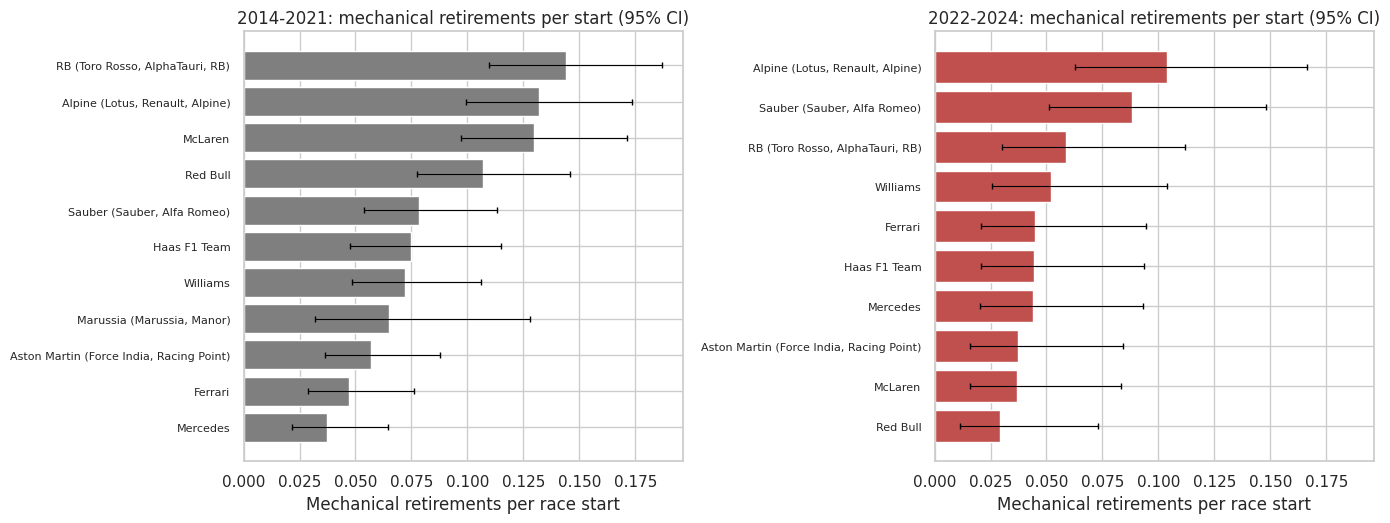

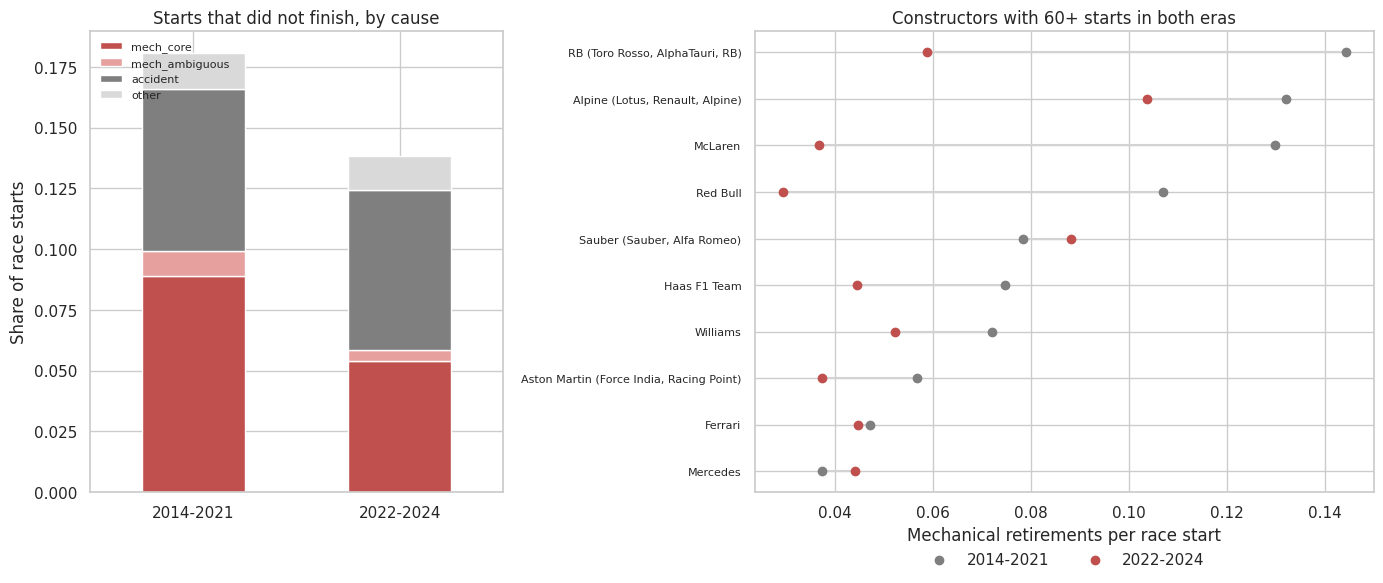

Q3 answer (core definition):
  2014-2021 highest: RB (Toro Rosso, AlphaTauri, RB) 14.4%; Alpine (Lotus, Renault, Alpine) 13.2%; McLaren 13.0%
  2014-2021 lowest:  Aston Martin (Force India, Racing Point) 5.7%; Ferrari 4.7%; Mercedes 3.8%
  2022-2024 highest: Alpine (Lotus, Renault, Alpine) 10.4%; Sauber (Sauber, Alfa Romeo) 8.8%; RB (Toro Rosso, AlphaTauri, RB) 5.9%
  2022-2024 lowest:  Aston Martin (Force India, Racing Point) 3.7%; McLaren 3.7%; Red Bull 2.9%
  overall rate 2014-2021: 8.9% -> 2022-2024: 5.4%
  biggest improvement: McLaren -9.3%; RB (Toro Rosso, AlphaTauri, RB) -8.5%
  biggest deterioration: Sauber (Sauber, Alfa Romeo) +1.0%; Mercedes +0.7%


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.45 * agg["lineage"].nunique())), sharex=True)
for ax, era, colour in zip(axes, ["2014-2021", "2022-2024"], ["#7f7f7f", "#c0504d"]):
    e = agg[(agg["era3"] == era) & (agg["starts"] >= MIN_STARTS)].sort_values("rate_core")
    ax.barh(e["lineage"], e["rate_core"], xerr=[e["rate_core"] - e["lo"], e["hi"] - e["rate_core"]],
            color=colour, ecolor="black", capsize=2, error_kw={"lw": 0.8})
    ax.set_title(f"{era}: mechanical retirements per start (95% CI)")
    ax.set_xlabel("Mechanical retirements per race start")
    ax.tick_params(axis="y", labelsize=8)
save_show(fig, "s2_q3_ranking")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.5]})
shares = (q3.groupby("era3")["cat"].value_counts(normalize=True).unstack()
          .reindex(columns=["mech_core", "mech_ambiguous", "accident", "other"]).fillna(0))
shares.plot(kind="bar", stacked=True, ax=axes[0], color=["#c0504d", "#e6a09e", "#7f7f7f", "#d9d9d9"], rot=0)
axes[0].set_xlabel("")
axes[0].set_ylabel("Share of race starts")
axes[0].set_title("Starts that did not finish, by cause")
axes[0].legend(fontsize=8, loc="upper left", frameon=False)

bs = both.sort_values("rate_core_2014-2021")
y = np.arange(len(bs))
axes[1].hlines(y, bs["rate_core_2014-2021"], bs["rate_core_2022-2024"], color="lightgrey")
axes[1].scatter(bs["rate_core_2014-2021"], y, color="#7f7f7f", label="2014-2021", zorder=3)
axes[1].scatter(bs["rate_core_2022-2024"], y, color="#c0504d", label="2022-2024", zorder=3)
axes[1].set_yticks(y)
axes[1].set_yticklabels(bs.index, fontsize=8)
axes[1].set_xlabel("Mechanical retirements per race start")
axes[1].set_title(f"Constructors with {MIN_STARTS}+ starts in both eras")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
save_show(fig, "s2_q3_mechanical_retirements")

print("Q3 answer (core definition):")
for era in ["2014-2021", "2022-2024"]:
    e = agg[(agg["era3"] == era) & (agg["starts"] >= MIN_STARTS)].sort_values("rate_core", ascending=False)
    print(f"  {era} highest:", "; ".join(f"{r.lineage} {r.rate_core:.1%}" for r in e.head(3).itertuples()))
    print(f"  {era} lowest: ", "; ".join(f"{r.lineage} {r.rate_core:.1%}" for r in e.tail(3).itertuples()))
print("  overall rate", " -> ".join(f"{e}: {overall_era.loc[e, 'rate_core']:.1%}" for e in overall_era.index))
dd = both["delta_core"].sort_values()
print("  biggest improvement:", "; ".join(f"{k} {v:+.1%}" for k, v in dd.head(2).items()))
print("  biggest deterioration:", "; ".join(f"{k} {v:+.1%}" for k, v in dd.tail(2)[::-1].items()))

### Sensitivity: plain "Retired" and "Fuel leak"

Two status values deserve a second look. `Retired` (49 starts in 2014-2024) is a generic label: the car stopped, but the data does not say why, and in the modern era it is often a car problem. `Fuel leak` is a component failure that the core list above missed, so it fell into `other`. Neither is moved into the core definition here, because the core definition also feeds the `con_mech_rate_20` model feature and every later result. Instead the ranking is recomputed with both counted as mechanical.

In [27]:
q3["mech_sens"] = ((q3["mech_core"] == 1) | q3["status"].isin(["Retired", "Fuel leak"])).astype(int)
print("Starts with status Retired or Fuel leak, by era:")
display(q3[q3["status"].isin(["Retired", "Fuel leak"])].groupby(["era3", "status"]).size().unstack(fill_value=0))

sens = q3.groupby(["lineage", "era3"]).agg(starts=("podium", "size"), core=("mech_core", "sum"),
                                           sens=("mech_sens", "sum")).reset_index()
sens = sens[sens["starts"] >= MIN_STARTS].copy()
sens["rate_core"] = sens["core"] / sens["starts"]
sens["rate_with_retired"] = sens["sens"] / sens["starts"]
Q3_SENS = {}
for era in ["2014-2021", "2022-2024"]:
    e = sens[sens["era3"] == era]
    rho = stats.spearmanr(e["rate_core"], e["rate_with_retired"]).statistic
    top_core = e.nlargest(3, "rate_core")["lineage"].tolist()
    top_sens = e.nlargest(3, "rate_with_retired")["lineage"].tolist()
    Q3_SENS[era] = rho
    print(f"{era}: rank correlation core vs core+Retired+Fuel leak = {rho:.2f}")
    print(f"  top 3 core:          {top_core}")
    print(f"  top 3 with Retired:  {top_sens}")
display(sens.sort_values(["era3", "rate_with_retired"], ascending=[True, False])
        [["era3", "lineage", "starts", "rate_core", "rate_with_retired"]].round(3).reset_index(drop=True))
pooled = q3.groupby("era3")[["mech_core", "mech_sens"]].mean()
print("Pooled rate, core vs core + Retired + Fuel leak:")
display(pooled.round(4))

Starts with status Retired or Fuel leak, by era:


status,Fuel leak,Retired
era3,,
2014-2021,0,37
2022-2024,1,12


2014-2021: rank correlation core vs core+Retired+Fuel leak = 0.99
  top 3 core:          ['RB (Toro Rosso, AlphaTauri, RB)', 'Alpine (Lotus, Renault, Alpine)', 'McLaren']
  top 3 with Retired:  ['RB (Toro Rosso, AlphaTauri, RB)', 'Alpine (Lotus, Renault, Alpine)', 'McLaren']
2022-2024: rank correlation core vs core+Retired+Fuel leak = 0.94
  top 3 core:          ['Alpine (Lotus, Renault, Alpine)', 'Sauber (Sauber, Alfa Romeo)', 'RB (Toro Rosso, AlphaTauri, RB)']
  top 3 with Retired:  ['Alpine (Lotus, Renault, Alpine)', 'Sauber (Sauber, Alfa Romeo)', 'RB (Toro Rosso, AlphaTauri, RB)']


,era3,lineage,starts,rate_core,rate_with_retired
0,2014-2021,"RB (Toro Rosso, AlphaTauri, RB)",319,0.144,0.160
1,2014-2021,"Alpine (Lotus, Renault, Alpine)",318,0.132,0.148
2,2014-2021,McLaren,316,0.130,0.146
3,2014-2021,Red Bull,318,0.107,0.110
4,2014-2021,Haas F1 Team,241,0.075,0.100
5,2014-2021,"Sauber (Sauber, Alfa Romeo)",319,0.078,0.091
6,2014-2021,Williams,319,0.072,0.085
7,2014-2021,"Marussia (Marussia, Manor)",108,0.065,0.083
8,2014-2021,"Aston Martin (Force India, Racing Point)",317,0.057,0.060
9,2014-2021,Ferrari,318,0.047,0.047


Pooled rate, core vs core + Retired + Fuel leak:


,mech_core,mech_sens
era3,,
2014-2021,0.0887,0.1001
2022-2024,0.0540,0.0636


Grain, missingness and cutoff for Q3: the unit is one race start per constructor car (two per team per race), taken from `base` after non-starters were removed. Status has no missing values. The five-way grouping is a judgement call, which is why the ambiguous bucket is kept separate and the ranking is rechecked with it included. Rates for the 2022-2024 era rest on about 130 starts per team, so small differences between teams are within noise, as the intervals in the tables show. Status is only known after the race, so none of this feeds the prediction model.


Two status values were checked separately in the sensitivity cell above: the generic `Retired` and `Fuel leak` (a component failure that the core list missed). Counting both as mechanical leaves the conclusions in place if the rank correlations printed above are high; the core definition is kept for the headline answer because it is also the definition behind the `con_mech_rate_20` feature.

## 2.4 Written answers

The three answers in words, generated from the results above so that every number matches the tables and figures of the same run.

In [28]:
print("WRITTEN ANSWERS (every number is computed in this run)\n")

# ---- Q1
top, low = ov_grid.head(3), ov_grid.tail(3)
p_pre, p_post = q1_chi[("grid", "2003-2013")], q1_chi[("grid", "2014-2024")]
g_pre, g_post = q1_era["grid"].loc["2003-2013", "rate"], q1_era["grid"].loc["2014-2024", "rate"]
share_diff = float((q1["front_q"] != q1["front_grid"]).mean())
n_up, n_down, n_c, mean_d = q1_updown
print("Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?")
print("  Highest (front row by grid, 2003-2024): " + "; ".join(f"{r.circuit} {r.rate:.0%} ({int(r.n)} starts)" for r in top.itertuples()) + ".")
print("  Lowest: " + "; ".join(f"{r.circuit} {r.rate:.0%} ({int(r.n)} starts)" for r in low.itertuples()) + ".")
print(f"  A chi-square test across circuits gives p={p_pre:.2f} for 2003-2013 and p={p_post:.2f} for 2014-2024, so the ranking "
      + ("is mostly sampling noise and the circuits are not statistically distinguishable." if min(p_pre, p_post) > 0.05
         else "reflects real differences between at least some circuits."))
print(f"  Conversion moved from {g_pre:.1%} (2003-2013) to {g_post:.1%} (2014-2024). Of {n_c} circuits with enough races in both eras, "
      f"{n_up} rose and {n_down} fell (mean change {100 * mean_d:+.1f} pp, sign test p={q1_sign_p:.3f}). "
      f"Rank correlation between the eras is {rho_g.statistic:.2f} by grid and {rho_q.statistic:.2f} by qualifying position.")
print(f"  Grid and qualifying definitions disagree on the front row for {share_diff:.1%} of rows, so they tell almost the same story.\n")

# ---- Q2
r_all, r_mod = reg.iloc[0], reg.iloc[1]
raw_home, raw_away = q2.loc[q2.home == 1, "podium"].mean(), q2.loc[q2.home == 0, "podium"].mean()
def verdict(r):
    if r.or_lo <= 1 <= r.or_hi:
        return "not distinguishable from no effect"
    return "a higher podium chance at home" if r.odds_ratio > 1 else "a lower podium chance at home"
print("Q2. Do drivers podium more often at home after controlling for starting position?")
print(f"  Raw podium rate: {raw_home:.1%} at home vs {raw_away:.1%} away ({int(q2.home.sum()):,} home rows).")
print(f"  With grid bin and decade controlled, the odds ratio for home is {r_all.odds_ratio:.2f} "
      f"(95% CI {r_all.or_lo:.2f} to {r_all.or_hi:.2f}) over all seasons, {verdict(r_all)}, and {r_mod.odds_ratio:.2f} "
      f"({r_mod.or_lo:.2f} to {r_mod.or_hi:.2f}) from 2003 onward, {verdict(r_mod)}.")
print(f"  Comparing each driver with their own away races ({len(dv)} drivers), the home gap beyond the grid-based expectation "
      f"is {100 * within_mean:+.1f} pp (95% CI {100 * within_lo:+.1f} to {100 * within_hi:+.1f}).")
if r_mod.or_lo <= 1 <= r_mod.or_hi and (r_mod.or_hi - r_mod.or_lo) > 0.5:
    print("  The 2003-onward interval is wide, so a small modern home effect cannot be ruled out. "
          "Grid position may absorb part of any real advantage, and this is an association, not a causal estimate.\n")
else:
    print("  Grid position may absorb part of any real advantage, and this is an association, not a causal estimate.\n")

# ---- Q3
e_early = agg[(agg["era3"] == "2014-2021") & (agg["starts"] >= MIN_STARTS)].sort_values("rate_core", ascending=False)
e_late = agg[(agg["era3"] == "2022-2024") & (agg["starts"] >= MIN_STARTS)].sort_values("rate_core", ascending=False)
small = agg[(agg["era3"] == "2014-2021") & (agg["starts"] < MIN_STARTS)].sort_values("rate_core", ascending=False).head(1)
sig = q3_change[q3_change["p_holm"] < 0.05].sort_values("change_pp")
fmt = lambda e, n: "; ".join(f"{r.lineage} {r.rate_core:.1%} ({int(r.starts)} starts)" for r in e.head(n).itertuples())
print("Q3. Which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?")
print(f"  2014-2021, highest: {fmt(e_early, 3)}. Lowest: {e_early.iloc[-1].lineage} {e_early.iloc[-1].rate_core:.1%}.")
print(f"  2022-2024, highest: {fmt(e_late, 3)}. Lowest: {e_late.iloc[-1].lineage} {e_late.iloc[-1].rate_core:.1%}.")
if len(small):
    s = small.iloc[0]
    print(f"  {s.lineage} had the highest raw rate in 2014-2021 ({s.rate_core:.1%}) but only {int(s.starts)} starts, below the {MIN_STARTS}-start minimum.")
print(f"  Pooled across all teams the rate moved from {pe['rate_core']:.1%} to {pl['rate_core']:.1%} (Fisher exact p={q3_pool_p:.2g}).")
if len(sig):
    print("  Individually significant changes after Holm correction: " + "; ".join(f"{k} {v:+.1f} pp" for k, v in sig["change_pp"].items()) + ".")
else:
    print("  No individual team change survives the Holm correction.")
print(f"  Intervals are wide for 2022-2024 (median {int(e_late['starts'].median())} starts per team), so only large gaps between teams are reliable. "
      f"Rank correlation between the core and broad definitions is {rho3.statistic:.2f} (2014-2021) and {rho3b.statistic:.2f} (2022-2024).\n")

WRITTEN ANSWERS (every number is computed in this run)

Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?
  Highest (front row by grid, 2003-2024): Circuit of the Americas 83% (24 starts); Circuit de Monaco 83% (41 starts); Sochi Autodrom 81% (16 starts).
  Lowest: Hungaroring 61% (44 starts); Autódromo Hermanos Rodríguez 61% (18 starts); Nürburgring 56% (18 starts).
  A chi-square test across circuits gives p=0.93 for 2003-2013 and p=0.66 for 2014-2024, so the ranking is mostly sampling noise and the circuits are not statistically distinguishable.
  Conversion moved from 68.3% (2003-2013) to 76.2% (2014-2024). Of 14 circuits with enough races in both eras, 11 rose and 2 fell (mean change +10.7 pp, sign test p=0.022). Rank correlation between the eras is 0.36 by grid and 0.54 by qualifying position.
  Grid and qualifying definitions disagree on the front row for 0.8% of rows, so they tell almost the same story.

Q2. Do driver

### Written answers

The text below is the final answer to each question. Every number comes from the tables and printed output above.

**Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?**

Over 2003-2024, with the front row defined by the actual grid (after penalties), the highest conversion rates are at the Circuit of the Americas (83%, 24 front-row starts), Monaco (83%, 41) and Sochi (81%, 16). The lowest are the Hungaroring (61%, 44), Mexico City (61%, 18) and the Nürburgring (56%, 18). However, a chi-square test finds no evidence that circuits really differ (p = 0.93 for 2003-2013, p = 0.66 for 2014-2024), so this ranking is mostly sampling noise: with 16 to 46 front-row starts per circuit, the 95% intervals overlap almost completely.

What did change after 2014 is the overall level. Front-row conversion rose from 68.3% (2003-2013) to 76.2% (2014-2024), Fisher exact p = 0.011. Of the 14 circuits with enough races in both eras, 11 rose and 2 fell (sign test p = 0.022). The ranking itself is unstable between eras: the rank correlation is 0.36 by grid (p = 0.21) and 0.54 by qualifying position (p = 0.047). The hybrid era made the front row more decisive everywhere, but did not create a stable set of "conversion circuits".

Qualifying position and grid disagree about the front row for only 0.8% of rows, so both definitions give the same conclusions (qualifying definition: 67.6% to 74.0%, p = 0.041).

**Q2. Do drivers podium more often at their home race, after controlling for starting position?**

No. Raw podium rates are 11.6% at home and 13.8% away. After controlling for grid position and decade with a logistic regression (standard errors clustered by driver), the odds ratio for racing at home is 0.92 (95% CI 0.75 to 1.13, p = 0.42) over all seasons and 0.76 (0.40 to 1.45) from 2003 onward. Both intervals include 1, so there is no detectable home effect. Two further checks agree: direct standardisation gives home drivers 11.6% against an expected 12.3% if they converted like away drivers from the same grid bins, and comparing each of 191 drivers with their own away races gives -0.3 percentage points (95% CI -1.9 to +1.3). The modern-era interval is wide, so a small home effect cannot be ruled out, and this is an association, not a causal estimate.

**Q3. Which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?**

A mechanical retirement is a race start ending in a clear component failure (engine, gearbox, power unit, hydraulics, brakes and similar); crashes, driver causes and regulation decisions are excluded. Renamed teams are merged into one lineage.

- **2014-2021:** RB lineage (Toro Rosso/AlphaTauri) 14.4%, Alpine lineage (Lotus/Renault) 13.2% and McLaren 13.0% are highest; Mercedes is lowest at 3.8%. Caterham had a raw 21.2% but only 33 starts, below the 60-start minimum.
- **2022-2024:** Alpine 10.4%, Sauber (Alfa Romeo) 8.8% and RB 5.9% are highest; Red Bull is lowest at 2.9%.

Reliability improved across the grid: the pooled rate fell from 8.9% to 5.4% (Fisher exact p = 5e-05). Individually, McLaren (-9.3 percentage points) and Red Bull (-7.8) are the only changes that remain significant after a Holm correction for comparing ten teams. The ranking hardly moves when ambiguous causes (punctures, wing damage) or the generic "Retired" and "Fuel leak" labels are counted as mechanical (rank correlation 0.94 to 0.99). With about 135 starts per team in 2022-2024, only large differences between teams are reliable.

## 2.5 Export the Section 2 report

Uses `export_report` from Section 1 to write `section2_results.pdf` with only the Section 2 printed output and tables followed by the Section 2 figures. Run it last and download it from the Output tab.

In [29]:
export_report("/kaggle/working/section2_results.pdf", S2_START, "s2_", "F1 Podium Prediction, Section 2 results")

Wrote /kaggle/working/section2_results.pdf: 6 text pages + 5 figure pages


# Section 3: Feature Engineering, Leakage Control and Preprocessing Experiments

Every feature below answers one question: **what was known about this driver in this race before the lights went out?** The prediction cutoff is after qualifying and before the race. Anything that exists only because the race happened is not allowed.

Plan of this section:

| Step | What it does |
|---|---|
| 3.1 | Team lineage key, so a renamed team keeps its history |
| 3.2 | Build every feature with a single function that can be re-run on truncated data |
| 3.3 | Automated leakage tests: scramble the target race and delete the future, then check the features do not move |
| 3.4 | EDA evidence for each feature group, a univariate table and a correlation check |
| 3.5 | Leakage and validity table, including candidates that were rejected and why |
| 3.6 | Preprocessing experiments A to F (logistic regression, validation set only) |
| 3.7 | Save the modeling table and export the Section 3 report |

The test set is never scored in this section.

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

S3_START = len(TEE.buf)   # the Section 3 report starts here

base["race_idx"] = base["year"] * 100 + base["round"]
races_map = T["races"][["raceId", "year", "round"]].copy()
print("base rows:", len(base), "| races:", base["raceId"].nunique(), "| race_idx range:",
      base["race_idx"].min(), "to", base["race_idx"].max())

base rows: 24586 | races: 1114 | race_idx range: 195001 to 202424


## 3.1 Team lineage key

A team that changes its name is still the same factory, staff and engine supply, so its recent form should carry over (Toro Rosso became AlphaTauri became RB). The key is built from `constructorRef` and applied from 1999 onward. Before 1999 the plain `constructorId` is used, because older names were reused by unrelated teams (the 1960s Lotus and the 2011 Lotus F1 are not the same team, and neither are the two Renaults).

The mapping is printed below so it can be reviewed. It is a judgement call: Brawn is merged into the BAR/Honda/Mercedes line, Stewart into Jaguar/Red Bull, and so on. Experiment D2 later rebuilds the team form features with the raw `constructorId` instead of this key and compares the two. (Experiment D is a different question: it adds one-hot team identity columns on top of the form features.)

In [31]:
LINEAGE_KEY = {
    "jordan": "jordan", "mf1": "jordan", "midland": "jordan", "spyker": "jordan", "spyker_mf1": "jordan",
    "force_india": "jordan", "racing_point": "jordan", "aston_martin": "jordan",
    "minardi": "minardi", "toro_rosso": "minardi", "alphatauri": "minardi", "rb": "minardi",
    "sauber": "sauber", "bmw_sauber": "sauber", "alfa": "sauber",
    "benetton": "enstone", "renault": "enstone", "lotus_f1": "enstone", "alpine": "enstone",
    "stewart": "stewart", "jaguar": "stewart", "red_bull": "stewart",
    "bar": "bar", "honda": "bar", "brawn": "bar", "mercedes": "bar",
    "virgin": "virgin", "marussia": "virgin", "manor": "virgin",
    "lotus_racing": "caterham", "caterham": "caterham",
}
LINEAGE_FROM = 1999

cref = T["constructors"][["constructorId", "constructorRef", "name"]]
base = base.drop(columns=["team_key", "constructorRef"], errors="ignore").merge(
    cref[["constructorId", "constructorRef"]], on="constructorId", how="left")
mapped = base["constructorRef"].map(LINEAGE_KEY)
base["team_key"] = np.where((base["year"] >= LINEAGE_FROM) & mapped.notna(), mapped,
                            "c" + base["constructorId"].astype(str))
assert base["constructorRef"].notna().all()

lin = (base[base["team_key"].isin(set(LINEAGE_KEY.values()))]
       .merge(cref[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
       .groupby(["team_key", "constructor"]).agg(first_year=("year", "min"), last_year=("year", "max"),
                                                 rows=("resultId", "count")).reset_index())
print("Lineage groups with the constructor names merged into each (applied from 1999):")
display(lin.sort_values(["team_key", "first_year"]).reset_index(drop=True))
print("Distinct team keys:", base["team_key"].nunique(), "| distinct constructorIds:", base["constructorId"].nunique())

Lineage groups with the constructor names merged into each (applied from 1999):


,team_key,constructor,first_year,last_year,rows
0,bar,BAR,1999,2005,232
1,bar,Honda,2006,2008,106
2,bar,Brawn,2009,2009,34
3,bar,Mercedes,2010,2024,610
4,caterham,Lotus,2010,2011,74
5,caterham,Caterham,2012,2014,110
6,enstone,Benetton,1999,2001,100
7,enstone,Renault,2002,2020,553
8,enstone,Lotus F1,2012,2015,153
9,enstone,Alpine F1 Team,2021,2024,179


Distinct team keys: 154 | distinct constructorIds: 166


## 3.2 Feature definitions

All features are produced by one function, `make_features`, so the same code can be run on the real table and on a truncated, scrambled copy for the leakage tests.

| Group | Features | Built from |
|---|---|---|
| grid | `grid_clean`, `pit_lane_start` | Starting slot after penalties. Known once qualifying and any penalties are settled |
| qualifying | `qual_pos`, `q1_gap_pct`, `q2_gap_pct`, `q3_gap_pct`, `reached_q2`, `reached_q3`, `grid_minus_qual`, `qual_missing` | The qualifying session of this race. Gaps are percentages above the fastest time of the session, so they are comparable across tracks. `reached_q2/q3` is empty (not 0) when that session did not exist in that race format |
| driver form | `drv_podium_rate_5/20`, `drv_avg_finish_5`, `drv_starts_prior` | The driver's previous races only: `shift(1)` first, then a rolling window, at least 3 past races |
| constructor form | `con_podium_rate_5/20`, `con_avg_finish_5`, `con_mech_rate_20` | The team's previous races (team-level rolling, so two cars in one race count once). Mechanical-retirement rate uses the Section 2 status categories on past races |
| standings | `drv_points_share_before`, `drv_standing_pos_before`, `drv_wins_before`, `con_points_share_before`, `con_standing_pos_before`, `season_opener` | Championship table after the previous round of the same season. Points are a share of the leader's points, because the points scale changed in 2010 |
| circuit | `drv_circuit_podium_rate_prior`, `drv_circuit_starts_prior` | The driver's earlier races at this circuit |
| era | `era_2003_08`, `era_2009_13` | Regulation-period flags (baseline is 2014 onward). `era_pre2003` exists only for the training-window experiment |

Standings are matched with `merge_asof` on the round number inside the same season, with exact matches disallowed, so the row used always belongs to an earlier round. The code asserts this.

In [32]:
def make_features(b, qdf, dst, cst, status_cat, return_match=False):
    """Pre-race features for every row of b. b needs: resultId, raceId, driverId, constructorId, team_key,
    circuitId, year, round, race_idx, grid_clean, pit_lane_start, positionOrder, podium, statusId."""
    f = b[["resultId", "raceId", "driverId", "constructorId", "team_key", "circuitId", "year", "round", "race_idx",
           "grid_clean", "pit_lane_start", "positionOrder", "podium", "statusId"]].copy()
    f = f.sort_values(["race_idx", "resultId"]).reset_index(drop=True)

    # ---- qualifying (this race, known before the race)
    q = qdf[["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].drop_duplicates(["raceId", "driverId"]).copy()
    for c in ["q1", "q2", "q3"]:
        best = q.groupby("raceId")[c + "_sec"].transform("min")
        q[c + "_gap_pct"] = 100 * (q[c + "_sec"] / best - 1)
        exists = q.groupby("raceId")[c + "_sec"].transform("count") > 0
        if c != "q1":
            q["reached_q" + c[1]] = np.where(exists, q[c + "_sec"].notna().astype(float), np.nan)
    q = q.rename(columns={"position": "qual_pos"})
    f = f.merge(q[["raceId", "driverId", "qual_pos", "q1_gap_pct", "q2_gap_pct", "q3_gap_pct", "reached_q2", "reached_q3"]],
                on=["raceId", "driverId"], how="left")
    f["qual_missing"] = f["qual_pos"].isna().astype(int)
    f["grid_minus_qual"] = f["grid_clean"] - f["qual_pos"]

    # ---- driver form: only earlier races (shift first, then roll)
    gd = f.groupby("driverId", sort=False)
    f["drv_starts_prior"] = gd.cumcount()
    for w in (5, 20):
        f[f"drv_podium_rate_{w}"] = gd["podium"].transform(lambda s: s.shift(1).rolling(w, min_periods=3).mean())
    f["drv_avg_finish_5"] = gd["positionOrder"].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())

    # ---- constructor form: team-level rolling over earlier races
    st = f.merge(status_cat[["statusId", "cat"]], on="statusId", how="left")
    st["mech"] = (st["cat"] == "mech_core").astype(int)
    tr = (st.groupby(["team_key", "race_idx"], as_index=False)
            .agg(t_podium=("podium", "mean"), t_finish=("positionOrder", "mean"), t_mech=("mech", "mean"))
            .sort_values(["team_key", "race_idx"]))
    gt = tr.groupby("team_key", sort=False)
    for w in (5, 20):
        tr[f"con_podium_rate_{w}"] = gt["t_podium"].transform(lambda s: s.shift(1).rolling(w, min_periods=3).mean())
    tr["con_avg_finish_5"] = gt["t_finish"].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())
    tr["con_mech_rate_20"] = gt["t_mech"].transform(lambda s: s.shift(1).rolling(20, min_periods=3).mean())
    f = f.merge(tr[["team_key", "race_idx", "con_podium_rate_5", "con_podium_rate_20", "con_avg_finish_5",
                    "con_mech_rate_20"]], on=["team_key", "race_idx"], how="left")

    # ---- standings after the previous round of the same season
    def prep_stand(s, idcol, pre):
        s = s.merge(races_map, on="raceId", how="inner")
        lead = s.groupby("raceId")["points"].transform("max")
        s[pre + "_points_share_before"] = np.where(lead > 0, s["points"] / lead.where(lead > 0, 1), 0.0)
        s[pre + "_standing_pos_before"] = s["position"].astype(float)
        s[pre + "_wins_before"] = s["wins"].astype(float)
        s["st_round"] = s["round"]
        keep = ["year", idcol, "round", "st_round", pre + "_points_share_before", pre + "_standing_pos_before"]
        if pre == "drv":
            keep.append("drv_wins_before")
        return s[keep].sort_values("round")

    f = f.sort_values("round")
    ds = prep_stand(dst, "driverId", "drv")
    f = pd.merge_asof(f, ds, on="round", by=["year", "driverId"], allow_exact_matches=False, direction="backward")
    f = f.rename(columns={"st_round": "drv_st_round"})
    cs = prep_stand(cst, "constructorId", "con")
    f = pd.merge_asof(f.sort_values("round"), cs, on="round", by=["year", "constructorId"],
                      allow_exact_matches=False, direction="backward")
    f = f.rename(columns={"st_round": "con_st_round"})
    f = f.sort_values(["race_idx", "resultId"]).reset_index(drop=True)
    # the matched standings row must come from an earlier round of the same season
    for col in ["drv_st_round", "con_st_round"]:
        ok = f[col].isna() | (f[col] < f["round"])
        assert ok.all(), f"{col}: a standings row from the same or a later round was used"
    for c in ["drv_points_share_before", "drv_wins_before", "con_points_share_before"]:
        f[c] = f[c].fillna(0.0)          # no earlier standings row this season means no points yet
    f["season_opener"] = (f["round"] == f.groupby("year")["round"].transform("min")).astype(int)

    # ---- circuit history
    gc = f.groupby(["driverId", "circuitId"], sort=False)
    f["drv_circuit_starts_prior"] = gc.cumcount()
    f["drv_circuit_podium_rate_prior"] = gc["podium"].transform(lambda s: s.shift(1).expanding().mean())

    # ---- era flags
    f["era_pre2003"] = (f["year"] < 2003).astype(int)
    f["era_2003_08"] = f["year"].between(2003, 2008).astype(int)
    f["era_2009_13"] = f["year"].between(2009, 2013).astype(int)
    return f.drop(columns=["drv_st_round", "con_st_round"])


FEATURE_GROUPS = {
    "grid": ["grid_clean", "pit_lane_start"],
    "qualifying": ["qual_pos", "q1_gap_pct", "q2_gap_pct", "q3_gap_pct", "reached_q2", "reached_q3",
                   "grid_minus_qual", "qual_missing"],
    "driver_form": ["drv_podium_rate_5", "drv_podium_rate_20", "drv_avg_finish_5", "drv_starts_prior"],
    "constructor_form": ["con_podium_rate_5", "con_podium_rate_20", "con_avg_finish_5", "con_mech_rate_20"],
    "standings": ["drv_points_share_before", "drv_standing_pos_before", "drv_wins_before",
                  "con_points_share_before", "con_standing_pos_before", "season_opener"],
    "circuit": ["drv_circuit_podium_rate_prior", "drv_circuit_starts_prior"],
    "era": ["era_2003_08", "era_2009_13"],
}
FEATS = [c for v in FEATURE_GROUPS.values() for c in v]
GROUP_OF = {c: g for g, v in FEATURE_GROUPS.items() for c in v}

dstand, cstand = T["driver_standings"], T["constructor_standings"]
feat = make_features(base, qual, dstand, cstand, status_cat)
feat = feat.merge(base[["resultId", "date", "split"]], on="resultId", how="left")
print("feature table:", feat.shape, "| features:", len(FEATS))
assert not feat.duplicated(["raceId", "driverId"]).any()
assert len(feat) == len(base)
assert set(FEATS) <= set(feat.columns)

feature table: (24586, 43) | features: 28


### Missingness of each feature by split

Missing values are expected: a driver with fewer than 3 earlier starts has no rolling form, the first race of a season has no standings position, and early seasons have no qualifying times. They are handled by imputation inside the pipeline, fitted on training rows only. The table shows the share of missing values per feature in the training window and later splits.

In [33]:
miss = (feat[feat["split"] != "history"].groupby("split")[FEATS].apply(lambda d: d.isna().mean())
        .T.loc[:, ["train", "val", "test"]])
miss.insert(0, "group", [GROUP_OF[c] for c in miss.index])
display((miss.set_index("group", append=True).mul(100).round(1)).rename(columns=lambda c: c + " % missing"))

,split,train % missing,val % missing,test % missing
,group,,,
grid_clean,grid,0.0,0.0,0.0
pit_lane_start,grid,0.0,0.0,0.0
qual_pos,qualifying,0.3,0.1,0.0
q1_gap_pct,qualifying,1.8,1.2,1.0
q2_gap_pct,qualifying,37.4,25.9,25.7
q3_gap_pct,qualifying,61.9,50.6,51.3
reached_q2,qualifying,13.9,0.1,0.0
reached_q3,qualifying,15.9,0.1,0.0
grid_minus_qual,qualifying,0.3,0.1,0.0


## 3.3 Automated leakage tests

Reading the code is not proof. Two tests that can fail:

1. **Future invariance.** For a sample of target races, build the features again from a copy of the data in which every later race is deleted, the target race's own outcomes (finishing position, status) are shuffled, and its post-race standings are shuffled. If a feature changes, it was using information from the target race or later. Grid and qualifying of the target race are kept, because they are legitimately known.
2. **Standings timing.** Asserted inside `make_features`: the standings row matched to a race always comes from an earlier round of the same season.

In [34]:
def truncated_copy(race_idx_cut, seed):
    rng = np.random.default_rng(seed)
    b2 = base[base["race_idx"] <= race_idx_cut].copy()
    tgt = b2["race_idx"] == race_idx_cut
    # scramble the target race's outcomes
    perm = rng.permutation(tgt.sum())
    b2.loc[tgt, "positionOrder"] = b2.loc[tgt, "positionOrder"].to_numpy()[perm]
    b2.loc[tgt, "statusId"] = b2.loc[tgt, "statusId"].to_numpy()[rng.permutation(tgt.sum())]
    b2["podium"] = (b2["positionOrder"] <= 3).astype(int)
    keep_races = set(b2["raceId"])
    q2_ = qual[qual["raceId"].isin(keep_races)]
    target_raceids = set(b2.loc[tgt, "raceId"])

    def trunc_stand(s):
        s = s[s["raceId"].isin(keep_races)].copy()
        m = s["raceId"].isin(target_raceids)
        for c in ["points", "position", "wins"]:
            s.loc[m, c] = s.loc[m, c].to_numpy()[rng.permutation(m.sum())]
        return s
    return b2, q2_, trunc_stand(dstand), trunc_stand(cstand), tgt, target_raceids

cands = base.loc[base["year"] >= 2003, "race_idx"].drop_duplicates().to_numpy()
rng_ = np.random.default_rng(SEED)
sample_cuts = sorted(rng_.choice(cands, size=min(8, len(cands)), replace=False))
rows_ = []
for i, cut in enumerate(sample_cuts):
    b2, q2_, d2, c2, tgt, tr_ids = truncated_copy(cut, SEED + i)
    f2 = make_features(b2, q2_, d2, c2, status_cat)
    ref = feat[feat["race_idx"] == cut].set_index("resultId")
    got = f2[f2["race_idx"] == cut].set_index("resultId").loc[ref.index]
    bad = [c for c in FEATS if not np.allclose(ref[c].to_numpy(float), got[c].to_numpy(float), equal_nan=True)]
    rows_.append({"race_idx": cut, "rows": len(ref), "features_changed": ", ".join(bad) if bad else "none"})
leak_test = pd.DataFrame(rows_)
display(leak_test)
assert (leak_test["features_changed"] == "none").all(), "LEAKAGE: some features depend on the target race or the future"
print(f"PASSED: {len(leak_test)} target races, {len(FEATS)} features each. No feature changed when the future was "
      f"deleted and the target race's outcomes and post-race standings were scrambled.")

# sanity: the test must be able to fail. A deliberately leaky feature should be caught.
b2, q2_, d2, c2, tgt, tr_ids = truncated_copy(sample_cuts[-1], 7)
leaky_ref = feat[feat["race_idx"] == sample_cuts[-1]].set_index("resultId")
leaky_a = (base.sort_values(["race_idx", "resultId"]).groupby("driverId")["podium"]
           .transform(lambda s: s.rolling(5, min_periods=3).mean()))      # no shift: includes the current race
leaky_a = pd.Series(leaky_a.to_numpy(), index=base.sort_values(["race_idx", "resultId"])["resultId"].to_numpy())
b2s = b2.sort_values(["race_idx", "resultId"])
leaky_b = b2s.groupby("driverId")["podium"].transform(lambda s: s.rolling(5, min_periods=3).mean())
leaky_b = pd.Series(leaky_b.to_numpy(), index=b2s["resultId"].to_numpy())
ids = leaky_ref.index
caught = not np.allclose(leaky_a.loc[ids].to_numpy(float), leaky_b.loc[ids].to_numpy(float), equal_nan=True)
print(f"Control: an unshifted rolling podium rate IS detected by the same test: {caught}")
assert caught

,race_idx,rows,features_changed
0,200503,19,none
1,200504,20,none
2,201304,22,none
3,201306,22,none
4,201718,20,none
5,201820,20,none
6,202006,20,none
7,202206,20,none


PASSED: 8 target races, 28 features each. No feature changed when the future was deleted and the target race's outcomes and post-race standings were scrambled.
Control: an unshifted rolling podium rate IS detected by the same test: True


## 3.4 EDA evidence for the features

Everything in this part uses the training split (2003-2019) so that the validation and test seasons stay unseen.

- Podium rate by quantile bin of each feature: a useful feature shows a clear, mostly monotonic trend.
- Single-feature ROC-AUC (0.5 means no signal; the direction shows whether higher values help or hurt) and Spearman correlation with the target.
- Spearman correlation between features, to find near-duplicates.

training rows: 6,783 | podium rate 0.142


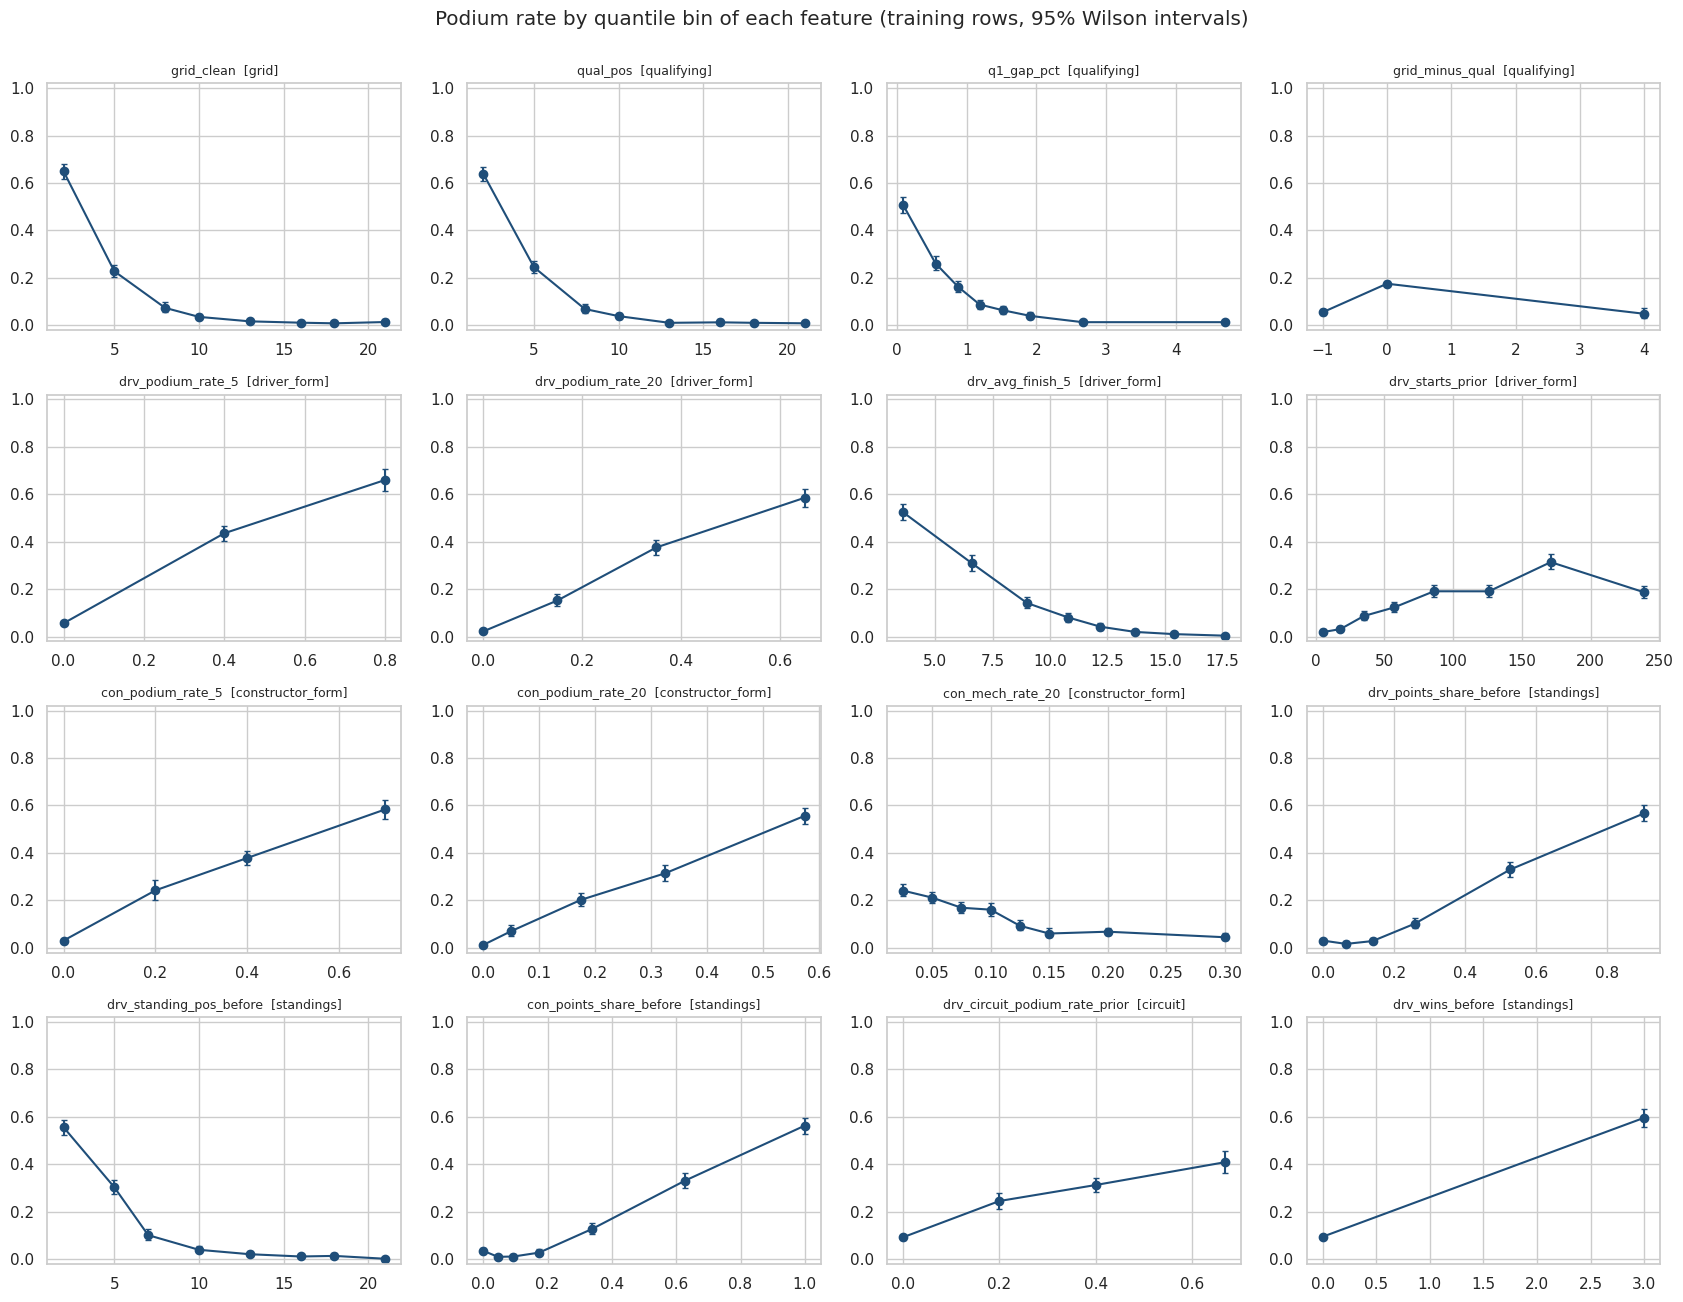

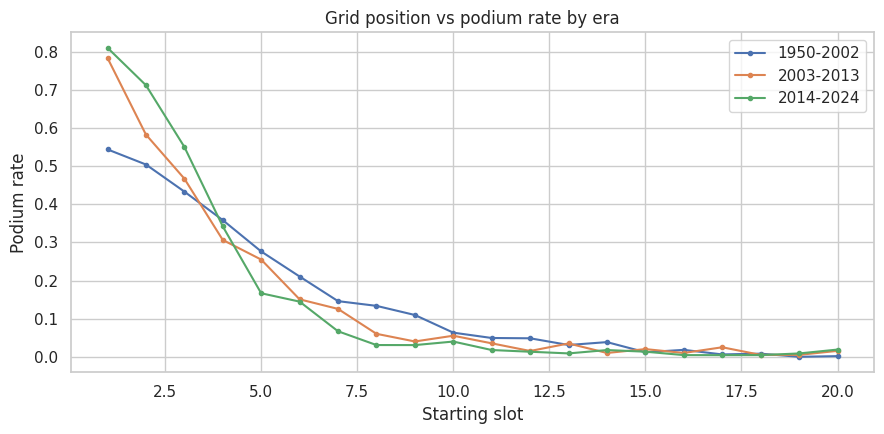

In [35]:
trn = feat[feat["split"] == "train"].copy()
print(f"training rows: {len(trn):,} | podium rate {trn['podium'].mean():.3f}")

show = ["grid_clean", "qual_pos", "q1_gap_pct", "grid_minus_qual",
        "drv_podium_rate_5", "drv_podium_rate_20", "drv_avg_finish_5", "drv_starts_prior",
        "con_podium_rate_5", "con_podium_rate_20", "con_mech_rate_20", "drv_points_share_before",
        "drv_standing_pos_before", "con_points_share_before", "drv_circuit_podium_rate_prior", "drv_wins_before"]
fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, c in zip(axes.ravel(), show):
    d = trn[[c, "podium"]].dropna()
    try:
        bins = pd.qcut(d[c], q=8, duplicates="drop")
    except ValueError:
        bins = pd.cut(d[c], bins=8)
    g = d.groupby(bins, observed=True).agg(x=(c, "median"), rate=("podium", "mean"), n=("podium", "size"))
    lo, hi = wilson(g["rate"] * g["n"], g["n"])
    ax.errorbar(g["x"], g["rate"], yerr=[g["rate"] - lo, hi - g["rate"]], marker="o", color="#1f4e79", capsize=2)
    ax.set_title(f"{c}  [{GROUP_OF[c]}]", fontsize=9)
    ax.set_ylim(-0.02, 1.02)
fig.suptitle("Podium rate by quantile bin of each feature (training rows, 95% Wilson intervals)", y=1.0)
save_show(fig, "s3_podium_rate_by_feature")

fig, ax = plt.subplots(figsize=(9, 4.5))
eras = [("1950-2002", base["year"] < 2003), ("2003-2013", base["year"].between(2003, 2013)), ("2014-2024", base["year"] >= 2014)]
for lab, m in eras:
    d = base[m & (base["grid_clean"] <= 20)].groupby("grid_clean")["podium"].mean()
    ax.plot(d.index, d.values, marker="o", ms=3, label=lab)
ax.set_xlabel("Starting slot"); ax.set_ylabel("Podium rate"); ax.set_title("Grid position vs podium rate by era")
ax.legend()
save_show(fig, "s3_grid_vs_podium_by_era")

Single-feature screen on training rows (auc below 0.5 means higher values lower the podium chance):


,feature,group,coverage,auc,spearman
0,qual_pos,qualifying,0.997,0.090,-0.497
1,grid_clean,grid,1.000,0.091,-0.494
2,drv_standing_pos_before,standings,0.929,0.107,-0.478
3,con_podium_rate_20,constructor_form,0.996,0.882,0.485
4,drv_podium_rate_20,driver_form,0.967,0.878,0.499
5,con_avg_finish_5,constructor_form,0.996,0.123,-0.456
6,con_podium_rate_5,constructor_form,0.996,0.874,0.513
7,con_standing_pos_before,standings,0.943,0.133,-0.447
8,drv_avg_finish_5,driver_form,0.967,0.136,-0.445
9,con_points_share_before,standings,1.000,0.858,0.435


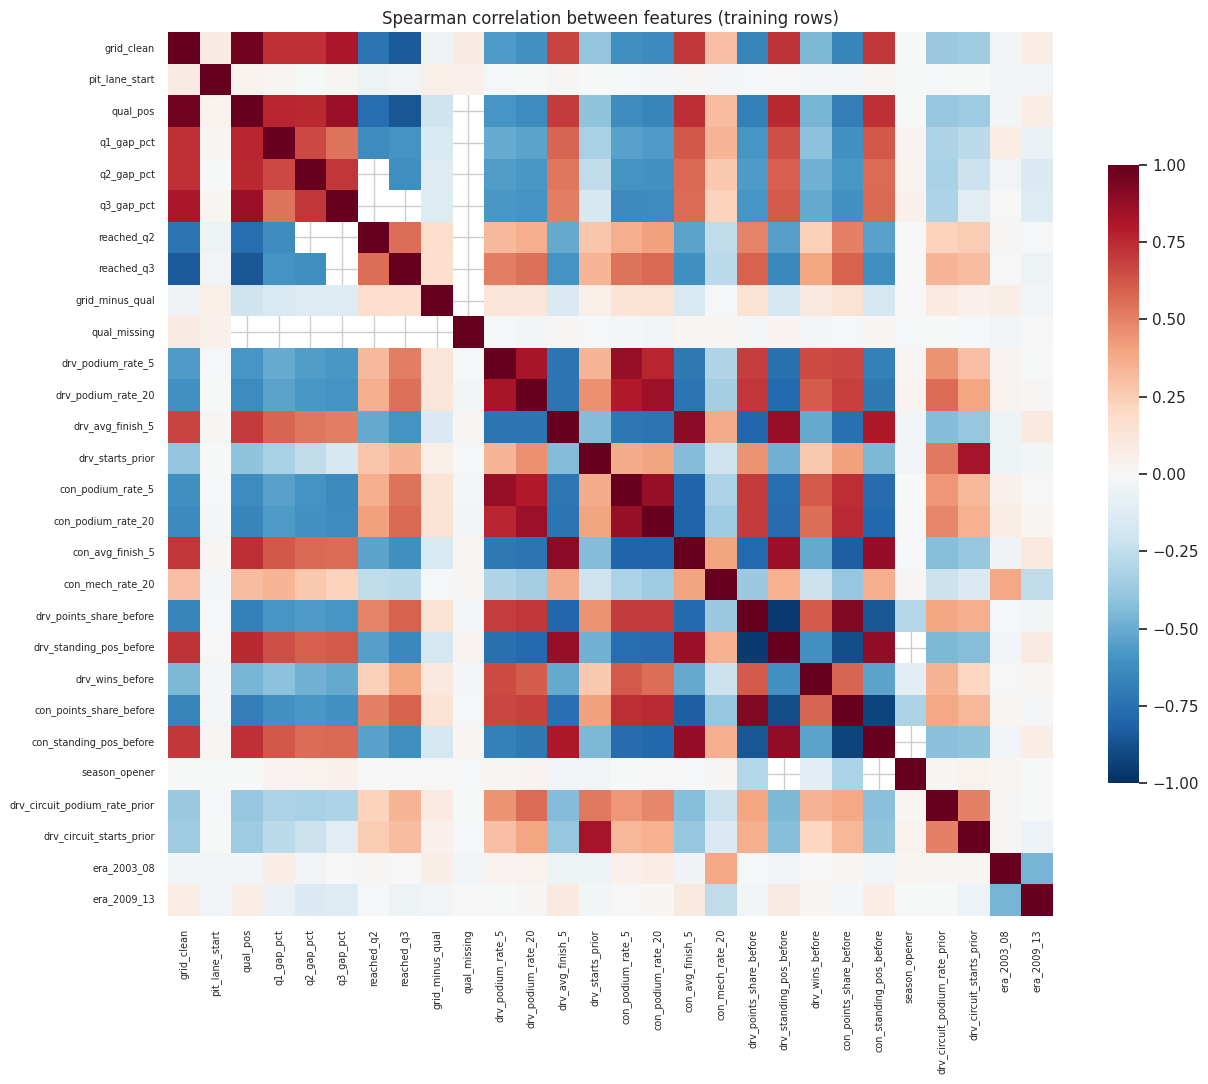


Feature pairs with |Spearman| >= 0.85:
  grid_clean                       qual_pos                         +0.97
  drv_points_share_before          drv_standing_pos_before          -0.95
  drv_points_share_before          con_points_share_before          +0.93
  con_points_share_before          con_standing_pos_before          -0.92
  drv_avg_finish_5                 con_avg_finish_5                 +0.90
  drv_standing_pos_before          con_points_share_before          -0.89
  drv_standing_pos_before          con_standing_pos_before          +0.88
  con_avg_finish_5                 con_standing_pos_before          +0.88
  drv_podium_rate_5                con_podium_rate_5                +0.87
  drv_avg_finish_5                 drv_standing_pos_before          +0.87
  con_podium_rate_5                con_podium_rate_20               +0.87
  qual_pos                         q3_gap_pct                       +0.86
  con_avg_finish_5                 drv_standing_pos_before          +0.8

In [36]:
rows_ = []
for c in FEATS:
    d = trn[[c, "podium"]].dropna()
    n = len(d)
    if n < 50 or d[c].nunique() < 2:
        rows_.append({"feature": c, "group": GROUP_OF[c], "coverage": n / len(trn), "auc": np.nan, "spearman": np.nan})
        continue
    rows_.append({"feature": c, "group": GROUP_OF[c], "coverage": n / len(trn),
                  "auc": roc_auc_score(d["podium"], d[c]),
                  "spearman": stats.spearmanr(d[c], d["podium"]).statistic})
uni = pd.DataFrame(rows_).assign(strength=lambda x: (x["auc"] - 0.5).abs()).sort_values("strength", ascending=False)
print("Single-feature screen on training rows (auc below 0.5 means higher values lower the podium chance):")
display(uni.drop(columns="strength").round(3).reset_index(drop=True))

cm = trn[FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7)
ax.set_title("Spearman correlation between features (training rows)")
save_show(fig, "s3_feature_correlation")

pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(FEATS) for b in FEATS[i + 1:]
         if pd.notna(cm.loc[a, b]) and abs(cm.loc[a, b]) >= 0.85]
print("\nFeature pairs with |Spearman| >= 0.85:")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:32s} {b:32s} {r:+.2f}")
if not pairs:
    print("  none")
print("\nThese pairs are kept in the table. The logistic regression is regularised, trees do not mind, and Section 5 "
      "tests each group by removing it. A pair is only a problem for coefficient interpretation, which the XAI section "
      "handles with permutation importance and SHAP rather than raw coefficients.")

### Why the features with no single-feature signal are kept

Six features score close to 0.5 in the screen above: `pit_lane_start`, `qual_missing`, `season_opener`, `grid_minus_qual` and the two era flags. A feature that does nothing alone can still be useful, because it tells the model how to read another feature. Each one is kept for a specific, testable reason:

| Feature | Hypothesis: why it should help |
|---|---|
| `pit_lane_start` | Rare (well under 1% of rows), so its single-feature AUC is near 0.5 by construction. But a pit-lane starter is placed at the last slot + 1, and the flag tells the model that this slot is a penalty, not slow pace. Section 1.5.2 found no podium from 73 pit-lane starts in 2003-2024. |
| `grid_minus_qual` | Measures a grid penalty: a fast qualifier sent down the grid still has a fast car. Among strong qualifiers, a penalised driver should podium more often than drivers who qualified at that grid slot. |
| `season_opener` | At the first race of a season the standings features are empty or zero for everyone. The flag tells the model that a zero points share means "season has not started", not "no points". |
| `qual_missing` | Marks rows where the qualifying features are absent, so the model can rely more on grid and form for them. |
| `era_2003_08`, `era_2009_13` | The podium rate from the front positions differs by regulation era (plot above). The flags let the training fit separate these eras. They are always 0 in validation and test (both 2014 or later), which Section 5.4 discusses. |

The cell below checks each hypothesis on the training rows. Section 5 then measures what each group adds after training.

In [37]:
fl = trn.copy()
print("1) pit_lane_start: podium rate by flag (training rows)")
display(fl.groupby("pit_lane_start")["podium"].agg(rate="mean", rows="size").round(3))

top_q = fl[(fl["qual_pos"] <= 5) & fl["grid_minus_qual"].notna()].copy()
top_q["grid_vs_qualifying"] = np.where(top_q["grid_minus_qual"] > 0, "dropped back (penalty)", "started where qualified or ahead")
print("2) grid_minus_qual: drivers who qualified in the top 5")
display(top_q.groupby("grid_vs_qualifying")["podium"].agg(rate="mean", rows="size").round(3))
pen = fl[fl["grid_minus_qual"] > 0].copy()
pen_pairs = []
for g_, d_ in pen.groupby("grid_clean"):
    same = fl[(fl["grid_clean"] == g_) & (fl["grid_minus_qual"] == 0)]
    if len(d_) >= 5 and len(same) >= 30:
        pen_pairs.append({"grid_slot": g_, "penalised_rate": d_["podium"].mean(), "penalised_rows": len(d_),
                          "qualified_there_rate": same["podium"].mean()})
pen_tbl = pd.DataFrame(pen_pairs)
if len(pen_tbl):
    print("   same grid slot, penalised drivers vs drivers who qualified at that slot:")
    display(pen_tbl.round(3))

print("3) season_opener: what the standings features look like at the first race of a season")
so = fl.groupby("season_opener").agg(rows=("podium", "size"),
                                     standing_pos_missing=("drv_standing_pos_before", lambda s: s.isna().mean()),
                                     points_share_is_zero=("drv_points_share_before", lambda s: (s == 0).mean()),
                                     podium_rate=("podium", "mean"))
display(so.round(3))

print("4) qual_missing: rows without a qualifying record, and how often grid then decides the podium")
display(fl.groupby("qual_missing")["podium"].agg(rate="mean", rows="size").round(3))

print("5) era flags: podium rate for grid slots 1-3 by regulation era (training rows)")
fl["era"] = np.select([fl["era_2003_08"] == 1, fl["era_2009_13"] == 1], ["2003-2008", "2009-2013"], "2014-2019")
display(fl[fl["grid_clean"] <= 3].groupby(["era", "grid_clean"])["podium"].mean().unstack().round(3))

print("\nTakeaways (computed):")
pl_ = fl.groupby("pit_lane_start")["podium"].mean()
print(f"  pit-lane starters podium rate {pl_.get(1, float('nan')):.1%} vs {pl_.get(0, float('nan')):.1%} for everyone else")
tq = top_q.groupby("grid_vs_qualifying")["podium"].mean()
print("  top-5 qualifiers: " + "; ".join(f"{k} {v:.1%}" for k, v in tq.items()))
if len(pen_tbl):
    print(f"  at the same grid slot, penalised drivers podium {pen_tbl['penalised_rate'].mean():.1%} on average vs "
          f"{pen_tbl['qualified_there_rate'].mean():.1%} for drivers who qualified there")
print(f"  at season openers, drv_standing_pos_before is missing for {so.loc[1, 'standing_pos_missing']:.0%} of rows "
      f"and the points share is 0 for {so.loc[1, 'points_share_is_zero']:.0%} (vs {so.loc[0, 'points_share_is_zero']:.0%} otherwise)")

1) pit_lane_start: podium rate by flag (training rows)


,rate,rows
pit_lane_start,,
0,0.142,6763
1,0.000,20


2) grid_minus_qual: drivers who qualified in the top 5


,rate,rows
grid_vs_qualifying,,
dropped back (penalty),0.203,64
started where qualified or ahead,0.510,1536


   same grid slot, penalised drivers vs drivers who qualified at that slot:


...

4) qual_missing: rows without a qualifying record, and how often grid then decides the podium


,rate,rows
qual_missing,,
0,0.142,6763
1,0.000,20


5) era flags: podium rate for grid slots 1-3 by regulation era (training rows)


grid_clean,1,2,3
era,,,
2003-2008,0.790,0.581,0.495
2009-2013,0.777,0.585,0.436
2014-2019,0.835,0.700,0.600



Takeaways (computed):
  pit-lane starters podium rate 0.0% vs 14.2% for everyone else
  top-5 qualifiers: dropped back (penalty) 20.3%; started where qualified or ahead 51.0%
  at the same grid slot, penalised drivers podium 7.3% on average vs 2.8% for drivers who qualified there
  at season openers, drv_standing_pos_before is missing for 100% of rows and the points share is 0 for 100% (vs 25% otherwise)


## 3.5 Leakage and validity table

One line per candidate, including the ones we rejected. "Known pre-race" asks whether the value exists at the cutoff (after qualifying, before the start). Evidence is computed in this notebook where possible.

In [38]:
r2 = reg.iloc[1]
LEAK_TABLE = [
    ("grid_clean, pit_lane_start", "Yes", "KEEP",
     "Set after qualifying and penalties. Pit-lane starters (grid 0 in the raw data) get the last slot + 1."),
    ("qual_pos, q1/q2/q3_gap_pct, reached_q2/q3", "Yes", "KEEP",
     "Qualifying finishes before the race. Gaps are relative to the session best so tracks are comparable. "
     "Missing session is NaN, never 0."),
    ("grid_minus_qual", "Yes", "KEEP", "Both inputs known pre-race. Captures grid penalties."),
    ("drv_/con_ rolling form", "Yes", "KEEP",
     "shift(1) before rolling; the future-invariance test above scrambles the target race and the features do not move."),
    ("standings before the race", "Yes", "KEEP",
     "merge_asof, earlier round of the same season, exact match disallowed and asserted. Points as share of the leader."),
    ("drv_circuit_* history", "Yes", "KEEP", "Expanding mean over earlier races at the circuit only, shifted by one."),
    ("era flags", "Yes", "KEEP", "A calendar fact. Used instead of raw year."),
    ("raw year / season", "Yes", "REJECT",
     "Lets a model extrapolate a time trend into test years it never saw. Era flags carry the regulation changes instead."),
    ("raw championship points", "Yes", "REJECT",
     "Points scale changed in 2010 (25 for a win instead of 10), so raw values are not comparable. Share of leader used."),
    ("home-race flag", "Yes", "REJECT",
     f"Section 2 Q2: odds ratio {r2.odds_ratio:.2f} (95% CI {r2.or_lo:.2f} to {r2.or_hi:.2f}) from 2003 after controlling for grid. "
     "No detectable effect, so it adds noise and a nationality mapping that needed manual repair."),
    ("circuit front-row conversion rate", "Yes", "REJECT",
     f"Section 2 Q1: circuits are not distinguishable (chi-square p={q1_chi[('grid', '2003-2013')]:.2f} and "
     f"{q1_chi[('grid', '2014-2024')]:.2f}). Estimating it per circuit from few races would also leak if not strictly past-only."),
    ("driverId, constructorId, circuitId as categoricals", "Yes", "REJECT",
     "Identities are memorised instead of learned, hundreds of sparse columns, new drivers appear every year. "
     "Experiment D compares constructor identity with the lineage-based form features."),
    ("sprint results of the same weekend", "Partly", "REJECT",
     "Judgement call: sprint results exist only from 2021, so the feature would be empty for almost all training rows. "
     "The sprint-adjusted grid is already reflected in the Sunday grid."),
    ("raw qualifying seconds", "Yes", "REJECT", "Track and weather dependent, not comparable across races. Percent gap used."),
    ("positionOrder, points, laps, time, milliseconds, rank, fastestLap*, statusId of THIS race", "No", "REJECT",
     "Post-race outcomes. positionOrder defines the target. statusId is used only to measure past reliability."),
    ("lap_times, pit_stops of this race", "No", "REJECT", "Only exist because the race was run."),
    ("standings AFTER this race", "No", "REJECT", "Contains the race result. Experiment E shows how much it inflates validation AUC."),
    ("rolling form without shift(1)", "No", "REJECT", "Window would include the current race. Experiment E shows the inflation."),
]
w1, w2, w3 = 44, 10, 8
print(f"{'Candidate':{w1}s} {'Pre-race':{w2}s} {'Verdict':{w3}s} Evidence / reason")
print("-" * 160)
for cand, known, verdict_, why in LEAK_TABLE:
    wrapped = textwrap.wrap(why, 90)
    cl = textwrap.wrap(cand, w1)
    for i in range(max(len(wrapped), len(cl))):
        print(f"{cl[i] if i < len(cl) else '':{w1}s} {known if i == 0 else '':{w2}s} {verdict_ if i == 0 else '':{w3}s} "
              f"{wrapped[i] if i < len(wrapped) else ''}")
    print()

Candidate                                    Pre-race   Verdict  Evidence / reason
----------------------------------------------------------------------------------------------------------------------------------------------------------------
grid_clean, pit_lane_start                   Yes        KEEP     Set after qualifying and penalties. Pit-lane starters (grid 0 in the raw data) get the
                                                                 last slot + 1.

qual_pos, q1/q2/q3_gap_pct, reached_q2/q3    Yes        KEEP     Qualifying finishes before the race. Gaps are relative to the session best so tracks are
                                                                 comparable. Missing session is NaN, never 0.

grid_minus_qual                              Yes        KEEP     Both inputs known pre-race. Captures grid penalties.

drv_/con_ rolling form                       Yes        KEEP     shift(1) before rolling; the future-invariance test above scrambles the ta

## 3.6 Preprocessing experiments

All experiments use the same logistic regression and the same validation seasons (2020-2021). The test set is not touched. Metric: ROC-AUC (with average precision as a second view). Because the validation set is small (about 40 races), every comparison reports the change in AUC against a reference with a 95% interval from a bootstrap that resamples whole races. An interval that includes 0 means the difference could be noise.

| Experiment | Question |
|---|---|
| A | Does fitting the imputer and scaler on all data instead of training rows only change anything? |
| B | Does the order, impute then scale vs scale then impute, matter? |
| C | Which training window is better: from 1950, 1980, 1996 or 2003? |
| D | Constructor identity as a one-hot column vs the lineage-based form features |
| D2 | Team form built on the lineage key vs on the raw `constructorId` |
| E | Leaky counter-examples: how much do mistakes inflate the score? |
| F | Design choices that were otherwise only reasoned: missing-value flags on, no scaling, rolling windows 3/10 and 10/40, raw points, raw qualifying seconds |

Before the experiments, section 3.6.0 shows what imputation and scaling do to the values themselves.

In [39]:
val = feat[feat["split"] == "val"].reset_index(drop=True)
tr_main = feat[feat["split"] == "train"].reset_index(drop=True)
rng_boot = np.random.default_rng(SEED)
val_races = val["raceId"].to_numpy()
race_ids_val = pd.unique(val_races)
race_rows = {r: np.where(val_races == r)[0] for r in race_ids_val}
BOOT = [np.concatenate([race_rows[r] for r in rng_boot.choice(race_ids_val, len(race_ids_val), replace=True)])
        for _ in range(300)]

def make_prep(order="impute_scale", strategy="median"):
    if strategy == "median":
        imp = SimpleImputer(strategy="median", keep_empty_features=True)
    else:
        imp = SimpleImputer(strategy="constant", fill_value=0.0, keep_empty_features=True)
    return imp, StandardScaler()

def run_lr(Xtr, ytr, Xev, order="impute_scale", strategy="median", Xfit=None, extra_tr=None, extra_ev=None):
    Xfit = Xtr if Xfit is None else Xfit
    imp, sc = make_prep(order, strategy)
    if order == "impute_scale":
        imp.fit(Xfit); sc.fit(imp.transform(Xfit))
        A, Bm = sc.transform(imp.transform(Xtr)), sc.transform(imp.transform(Xev))
    else:
        sc.fit(Xfit); imp.fit(sc.transform(Xfit))
        A, Bm = imp.transform(sc.transform(Xtr)), imp.transform(sc.transform(Xev))
    if extra_tr is not None:
        A, Bm = np.hstack([A, extra_tr]), np.hstack([Bm, extra_ev])
    m = LogisticRegression(max_iter=3000)
    m.fit(A, ytr)
    return m.predict_proba(Bm)[:, 1]

def auc_ap(y, p):
    return roc_auc_score(y, p), average_precision_score(y, p)

def diff_ci(y, p_ref, p_new):
    d = np.array([roc_auc_score(y[i], p_new[i]) - roc_auc_score(y[i], p_ref[i]) for i in BOOT])
    return np.percentile(d, [2.5, 97.5])

yv = val["podium"].to_numpy()
RESULTS = []
def record(exp, variant, y, p, p_ref, n_train, note=""):
    auc, ap = auc_ap(y, p)
    if p_ref is p:
        d, lo, hi = 0.0, np.nan, np.nan
    else:
        d = auc - auc_ap(y, p_ref)[0]
        lo, hi = diff_ci(y, p_ref, p)
    RESULTS.append({"exp": exp, "variant": variant, "n_train": n_train, "val_auc": auc, "val_ap": ap,
                    "d_auc_vs_ref": d, "ci_lo": lo, "ci_hi": hi, "note": note})

Xtr, ytr, Xv = tr_main[FEATS], tr_main["podium"].to_numpy(), val[FEATS]
p_ref = run_lr(Xtr, ytr, Xv)
record("Ref", "all features, impute->scale, fitted on train", yv, p_ref, p_ref, len(tr_main))
bs = np.std([roc_auc_score(yv[i], p_ref[i]) for i in BOOT])
print(f"Reference model: val ROC-AUC {auc_ap(yv, p_ref)[0]:.4f}, AP {auc_ap(yv, p_ref)[1]:.4f}; "
      f"bootstrap SE of the AUC {bs:.4f}. Differences below about {1.96 * bs:.3f} are within noise.")

Reference model: val ROC-AUC 0.9333, AP 0.7401; bootstrap SE of the AUC 0.0174. Differences below about 0.034 are within noise.


### 3.6.0 Effect of preprocessing on the values

Imputation and scaling change the data that the models see. The table and histograms below are computed on the training rows (2003-2019) with the same median imputer and standard scaler that the experiments use, fitted on those rows only.

- **Median imputation** replaces each gap with the training median. Where a feature is often missing (the Q2 and Q3 gaps, because drivers knocked out earlier have no later lap), this creates a large spike at the median and shrinks the standard deviation.
- **Standard scaling** gives every column mean 0 and standard deviation 1, so features measured in very different units (a rate between 0 and 1, a count of starts up to 400) are on the same scale. This matters for the logistic regression and the network, not for the forest.
- Scaling does not remove long tails: a rare extreme value stays many standard deviations from the mean.

Effect of median imputation and standard scaling, training rows 2003-2019:


,missing_%,raw_mean,raw_sd,raw_min,raw_max,median_fill,imputed_mean,imputed_sd,scaled_min,scaled_max
grid_clean,0.000,11.179,6.233,1.0,24.000,11.000,11.179,6.233,-1.633,2.057
qual_pos,0.295,11.147,6.216,1.0,24.000,11.000,11.147,6.207,-1.635,2.071
q1_gap_pct,1.799,1.781,1.823,0.0,33.285,1.342,1.773,1.807,-0.981,17.438
q2_gap_pct,37.402,1.306,1.160,0.0,16.130,1.124,1.238,0.922,-1.343,16.158
q3_gap_pct,61.949,1.176,1.196,0.0,33.010,1.005,1.070,0.742,-1.442,43.044
drv_podium_rate_20,3.273,0.145,0.225,0.0,1.000,0.000,0.140,0.223,-0.631,3.863
drv_starts_prior,0.000,92.937,79.210,0.0,321.000,70.000,92.937,79.210,-1.173,2.879
drv_standing_pos_before,7.121,11.271,6.457,1.0,27.000,11.000,11.252,6.224,-1.647,2.531
con_mech_rate_20,0.428,0.118,0.093,0.0,0.750,0.100,0.118,0.092,-1.279,6.835


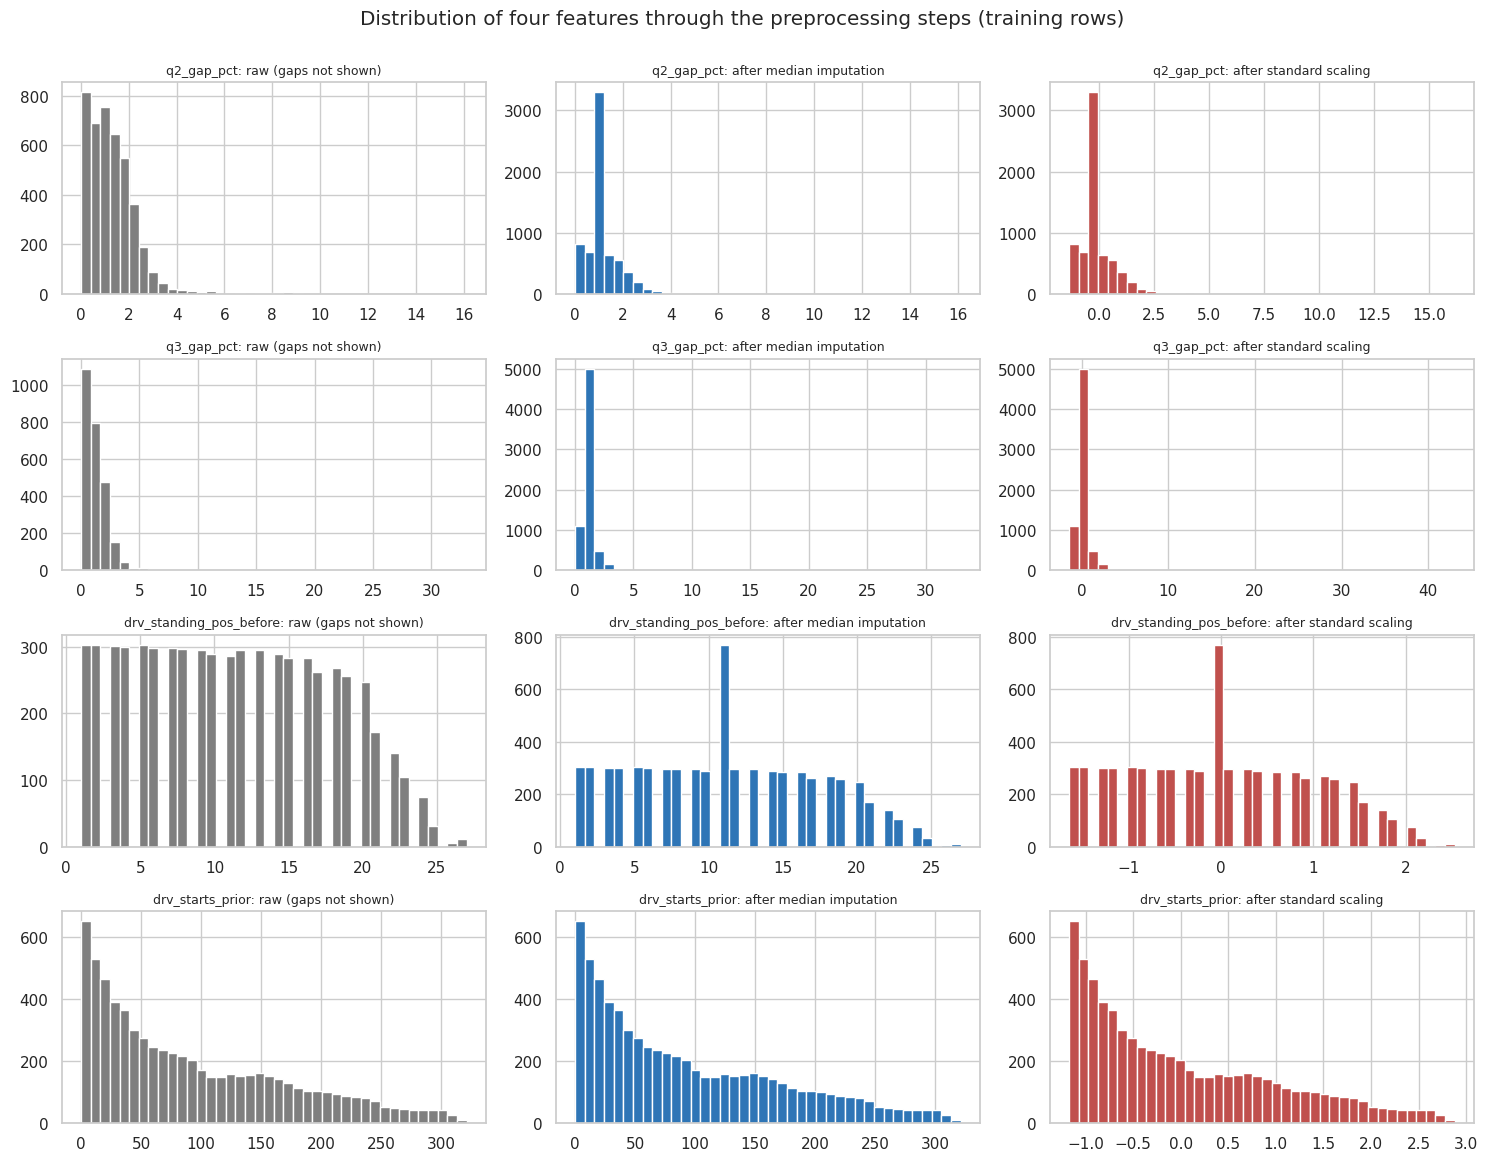

q2_gap_pct: 37.4% of training rows sit exactly at the median after imputation (sd 1.16 raw -> 0.92 imputed); scaled range -1.3 to 16.2
q3_gap_pct: 62.0% of training rows sit exactly at the median after imputation (sd 1.20 raw -> 0.74 imputed); scaled range -1.4 to 43.0
drv_standing_pos_before: 11.4% of training rows sit exactly at the median after imputation (sd 6.46 raw -> 6.22 imputed); scaled range -1.6 to 2.5
drv_starts_prior: 0.4% of training rows sit exactly at the median after imputation (sd 79.21 raw -> 79.21 imputed); scaled range -1.2 to 2.9


In [40]:
SHOW_F = ["grid_clean", "qual_pos", "q1_gap_pct", "q2_gap_pct", "q3_gap_pct", "drv_podium_rate_20",
          "drv_starts_prior", "drv_standing_pos_before", "con_mech_rate_20"]
raw_tr = tr_main[FEATS].astype(float)
imp_demo = SimpleImputer(strategy="median", keep_empty_features=True).fit(raw_tr)
imp_tr = pd.DataFrame(imp_demo.transform(raw_tr), columns=FEATS)
sc_demo = StandardScaler().fit(imp_tr)
sc_tr = pd.DataFrame(sc_demo.transform(imp_tr), columns=FEATS)
fill = pd.Series(imp_demo.statistics_, index=FEATS)

tbl5 = pd.DataFrame({
    "missing_%": 100 * raw_tr[SHOW_F].isna().mean(),
    "raw_mean": raw_tr[SHOW_F].mean(), "raw_sd": raw_tr[SHOW_F].std(),
    "raw_min": raw_tr[SHOW_F].min(), "raw_max": raw_tr[SHOW_F].max(),
    "median_fill": fill[SHOW_F],
    "imputed_mean": imp_tr[SHOW_F].mean(), "imputed_sd": imp_tr[SHOW_F].std(),
    "scaled_min": sc_tr[SHOW_F].min(), "scaled_max": sc_tr[SHOW_F].max(),
})
print("Effect of median imputation and standard scaling, training rows 2003-2019:")
display(tbl5.round(3))

HIST_F = ["q2_gap_pct", "q3_gap_pct", "drv_standing_pos_before", "drv_starts_prior"]
fig, axes = plt.subplots(len(HIST_F), 3, figsize=(15, 2.9 * len(HIST_F)))
stage_col = ["#7f7f7f", "#2e75b6", "#c0504d"]
for r, f in enumerate(HIST_F):
    stages = [("raw (gaps not shown)", raw_tr[f].dropna()), ("after median imputation", imp_tr[f]),
              ("after standard scaling", sc_tr[f])]
    for c, (lab, s) in enumerate(stages):
        axes[r, c].hist(s, bins=40, color=stage_col[c])
        axes[r, c].set_title(f"{f}: {lab}", fontsize=9)
fig.suptitle("Distribution of four features through the preprocessing steps (training rows)", y=1.0)
save_show(fig, "s3_preprocessing_distributions")

for f in HIST_F:
    share = float((imp_tr[f] == fill[f]).mean())
    print(f"{f}: {share:.1%} of training rows sit exactly at the median after imputation "
          f"(sd {raw_tr[f].std():.2f} raw -> {imp_tr[f].std():.2f} imputed); scaled range {sc_tr[f].min():.1f} to {sc_tr[f].max():.1f}")

### Experiment A: where are the imputer and scaler fitted?

Correct: fit on training rows only, then apply to validation. Leaky: fit on training, validation and test rows together, so statistics of future seasons leak into the preprocessing.

In [41]:
Xall = feat[feat["split"].isin(["train", "val", "test"])][FEATS]
p_a = run_lr(Xtr, ytr, Xv, Xfit=Xall)
record("A", "preprocessing fitted on train+val+test (leaky)", yv, p_a, p_ref, len(tr_main), "leaky variant")
print("Experiment A done.")

Experiment A done.


### Experiment B: order of imputation and scaling

With median imputation the two orders are mathematically the same (the median of a rescaled column is the rescaled median), so no difference is expected. With a constant fill of 0 the order matters: filling zeros before scaling drags the mean and variance, while scaling first and then filling 0 equals mean imputation.

In [42]:
p_b1 = run_lr(Xtr, ytr, Xv, order="scale_impute", strategy="median")
record("B", "median: scale -> impute", yv, p_b1, p_ref, len(tr_main))
p_b2 = run_lr(Xtr, ytr, Xv, order="impute_scale", strategy="constant")
record("B", "zero fill: impute -> scale", yv, p_b2, p_ref, len(tr_main))
p_b3 = run_lr(Xtr, ytr, Xv, order="scale_impute", strategy="constant")
record("B", "zero fill: scale -> impute (= mean imputation)", yv, p_b3, p_ref, len(tr_main))
print("Experiment B done.")

Experiment B done.


### Experiment C: training window

Same model, different first training season (all end in 2019). Qualifying features are left out here because they are complete only from 2003, so the comparison uses only features that exist for every window. `era_pre2003` is added for the long windows.

In [43]:
C_FEATS = [c for c in FEATS if GROUP_OF[c] != "qualifying"] + ["era_pre2003"]
Xv_c, c_ref = val[C_FEATS], None
for start in (2003, 1996, 1980, 1950):
    tw = feat[(feat["year"] >= start) & (feat["year"] <= 2019)].reset_index(drop=True)
    p = run_lr(tw[C_FEATS], tw["podium"].to_numpy(), Xv_c)
    if c_ref is None:
        c_ref = p
    record("C", f"train from {start} (no qualifying features)", yv, p, c_ref, len(tw),
           "reference for C" if start == 2003 else "")
print("Experiment C done.")

Experiment C done.


### Experiment D: constructor identity

Three versions on the 2003-2019 training window: no team identity (form features only), a one-hot of the raw `constructorId`, and a one-hot of the lineage `team_key`.

In [44]:
def onehot_cols(col):
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    A = enc.fit_transform(tr_main[[col]].astype(str))
    Bm = enc.transform(val[[col]].astype(str))
    return A, Bm, A.shape[1]

for col, label in [("constructorId", "one-hot constructorId"), ("team_key", "one-hot lineage team_key")]:
    A, Bm, k = onehot_cols(col)
    p = run_lr(Xtr, ytr, Xv, extra_tr=A, extra_ev=Bm)
    unseen = (~val[col].astype(str).isin(set(tr_main[col].astype(str)))).mean()
    record("D", f"form features + {label}", yv, p, p_ref, len(tr_main), f"{k} extra columns, {unseen:.1%} val rows unseen team")
print("Experiment D done.")

Experiment D done.


### Experiment D2: lineage key vs raw constructorId for the team form features

Experiment D added team identity columns. This experiment asks the question behind the lineage key directly: the four team form features are rebuilt with `team_key` set to the raw `constructorId` (so a renamed team starts from zero history), and the same logistic regression is retrained. Everything else is identical.

In [45]:
def lr_swap(df, swap, label, exp, note=""):
    """Retrain the reference LR with some feature columns replaced; df must hold one row per resultId."""
    cols = [swap.get(c, c) for c in FEATS]
    d = df.set_index("resultId")
    a, b = d.loc[tr_main["resultId"]], d.loc[val["resultId"]]
    p = run_lr(a[cols], a["podium"].to_numpy(), b[cols])
    record(exp, label, yv, p, p_ref, len(a), note)
    return p

b_raw = base.copy()
b_raw["team_key"] = "c" + b_raw["constructorId"].astype(str)
feat_raw = make_features(b_raw, qual, dstand, cstand, status_cat)
changed = feat_raw.set_index("resultId").loc[tr_main["resultId"], "con_podium_rate_20"].to_numpy(float)
orig = tr_main["con_podium_rate_20"].to_numpy(float)
print(f"training rows whose con_podium_rate_20 changes without the lineage key: "
      f"{np.mean(~np.isclose(changed, orig, equal_nan=True)):.1%}")
lr_swap(feat_raw, {}, "team form keyed by raw constructorId (no lineage)", "D2")
print("Experiment D2 done.")

training rows whose con_podium_rate_20 changes without the lineage key: 4.4%
Experiment D2 done.


### Experiment E: leaky counter-examples

These are mistakes, run on purpose to show their size. They are not used anywhere else.
- Unshifted form: rolling podium rate that includes the current race.
- Post-race standings: points share after this race instead of before.

In [46]:
def post_race_share(df, stand):
    s = stand[["raceId", "driverId", "points"]].copy()
    s["lead"] = s.groupby("raceId")["points"].transform("max")
    s["leak_points_share_after"] = np.where(s["lead"] > 0, s["points"] / s["lead"].where(s["lead"] > 0, 1), 0.0)
    return df.merge(s[["raceId", "driverId", "leak_points_share_after"]], on=["raceId", "driverId"], how="left")["leak_points_share_after"].to_numpy()

fs = feat.sort_values(["race_idx", "resultId"])
fs["leak_form_unshifted"] = fs.groupby("driverId")["podium"].transform(lambda s: s.rolling(5, min_periods=1).mean())
fs["leak_points_share_after"] = post_race_share(fs, dstand)
lk = fs.set_index("resultId")
tr_l = lk.loc[tr_main["resultId"]].reset_index()
va_l = lk.loc[val["resultId"]].reset_index()
for cols, label in [(["leak_form_unshifted"], "+ unshifted rolling podium rate"),
                    (["leak_points_share_after"], "+ post-race standings share"),
                    (["leak_form_unshifted", "leak_points_share_after"], "+ both")]:
    p = run_lr(tr_l[FEATS + cols], ytr, va_l[FEATS + cols])
    record("E", label + " (LEAKY)", yv, p, p_ref, len(tr_l), "do not use")
print("Experiment E done.")

Experiment E done.


### Experiment F: design choices that were otherwise only reasoned

Several choices were made on reasoning alone. Each is tested here with one retraining of the reference logistic regression, validation only:

| Variant | Choice it tests |
|---|---|
| Missing-value flags added | Section 4 adds a flag for every feature with gaps. Is that better than median filling alone? |
| No scaling | Standard scaling of the inputs |
| Rolling windows 3 and 10, or 10 and 40 | The 5- and 20-race windows of the form features |
| Raw championship points | Points as a share of the leader |
| Raw qualifying seconds | Qualifying gaps in percent of the session best |

The rolling-window variants rebuild the form features with exactly the same shift-then-roll logic as `make_features`; the cell first checks that the rebuild reproduces the 5- and 20-race columns.

In [47]:
from sklearn.pipeline import Pipeline

def run_lr_pipe(Xtr_, ytr_, Xev_, indicator=False, scale=True):
    steps = [("imp", SimpleImputer(strategy="median", add_indicator=indicator, keep_empty_features=True))]
    if scale:
        steps.append(("sc", StandardScaler()))
    pre_ = Pipeline(steps).fit(Xtr_)
    m = LogisticRegression(max_iter=5000).fit(pre_.transform(Xtr_), ytr_)
    return m.predict_proba(pre_.transform(Xev_))[:, 1]

# F: missing-value flags and scaling
record("F", "missing-value flags added (as in Section 4)", yv, run_lr_pipe(Xtr, ytr, Xv, indicator=True), p_ref, len(tr_main))
record("F", "no scaling (median imputation only)", yv, run_lr_pipe(Xtr, ytr, Xv, scale=False), p_ref, len(tr_main))

# F: rolling windows, rebuilt with the make_features logic
fw = feat.sort_values(["race_idx", "resultId"]).reset_index(drop=True)
gd_w = fw.groupby("driverId", sort=False)
tm = (fw.groupby(["team_key", "race_idx"], as_index=False).agg(t_podium=("podium", "mean"))
        .sort_values(["team_key", "race_idx"]).reset_index(drop=True))
gt_w = tm.groupby("team_key", sort=False)
for w in (3, 5, 10, 20, 40):
    fw[f"drv_w{w}"] = gd_w["podium"].transform(lambda s: s.shift(1).rolling(w, min_periods=min(3, w)).mean())
    tm[f"con_w{w}"] = gt_w["t_podium"].transform(lambda s: s.shift(1).rolling(w, min_periods=min(3, w)).mean())
fw = fw.merge(tm.drop(columns="t_podium"), on=["team_key", "race_idx"], how="left")
same = all(np.allclose(fw[a].to_numpy(float), fw[b].to_numpy(float), equal_nan=True)
           for a, b in [("drv_w5", "drv_podium_rate_5"), ("drv_w20", "drv_podium_rate_20"),
                        ("con_w5", "con_podium_rate_5"), ("con_w20", "con_podium_rate_20")])
print("Rebuild reproduces the Section 3.2 5- and 20-race form features exactly:", same)
for short, long_ in [(3, 10), (10, 40)]:
    lr_swap(fw, {"drv_podium_rate_5": f"drv_w{short}", "drv_podium_rate_20": f"drv_w{long_}",
                 "con_podium_rate_5": f"con_w{short}", "con_podium_rate_20": f"con_w{long_}"},
            f"rolling windows {short} and {long_} instead of 5 and 20", "F")

# F: raw championship points before the race instead of share of the leader
def points_before(stand, idcol, name):
    s = stand.merge(races_map, on="raceId", how="inner")[["year", "round", idcol, "points"]]
    return s.rename(columns={"points": name}).sort_values("round")
fp_ = pd.merge_asof(feat.sort_values("round"), points_before(dstand, "driverId", "drv_points_before"),
                    on="round", by=["year", "driverId"], allow_exact_matches=False, direction="backward")
fp_ = pd.merge_asof(fp_.sort_values("round"), points_before(cstand, "constructorId", "con_points_before"),
                    on="round", by=["year", "constructorId"], allow_exact_matches=False, direction="backward")
fp_[["drv_points_before", "con_points_before"]] = fp_[["drv_points_before", "con_points_before"]].fillna(0.0)
lr_swap(fp_, {"drv_points_share_before": "drv_points_before", "con_points_share_before": "con_points_before"},
        "raw championship points instead of share of the leader", "F")

# F: raw qualifying seconds instead of the percent gap
qs = qual[["raceId", "driverId", "q1_sec", "q2_sec", "q3_sec"]].drop_duplicates(["raceId", "driverId"])
fq_ = feat.merge(qs, on=["raceId", "driverId"], how="left")
lr_swap(fq_, {"q1_gap_pct": "q1_sec", "q2_gap_pct": "q2_sec", "q3_gap_pct": "q3_sec"},
        "raw qualifying seconds instead of percent gap", "F")
print("Experiment F done.")

Rebuild reproduces the Section 3.2 5- and 20-race form features exactly: True
Experiment F done.


In [48]:
res_tbl = pd.DataFrame(RESULTS)
display(res_tbl.round(4))

def row(exp, key):
    r = res_tbl[(res_tbl["exp"] == exp) & res_tbl["variant"].str.contains(key, regex=False)].iloc[0]
    return r
def inside(r):
    if abs(r.d_auc_vs_ref) < 0.002:
        return "negligible, under 0.002"
    return "within noise" if (r.ci_lo <= 0 <= r.ci_hi) else ("better" if r.d_auc_vs_ref > 0 else "worse")

print("\nTakeaways (computed from the table above):")
r = row("A", "leaky"); print(f"  A. Fitting preprocessing on all data changed val AUC by {r.d_auc_vs_ref:+.4f} ({inside(r)}). "
      "The effect is small because median and standard deviation barely move with extra rows, but the rule stays: fit on training rows only.")
r1, r2_, r3 = row("B", "median: scale"), row("B", "zero fill: impute"), row("B", "zero fill: scale")
print(f"  B. Median imputation, either order: {r1.d_auc_vs_ref:+.4f} (same by algebra). Zero fill then scale: {r2_.d_auc_vs_ref:+.4f} "
      f"({inside(r2_)}); zero fill after scaling: {r3.d_auc_vs_ref:+.4f} ({inside(r3)}).")
cw = res_tbl[res_tbl["exp"] == "C"].set_index("variant")
print("  C. Val AUC by training start: " + "; ".join(f"{k.split()[2]} {v.val_auc:.4f} (n={int(v.n_train):,}, {inside(v) if v.ci_lo == v.ci_lo else 'reference'})" for k, v in cw.iterrows()) + ".")
d1, d2 = row("D", "constructorId"), row("D", "team_key")
print(f"  D. Adding constructorId one-hot: {d1.d_auc_vs_ref:+.4f} ({inside(d1)}); lineage team_key one-hot: {d2.d_auc_vs_ref:+.4f} ({inside(d2)}).")
e_ = res_tbl[res_tbl["exp"] == "E"]
print("  E. Leaky variants: " + "; ".join(f"{v.variant.split(' (')[0]} {v.val_auc:.4f} ({v.d_auc_vs_ref:+.4f})" for v in e_.itertuples()) + ".")

,exp,variant,n_train,val_auc,val_ap,d_auc_vs_ref,ci_lo,ci_hi,note
0,Ref,"all features, impute->scale, fitted on train",6783,0.9333,0.7401,0.0000,NaN,NaN,
1,A,preprocessing fitted on train+val+test (leaky),6783,0.9332,0.7401,-0.0001,-0.0003,0.0001,leaky variant
2,B,median: scale -> impute,6783,0.9332,0.7401,-0.0001,-0.0003,0.0001,
3,B,zero fill: impute -> scale,6783,0.9315,0.7360,-0.0018,-0.0051,0.0011,
4,B,zero fill: scale -> impute (= mean imputation),6783,0.9330,0.7378,-0.0003,-0.0011,0.0007,
5,C,train from 2003 (no qualifying features),6783,0.9262,0.7216,0.0000,NaN,NaN,reference for C
6,C,train from 1996 (no qualifying features),9268,0.9266,0.7225,0.0004,-0.0016,0.0021,
7,C,train from 1980 (no qualifying features),15671,0.9275,0.7317,0.0013,-0.0025,0.0041,
8,C,train from 1950 (no qualifying features),22459,0.9265,0.7276,0.0003,-0.0043,0.0038,
9,D,form features + one-hot constructorId,6783,0.9309,0.7372,-0.0024,-0.0067,0.0011,"31 extra columns, 21.3% val rows unseen team"



Takeaways (computed from the table above):
  A. Fitting preprocessing on all data changed val AUC by -0.0001 (negligible, under 0.002). The effect is small because median and standard deviation barely move with extra rows, but the rule stays: fit on training rows only.
  B. Median imputation, either order: -0.0001 (same by algebra). Zero fill then scale: -0.0018 (negligible, under 0.002); zero fill after scaling: -0.0003 (negligible, under 0.002).
  C. Val AUC by training start: 2003 0.9262 (n=6,783, reference); 1996 0.9266 (n=9,268, negligible, under 0.002); 1980 0.9275 (n=15,671, negligible, under 0.002); 1950 0.9265 (n=22,459, negligible, under 0.002).
  D. Adding constructorId one-hot: -0.0024 (within noise); lineage team_key one-hot: -0.0019 (negligible, under 0.002).
  E. Leaky variants: + unshifted rolling podium rate 0.9972 (+0.0639); + post-race standings share 0.9731 (+0.0398); + both 0.9989 (+0.0655).


Takeaways for D2 and F (change in validation ROC-AUC against the reference, 95% CI from resampled races):
  D2  team form keyed by raw constructorId (no lineage)       AUC 0.9328, AP 0.7395, change -0.0005 (CI -0.0009 to -0.0000, negligible, under 0.002)
  F   missing-value flags added (as in Section 4)             AUC 0.9359, AP 0.7413, change +0.0026 (CI -0.0001 to +0.0063, within noise)
  F   no scaling (median imputation only)                     AUC 0.9330, AP 0.7363, change -0.0003 (CI -0.0011 to +0.0004, negligible, under 0.002)
  F   rolling windows 3 and 10 instead of 5 and 20            AUC 0.9326, AP 0.7280, change -0.0007 (CI -0.0028 to +0.0012, negligible, under 0.002)
  F   rolling windows 10 and 40 instead of 5 and 20           AUC 0.9330, AP 0.7348, change -0.0003 (CI -0.0020 to +0.0011, negligible, under 0.002)
  F   raw championship points instead of share of the leader  AUC 0.9340, AP 0.7436, change +0.0007 (CI -0.0011 to +0.0020, negligible, under 0.002)
  F   raw q

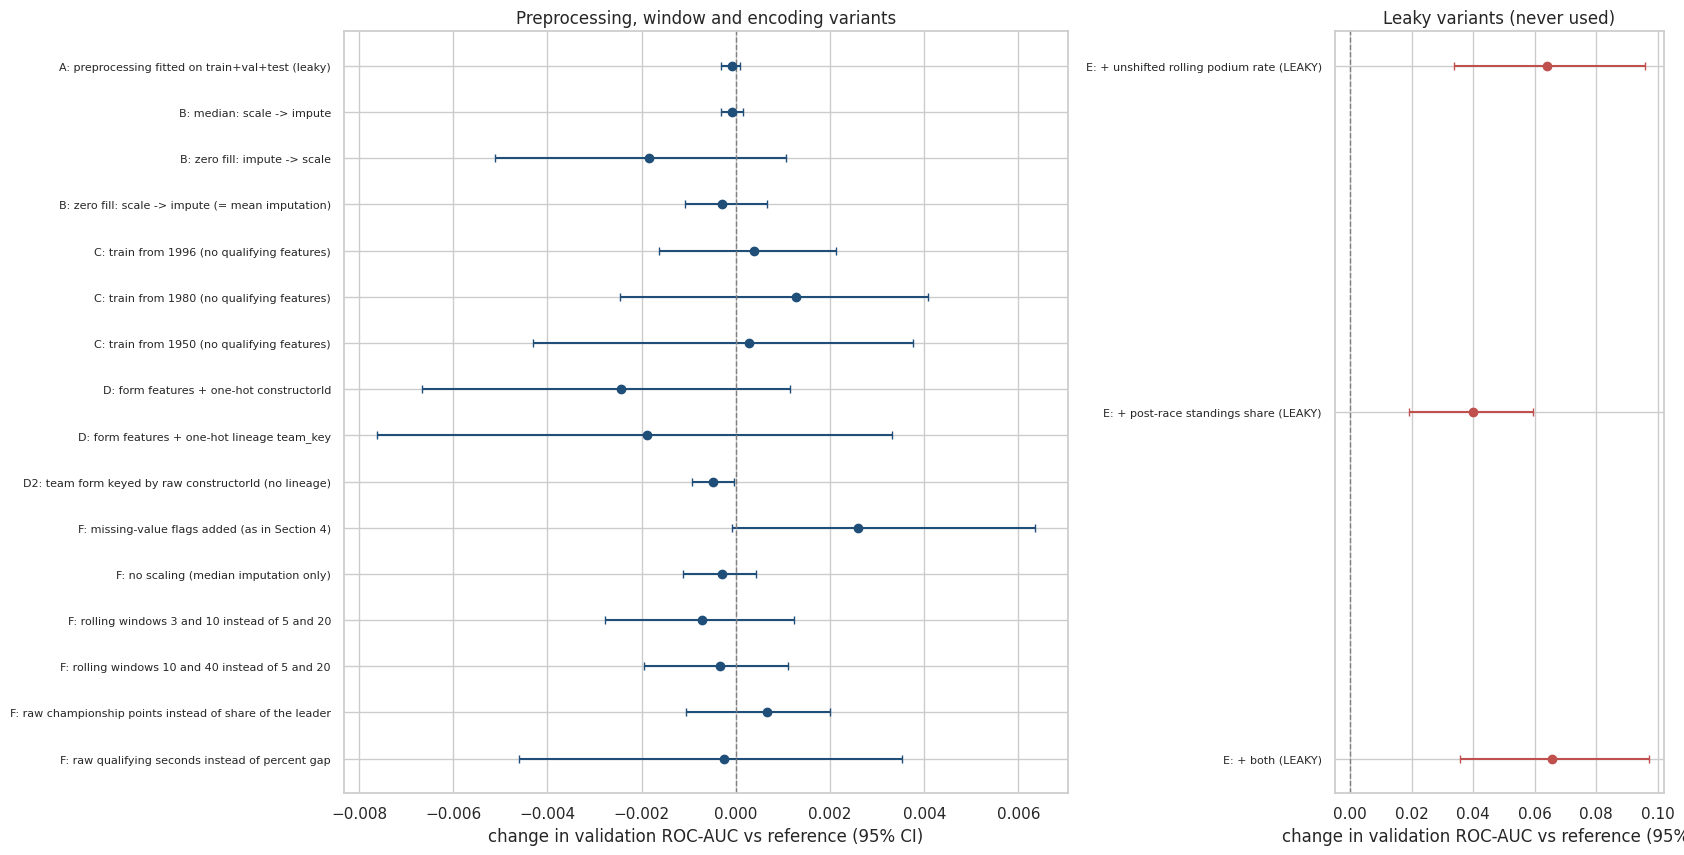

Experiment C variants are compared with the C reference (training from 2003 without qualifying features); all other variants with the main reference.


In [49]:
print("Takeaways for D2 and F (change in validation ROC-AUC against the reference, 95% CI from resampled races):")
for r in res_tbl[res_tbl["exp"].isin(["D2", "F"])].itertuples():
    print(f"  {r.exp:3s} {r.variant:55s} AUC {r.val_auc:.4f}, AP {r.val_ap:.4f}, "
          f"change {r.d_auc_vs_ref:+.4f} (CI {r.ci_lo:+.4f} to {r.ci_hi:+.4f}, {inside(r)})")

exp_pl = res_tbl[res_tbl["ci_lo"].notna()].reset_index(drop=True)
safe, leaky = exp_pl[exp_pl["exp"] != "E"], exp_pl[exp_pl["exp"] == "E"]
fig, axes = plt.subplots(1, 2, figsize=(17, 0.42 * len(safe) + 2), gridspec_kw={"width_ratios": [2.2, 1]})
for ax, d, title, colour in [(axes[0], safe, "Preprocessing, window and encoding variants", "#1f4e79"),
                             (axes[1], leaky, "Leaky variants (never used)", "#c0504d")]:
    y = np.arange(len(d))[::-1]
    lo = np.clip(d["d_auc_vs_ref"] - d["ci_lo"], 0, None)
    hi = np.clip(d["ci_hi"] - d["d_auc_vs_ref"], 0, None)
    ax.errorbar(d["d_auc_vs_ref"], y, xerr=[lo, hi], fmt="o", color=colour, capsize=3)
    ax.axvline(0, color="grey", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels((d["exp"] + ": " + d["variant"]).str.slice(0, 70), fontsize=8)
    ax.set_xlabel("change in validation ROC-AUC vs reference (95% CI)")
    ax.set_title(title)
save_show(fig, "s3_preprocessing_experiments")
print("Experiment C variants are compared with the C reference (training from 2003 without qualifying features); "
      "all other variants with the main reference.")

## 3.7 Save the modeling table and export the Section 3 report

The modeling table has one row per driver per race (unique on `raceId, driverId`), the identifiers, the split label, the target and every feature. `history` rows (1950-2002) are kept so form features have context but are not training rows in the main experiment.

In [50]:
ID_COLS = ["resultId", "raceId", "driverId", "constructorId", "team_key", "circuitId", "year", "round", "date", "split"]
modeling = feat[ID_COLS + ["podium"] + FEATS + ["era_pre2003"]].copy()
assert not modeling.duplicated(["raceId", "driverId"]).any()
assert modeling["podium"].isin([0, 1]).all()
modeling.to_csv("/kaggle/working/modeling_table.csv", index=False)
print("modeling table:", modeling.shape, "-> /kaggle/working/modeling_table.csv")
display(modeling.groupby("split").agg(rows=("podium", "size"), podium_rate=("podium", "mean")).round(4))
display(modeling[FEATS].describe().T[["count", "mean", "std", "min", "max"]].round(3))

modeling table: (24586, 40) -> /kaggle/working/modeling_table.csv


,rows,podium_rate
split,,
history,15676,0.1313
test,1352,0.1509
train,6783,0.1420
val,775,0.1510


,count,mean,std,min,max
grid_clean,24586.0,11.792,6.752,1.0,34.000
pit_lane_start,24586.0,0.004,0.059,0.0,1.000
qual_pos,10418.0,11.169,6.250,1.0,26.000
q1_gap_pct,10266.0,1.849,1.930,0.0,44.782
q2_gap_pct,5824.0,1.230,1.267,0.0,31.492
q3_gap_pct,3622.0,1.127,1.286,0.0,33.010
reached_q2,7965.0,0.731,0.443,0.0,1.000
reached_q3,7830.0,0.463,0.499,0.0,1.000
grid_minus_qual,10418.0,0.005,1.534,-9.0,23.000
qual_missing,24586.0,0.576,0.494,0.0,1.000


In [51]:
export_report("/kaggle/working/section3_results.pdf", S3_START, "s3_", "F1 Podium Prediction, Section 3 results")

Wrote /kaggle/working/section3_results.pdf: 5 text pages + 5 figure pages


# Section 4: Predictive Modeling

Three model families are trained on the same rows and the same 28 features from Section 3, and compared with the same metrics.

| Family | Role |
|---|---|
| Logistic regression (LR) | Statistical baseline. Simple, fast, easy to read |
| Random forest (RF) | Second statistical model. Captures interactions and non-linear effects |
| Shallow neural network (NN, Keras) | One or two hidden layers |

Every change is its own numbered attempt in its own section, with a computed before/after comparison against the attempt it is meant to improve. A change counts as helping or hurting only if a bootstrap that resamples whole races says so; otherwise it is reported as no reliable change.

Rules followed throughout:
- The preprocessing (median imputation with missing-value flags, then scaling) is fitted on training rows (2003-2019) only.
- Hyperparameters, early stopping and the decision threshold are chosen on the validation seasons (2020-2021) only.
- The test seasons (2022 onward) are scored once, in Section 4.13, for the already-selected models.
- Metrics: ROC-AUC and PR-AUC (threshold-free), then F1, precision and recall at one threshold per model. The threshold maximises F1 on validation. Because podiums are only about 14% of rows, PR-AUC is the main selection metric.
- A non-ML reference is included: "predict a podium if the driver starts in the top 3".

### How each model works, and its limits here

| Model | How it works | Main limitations for this task |
|---|---|---|
| **Logistic regression** | Adds up the (scaled) inputs, each multiplied by a learned weight, and passes the sum through a sigmoid to get a probability. The weights are fitted by maximising the likelihood of the training labels, with an L2 penalty (strength `1/C`) that shrinks them towards zero. | Linear in the log-odds: an interaction such as "good qualifying only matters in a strong car" cannot be represented unless it is engineered as a feature. Highly correlated inputs (grid and qualifying position, 0.97) share their weight arbitrarily, so single coefficients are not interpretable on their own. |
| **Random forest** | Grows many decision trees, each on a bootstrap sample of the training rows and considering a random subset of features at each split, and averages their votes. Each tree splits the data into boxes of similar podium rate. | Without depth and leaf limits it memorises the training seasons (attempt A3). Probabilities are coarse averages of leaf rates and it cannot extrapolate beyond values seen in training. |
| **Shallow neural network** | One or two dense hidden layers of ReLU units feed a sigmoid output; the weights are learned by gradient descent (Adam) on binary cross-entropy. Dropout and an L2 penalty limit overfitting; early stopping picks the epoch with the lowest validation loss. | Results move with the random starting weights (seed noise, section 4.9). With about 6,800 training rows it has little room to beat simpler models. Class weighting makes its probabilities uncalibrated. Its explanations need approximate Kernel SHAP. |

All three see the same rows and the same 28 features (45 columns after imputation flags and scaling).

In [52]:
import tensorflow as tf
from tensorflow import keras
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve
import joblib

S4_START = len(TEE.buf)   # the Section 4 report starts here
keras.utils.set_random_seed(SEED)
os.makedirs("/kaggle/working/models", exist_ok=True)

TR = feat[feat["split"] == "train"].reset_index(drop=True)
VA = feat[feat["split"] == "val"].reset_index(drop=True)
ytr, yva = TR["podium"].to_numpy(), VA["podium"].to_numpy()

def make_pre():
    return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                     ("sc", StandardScaler())])

PRE = make_pre().fit(TR[FEATS])
Xtr, Xva = PRE.transform(TR[FEATS]), PRE.transform(VA[FEATS])
PRE_NAMES = list(PRE.named_steps["imp"].get_feature_names_out(FEATS))
print(f"train {Xtr.shape} | val {Xva.shape} | podium rate train {ytr.mean():.3f}, val {yva.mean():.3f}")
print(f"{Xtr.shape[1] - len(FEATS)} missing-value flag columns were added for features that have gaps in the training rows:")
print("  " + ", ".join(n.replace("missingindicator_", "") for n in PRE_NAMES if n.startswith("missingindicator_")))

train (6783, 45) | val (775, 45) | podium rate train 0.142, val 0.151
17 missing-value flag columns were added for features that have gaps in the training rows:
  qual_pos, q1_gap_pct, q2_gap_pct, q3_gap_pct, reached_q2, reached_q3, grid_minus_qual, drv_podium_rate_5, drv_podium_rate_20, drv_avg_finish_5, con_podium_rate_5, con_podium_rate_20, con_avg_finish_5, con_mech_rate_20, drv_standing_pos_before, con_standing_pos_before, drv_circuit_podium_rate_prior


In [53]:
def best_threshold(y, p):
    ts = np.linspace(0.02, 0.90, 89)
    f1s = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in ts]
    return float(ts[int(np.argmax(f1s))])

def metrics_at(y, p, t):
    pred = (p >= t).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "f1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "thr": t}

def race_boots(df, B=300, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = df.groupby("raceId").indices
    ids = np.array(list(groups.keys()))
    return [np.concatenate([groups[r] for r in rng.choice(ids, len(ids), replace=True)]) for _ in range(B)]

BOOT_VA = race_boots(VA)

def ci_diff(y, p_ref, p_new, boots, fn):
    d = np.array([fn(y[i], p_new[i]) - fn(y[i], p_ref[i]) for i in boots])
    return np.percentile(d, [2.5, 97.5])

REG = {}   # attempt name -> everything needed later
def register(name, family, desc, model, p_tr, p_va):
    t = best_threshold(yva, p_va)
    REG[name] = {"family": family, "desc": desc, "model": model, "p_tr": p_tr, "p_va": p_va, "thr": t,
                 "tr": metrics_at(ytr, p_tr, t), "va": metrics_at(yva, p_va, t)}
    v, tr_ = REG[name]["va"], REG[name]["tr"]
    print(f"{name}: {desc}\n  validation  ROC-AUC {v['roc_auc']:.4f} | PR-AUC {v['pr_auc']:.4f} | F1 {v['f1']:.3f} "
          f"(precision {v['precision']:.3f}, recall {v['recall']:.3f}) at threshold {t:.2f}\n"
          f"  training    ROC-AUC {tr_['roc_auc']:.4f} | PR-AUC {tr_['pr_auc']:.4f} | F1 {tr_['f1']:.3f}")

def compare(new, ref):
    a, b = REG[ref], REG[new]
    out = []
    for key, label, fn in [("pr_auc", "PR-AUC", average_precision_score), ("roc_auc", "ROC-AUC", roc_auc_score)]:
        d = b["va"][key] - a["va"][key]
        lo, hi = ci_diff(yva, a["p_va"], b["p_va"], BOOT_VA, fn)
        word = "no reliable change" if lo <= 0 <= hi else ("helped" if d > 0 else "hurt")
        out.append(f"val {label} {a['va'][key]:.4f} -> {b['va'][key]:.4f} ({d:+.4f}, 95% CI {lo:+.4f} to {hi:+.4f}: {word})")
    gap_a = a["tr"]["pr_auc"] - a["va"]["pr_auc"]; gap_b = b["tr"]["pr_auc"] - b["va"]["pr_auc"]
    print(f"BEFORE {ref} -> AFTER {new}\n  " + "\n  ".join(out) +
          f"\n  val F1 {a['va']['f1']:.3f} -> {b['va']['f1']:.3f}; train-minus-val PR-AUC gap {gap_a:+.3f} -> {gap_b:+.3f}")

## 4.1 Reference points

**Rule reference.** Predict a podium whenever the driver starts in the top 3. It uses no learning at all, so any model has to beat it to justify itself.

**A0, the baseline.** Logistic regression with default settings (L2 penalty, C = 1) on all features. This is the starting point every later attempt is compared with.

In [54]:
def rule_metrics(df):
    y = df["podium"].to_numpy()
    score = -df["grid_clean"].to_numpy(float)
    pred = (df["grid_clean"].to_numpy() <= 3).astype(int)
    return {"roc_auc": roc_auc_score(y, score), "pr_auc": average_precision_score(y, score),
            "f1": f1_score(y, pred), "precision": precision_score(y, pred), "recall": recall_score(y, pred), "thr": np.nan}
RULE = {"tr": rule_metrics(TR), "va": rule_metrics(VA)}
v = RULE["va"]
print(f"Rule 'top 3 on the grid': validation ROC-AUC {v['roc_auc']:.4f} | PR-AUC {v['pr_auc']:.4f} | "
      f"F1 {v['f1']:.3f} (precision {v['precision']:.3f}, recall {v['recall']:.3f})")

m0 = LogisticRegression(max_iter=3000).fit(Xtr, ytr)
register("A0", "LR", "logistic regression, C=1, all features (baseline)", m0,
         m0.predict_proba(Xtr)[:, 1], m0.predict_proba(Xva)[:, 1])

Rule 'top 3 on the grid': validation ROC-AUC 0.9102 | PR-AUC 0.6478 | F1 0.695 (precision 0.698, recall 0.692)
A0: logistic regression, C=1, all features (baseline)
  validation  ROC-AUC 0.9359 | PR-AUC 0.7413 | F1 0.714 (precision 0.659, recall 0.778) at threshold 0.24
  training    ROC-AUC 0.9338 | PR-AUC 0.6986 | F1 0.673


## 4.2 Attempt A1: tune the regularisation strength of the logistic regression

**Change:** search C (inverse penalty strength) over a log grid and keep the value with the best validation PR-AUC.

**Why it might help:** 28 features plus flags, many highly correlated (grid and qualifying position correlate at 0.97). A stronger penalty can stabilise the coefficients; a weaker one lets informative features speak. The default C = 1 is arbitrary.

In [55]:
sweep = []
for c_val in [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
    m = LogisticRegression(C=c_val, max_iter=3000).fit(Xtr, ytr)
    pv = m.predict_proba(Xva)[:, 1]
    sweep.append({"C": c_val, "val_pr_auc": average_precision_score(yva, pv), "val_roc_auc": roc_auc_score(yva, pv)})
sweep = pd.DataFrame(sweep)
display(sweep.round(4))
C_BEST = float(sweep.loc[sweep["val_pr_auc"].idxmax(), "C"])
m1 = LogisticRegression(C=C_BEST, max_iter=3000).fit(Xtr, ytr)
register("A1", "LR", f"logistic regression, C={C_BEST:g} (tuned on validation PR-AUC)", m1,
         m1.predict_proba(Xtr)[:, 1], m1.predict_proba(Xva)[:, 1])
compare("A1", "A0")
if C_BEST == 1.0:
    print("  The search kept the default C = 1, so A1 is identical to A0: tuning confirmed the baseline setting.")

,C,val_pr_auc,val_roc_auc
0,0.003,0.7212,0.9280
1,0.010,0.7300,0.9323
2,0.030,0.7344,0.9344
3,0.100,0.7394,0.9358
4,0.300,0.7420,0.9359
5,1.000,0.7413,0.9359
6,3.000,0.7419,0.9360
7,10.000,0.7415,0.9359


A1: logistic regression, C=0.3 (tuned on validation PR-AUC)
  validation  ROC-AUC 0.9359 | PR-AUC 0.7420 | F1 0.709 (precision 0.657, recall 0.769) at threshold 0.24
  training    ROC-AUC 0.9338 | PR-AUC 0.6980 | F1 0.673
BEFORE A0 -> AFTER A1
  val PR-AUC 0.7413 -> 0.7420 (+0.0007, 95% CI -0.0013 to +0.0035: no reliable change)
  val ROC-AUC 0.9359 -> 0.9359 (+0.0000, 95% CI -0.0005 to +0.0005: no reliable change)
  val F1 0.714 -> 0.709; train-minus-val PR-AUC gap -0.043 -> -0.044


## 4.3 Attempt A2: class weighting for the logistic regression

**Change:** `class_weight="balanced"` at the tuned C, so a missed podium costs about six times as much as a false alarm during training.

**Why it might help:** podiums are about 14% of rows. Weighting often improves recall. It shifts the predicted probabilities upwards, which matters for the threshold but should change the ranking (AUC) very little, because the decision threshold is already tuned for F1.

In [56]:
m2 = LogisticRegression(C=C_BEST, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
register("A2", "LR", f"logistic regression, C={C_BEST:g}, class_weight=balanced", m2,
         m2.predict_proba(Xtr)[:, 1], m2.predict_proba(Xva)[:, 1])
compare("A2", "A1")

A2: logistic regression, C=0.3, class_weight=balanced
  validation  ROC-AUC 0.9353 | PR-AUC 0.7403 | F1 0.711 (precision 0.662, recall 0.769) at threshold 0.64
  training    ROC-AUC 0.9338 | PR-AUC 0.6919 | F1 0.666
BEFORE A1 -> AFTER A2
  val PR-AUC 0.7420 -> 0.7403 (-0.0016, 95% CI -0.0092 to +0.0051: no reliable change)
  val ROC-AUC 0.9359 -> 0.9353 (-0.0006, 95% CI -0.0025 to +0.0012: no reliable change)
  val F1 0.709 -> 0.711; train-minus-val PR-AUC gap -0.044 -> -0.048


## 4.4 Attempt A3: random forest with default depth

**Change:** a second statistical model. 300 trees, no depth limit, no minimum leaf size.

**Why it might help:** a forest can model non-linear effects and interactions, such as "good qualifying only matters in a strong car", that a linear model cannot.

**Risk:** fully grown trees memorise the training set. A big train-minus-validation gap is expected here and motivates A4.

In [57]:
rf3 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
register("A3", "RF", "random forest, 300 trees, unlimited depth", rf3,
         rf3.predict_proba(Xtr)[:, 1], rf3.predict_proba(Xva)[:, 1])
compare("A3", "A0")

A3: random forest, 300 trees, unlimited depth
  validation  ROC-AUC 0.9282 | PR-AUC 0.6953 | F1 0.707 (precision 0.713, recall 0.701) at threshold 0.39
  training    ROC-AUC 1.0000 | PR-AUC 1.0000 | F1 1.000
BEFORE A0 -> AFTER A3
  val PR-AUC 0.7413 -> 0.6953 (-0.0459, 95% CI -0.0909 to -0.0023: hurt)
  val ROC-AUC 0.9359 -> 0.9282 (-0.0077, 95% CI -0.0164 to +0.0000: no reliable change)
  val F1 0.714 -> 0.707; train-minus-val PR-AUC gap -0.043 -> +0.305


## 4.5 Attempt A4: regularise the random forest

**Change:** limit tree depth and require a minimum number of rows per leaf, searched over a small grid on validation PR-AUC (`max_features="sqrt"`).

**Why it might help:** shallower trees with bigger leaves average out noise instead of memorising it, which usually closes the train-validation gap and improves validation scores.

In [58]:
grid_rows = []
for depth in [4, 6, 8, 12]:
    for leaf in [5, 20, 50]:
        m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, max_features="sqrt",
                                   random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
        pv = m.predict_proba(Xva)[:, 1]
        grid_rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                          "val_pr_auc": average_precision_score(yva, pv), "val_roc_auc": roc_auc_score(yva, pv)})
rf_grid = pd.DataFrame(grid_rows)
display(rf_grid.sort_values("val_pr_auc", ascending=False).round(4).reset_index(drop=True))
bg = rf_grid.loc[rf_grid["val_pr_auc"].idxmax()]
RF_DEPTH, RF_LEAF = int(bg["max_depth"]), int(bg["min_samples_leaf"])
rf4 = RandomForestClassifier(n_estimators=300, max_depth=RF_DEPTH, min_samples_leaf=RF_LEAF, max_features="sqrt",
                             random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
register("A4", "RF", f"random forest, depth {RF_DEPTH}, min leaf {RF_LEAF}, sqrt features", rf4,
         rf4.predict_proba(Xtr)[:, 1], rf4.predict_proba(Xva)[:, 1])
compare("A4", "A3")
print()
compare("A4", "A1")

,max_depth,min_samples_leaf,val_pr_auc,val_roc_auc
0,8,50,0.7439,0.9351
1,12,50,0.7437,0.9348
2,6,50,0.7421,0.9347
3,8,20,0.7402,0.9338
4,4,20,0.7397,0.9321
5,4,50,0.7393,0.9332
6,6,20,0.7377,0.9329
7,12,20,0.7363,0.9338
8,6,5,0.7347,0.9319
9,4,5,0.7343,0.9320


A4: random forest, depth 8, min leaf 50, sqrt features
  validation  ROC-AUC 0.9351 | PR-AUC 0.7439 | F1 0.717 (precision 0.708, recall 0.726) at threshold 0.36
  training    ROC-AUC 0.9440 | PR-AUC 0.7277 | F1 0.693
BEFORE A3 -> AFTER A4
  val PR-AUC 0.6953 -> 0.7439 (+0.0486, 95% CI +0.0115 to +0.0766: helped)
  val ROC-AUC 0.9282 -> 0.9351 (+0.0069, 95% CI +0.0008 to +0.0126: helped)
  val F1 0.707 -> 0.717; train-minus-val PR-AUC gap +0.305 -> -0.016

BEFORE A1 -> AFTER A4
  val PR-AUC 0.7420 -> 0.7439 (+0.0020, 95% CI -0.0201 to +0.0230: no reliable change)
  val ROC-AUC 0.9359 -> 0.9351 (-0.0009, 95% CI -0.0060 to +0.0038: no reliable change)
  val F1 0.709 -> 0.717; train-minus-val PR-AUC gap -0.044 -> -0.016


## 4.6 Attempt A5: class weighting for the random forest

**Change:** `class_weight="balanced_subsample"` with the A4 settings.

**Why it might help:** the same imbalance argument as A2. In a forest, weighting changes which splits look good, so it can change the ranking as well as the probabilities.

In [59]:
rf5 = RandomForestClassifier(n_estimators=300, max_depth=RF_DEPTH, min_samples_leaf=RF_LEAF, max_features="sqrt",
                             class_weight="balanced_subsample", random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
register("A5", "RF", f"random forest as A4 + class_weight=balanced_subsample", rf5,
         rf5.predict_proba(Xtr)[:, 1], rf5.predict_proba(Xva)[:, 1])
compare("A5", "A4")

A5: random forest as A4 + class_weight=balanced_subsample
  validation  ROC-AUC 0.9326 | PR-AUC 0.7391 | F1 0.721 (precision 0.724, recall 0.718) at threshold 0.77
  training    ROC-AUC 0.9444 | PR-AUC 0.7245 | F1 0.677
BEFORE A4 -> AFTER A5
  val PR-AUC 0.7439 -> 0.7391 (-0.0049, 95% CI -0.0149 to +0.0066: no reliable change)
  val ROC-AUC 0.9351 -> 0.9326 (-0.0025, 95% CI -0.0059 to +0.0003: no reliable change)
  val F1 0.717 -> 0.721; train-minus-val PR-AUC gap -0.016 -> -0.015


## 4.7 Attempt A6: shallow neural network, plain version

**Architecture:** one hidden layer of 16 ReLU units, sigmoid output, Adam (learning rate 0.001), batch size 128, binary cross-entropy. No regularisation and no early stopping: it trains for a fixed 60 epochs.

**Why start here:** it is the simplest network that can differ from logistic regression. We watch the learning curve to see whether it overfits. Validation data is only watched here, not used to stop training.

In [60]:
def build_nn(n_in, hidden=(16,), dropout=0.0, l2=0.0, lr=1e-3, seed=SEED):
    keras.utils.set_random_seed(seed)
    layers = [keras.layers.Input((n_in,))]
    for h in hidden:
        layers.append(keras.layers.Dense(h, activation="relu",
                                         kernel_regularizer=keras.regularizers.l2(l2) if l2 else None))
        if dropout:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(layers)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return m

def fit_nn(hidden, dropout=0.0, l2=0.0, early_stop=False, epochs=60, class_weight=None, seed=SEED):
    m = build_nn(Xtr.shape[1], hidden, dropout, l2, seed=seed)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)] if early_stop else []
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=128, verbose=0,
              callbacks=cbs, class_weight=class_weight)
    return m, h.history

NN_HIST = {}
m6, NN_HIST["A6"] = fit_nn((16,), epochs=60)
register("A6", "NN", "NN 1x16 ReLU, no regularisation, fixed 60 epochs", m6,
         m6.predict(Xtr, verbose=0).ravel(), m6.predict(Xva, verbose=0).ravel())
compare("A6", "A0")
best_ep = int(np.argmin(NN_HIST["A6"]["val_loss"])) + 1
print(f"  validation loss was lowest at epoch {best_ep} of 60 "
      f"({min(NN_HIST['A6']['val_loss']):.4f}) and ended at {NN_HIST['A6']['val_loss'][-1]:.4f}")

I0000 00:00:1792353722.093714      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792353722.097894      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792353725.407044     376 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


A6: NN 1x16 ReLU, no regularisation, fixed 60 epochs
  validation  ROC-AUC 0.9304 | PR-AUC 0.7383 | F1 0.716 (precision 0.722, recall 0.709) at threshold 0.45
  training    ROC-AUC 0.9444 | PR-AUC 0.7265 | F1 0.668
BEFORE A0 -> AFTER A6
  val PR-AUC 0.7413 -> 0.7383 (-0.0030, 95% CI -0.0456 to +0.0327: no reliable change)
  val ROC-AUC 0.9359 -> 0.9304 (-0.0055, 95% CI -0.0122 to +0.0019: no reliable change)
  val F1 0.714 -> 0.716; train-minus-val PR-AUC gap -0.043 -> -0.012
  validation loss was lowest at epoch 52 of 60 (0.2250) and ended at 0.2251


## 4.8 Attempt A7: regularised neural network with early stopping

**Change:** two hidden layers (32 and 16 units), dropout 0.3, L2 penalty 1e-4, and early stopping on validation loss (patience 15, best weights restored, at most 200 epochs).

**Why it might help:** the plain network can fit noise in 6,783 rows. Dropout and the weight penalty reduce that, and early stopping picks the epoch where validation loss is lowest. A second layer adds some flexibility.

**Caveat:** early stopping looks at the validation seasons, so validation scores for this attempt are slightly optimistic. The test set is what settles it.

In [61]:
m7, NN_HIST["A7"] = fit_nn((32, 16), dropout=0.3, l2=1e-4, early_stop=True, epochs=200)
register("A7", "NN", "NN 32-16 ReLU, dropout 0.3, L2 1e-4, early stopping", m7,
         m7.predict(Xtr, verbose=0).ravel(), m7.predict(Xva, verbose=0).ravel())
print(f"  stopped after {len(NN_HIST['A7']['loss'])} epochs, best epoch {int(np.argmin(NN_HIST['A7']['val_loss'])) + 1}")
compare("A7", "A6")
print()
compare("A7", "A0")

A7: NN 32-16 ReLU, dropout 0.3, L2 1e-4, early stopping
  validation  ROC-AUC 0.9294 | PR-AUC 0.7358 | F1 0.704 (precision 0.599, recall 0.855) at threshold 0.20
  training    ROC-AUC 0.9458 | PR-AUC 0.7331 | F1 0.664
  stopped after 64 epochs, best epoch 49
BEFORE A6 -> AFTER A7
  val PR-AUC 0.7383 -> 0.7358 (-0.0025, 95% CI -0.0317 to +0.0198: no reliable change)
  val ROC-AUC 0.9304 -> 0.9294 (-0.0010, 95% CI -0.0056 to +0.0031: no reliable change)
  val F1 0.716 -> 0.704; train-minus-val PR-AUC gap -0.012 -> -0.003

BEFORE A0 -> AFTER A7
  val PR-AUC 0.7413 -> 0.7358 (-0.0055, 95% CI -0.0484 to +0.0328: no reliable change)
  val ROC-AUC 0.9359 -> 0.9294 (-0.0065, 95% CI -0.0145 to +0.0017: no reliable change)
  val F1 0.714 -> 0.704; train-minus-val PR-AUC gap -0.043 -> -0.003


## 4.9 Attempt A8: class weights for the neural network, and seed stability

**Change:** the A7 network trained with a positive-class weight equal to the negative-to-positive ratio of the training rows.

**Why it might help:** the same imbalance argument as A2 and A5.

**Seed stability.** Neural networks depend on the random starting weights. The A7 configuration is retrained with five seeds to show how much the validation score moves from the seed alone, which is the noise floor for any NN comparison.

A8: NN as A7 + positive class weight 6.0
  validation  ROC-AUC 0.9301 | PR-AUC 0.7420 | F1 0.702 (precision 0.721, recall 0.684) at threshold 0.82
  training    ROC-AUC 0.9454 | PR-AUC 0.7231 | F1 0.673
BEFORE A7 -> AFTER A8
  val PR-AUC 0.7358 -> 0.7420 (+0.0062, 95% CI -0.0146 to +0.0287: no reliable change)
  val ROC-AUC 0.9294 -> 0.9301 (+0.0006, 95% CI -0.0027 to +0.0040: no reliable change)
  val F1 0.704 -> 0.702; train-minus-val PR-AUC gap -0.003 -> -0.019


,seed,val_roc_auc,val_pr_auc
0,11,0.9288,0.7308
1,22,0.9307,0.7402
2,33,0.9272,0.7136
3,44,0.9276,0.7414
4,55,0.9298,0.7324


A7 configuration over 5 seeds: val PR-AUC 0.7317 +/- 0.0111, val ROC-AUC 0.9288 +/- 0.0015. Differences between NN attempts smaller than about this spread are seed noise.


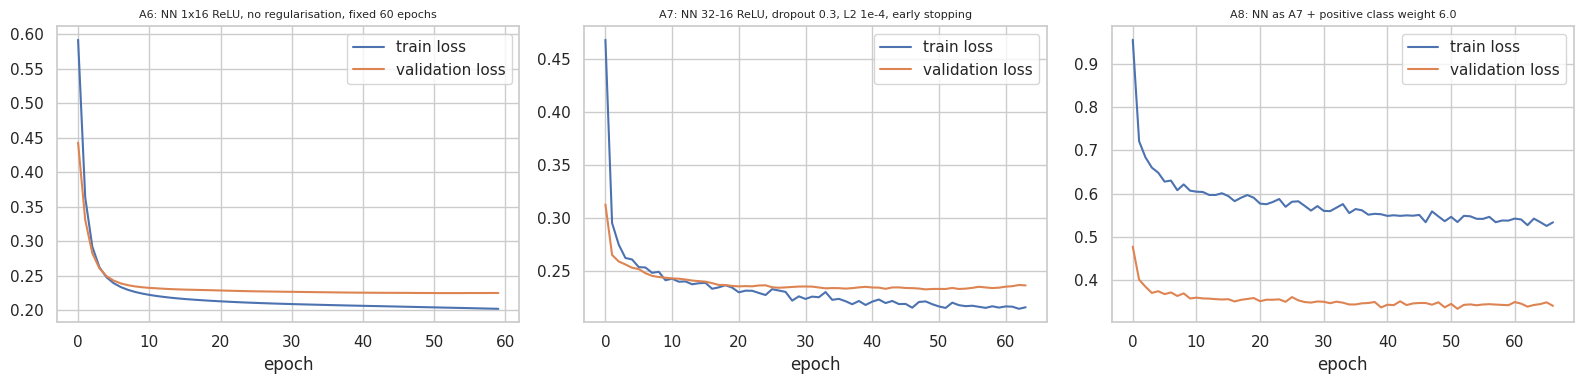

In [62]:
w_pos = float((ytr == 0).sum() / (ytr == 1).sum())
m8, NN_HIST["A8"] = fit_nn((32, 16), dropout=0.3, l2=1e-4, early_stop=True, epochs=200, class_weight={0: 1.0, 1: w_pos})
register("A8", "NN", f"NN as A7 + positive class weight {w_pos:.1f}", m8,
         m8.predict(Xtr, verbose=0).ravel(), m8.predict(Xva, verbose=0).ravel())
compare("A8", "A7")

rows_ = []
for s in [11, 22, 33, 44, 55]:
    ms, _ = fit_nn((32, 16), dropout=0.3, l2=1e-4, early_stop=True, epochs=200, seed=s)
    pv = ms.predict(Xva, verbose=0).ravel()
    rows_.append({"seed": s, "val_roc_auc": roc_auc_score(yva, pv), "val_pr_auc": average_precision_score(yva, pv)})
seed_tbl = pd.DataFrame(rows_)
display(seed_tbl.round(4))
print(f"A7 configuration over 5 seeds: val PR-AUC {seed_tbl['val_pr_auc'].mean():.4f} +/- {seed_tbl['val_pr_auc'].std():.4f}, "
      f"val ROC-AUC {seed_tbl['val_roc_auc'].mean():.4f} +/- {seed_tbl['val_roc_auc'].std():.4f}. "
      "Differences between NN attempts smaller than about this spread are seed noise.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k in zip(axes, ["A6", "A7", "A8"]):
    h = NN_HIST[k]
    ax.plot(h["loss"], label="train loss"); ax.plot(h["val_loss"], label="validation loss")
    ax.set_title(f"{k}: {REG[k]['desc']}", fontsize=8); ax.set_xlabel("epoch"); ax.legend()
save_show(fig, "s4_nn_learning_curves")

## 4.10 All attempts side by side and the selection of one model per family

Selection rule: within each family, the attempt with the highest validation PR-AUC. PR-AUC is used because it rewards ranking the rare true podium finishers above everyone else, which is the real task.

Many differences between attempts are smaller than the noise of a 39-race validation set, so after the selection the cell below tests the selected attempt against every other attempt in its family with the same race-level bootstrap. Where the interval includes zero the attempts are **statistically tied**: the validation data cannot say which is better. In that case we keep the highest-scoring attempt only if it is also defensible on design grounds, and say so:
- **LR:** A0, A1 and A2 are the same model. A1 differs from A0 only in a penalty strength chosen by search instead of the library default, so it is not more complex.
- **RF:** A4 is the regularised forest that removed A3's overfitting (train-minus-validation gap +0.30 to about 0). A5 only adds class weights.
- **NN:** A7 and A8 stop training at the epoch with the lowest validation loss and use dropout and L2. A6 trains for an arbitrary fixed 60 epochs with no regularisation. If A8 is selected over A6 while tied, the reason is this principled stopping rule, not a better score, and the seed spread in 4.9 shows the size of the noise.

Whatever is selected, the test comparison in 4.13 is always against the baseline A0, which is the fair question: does the extra complexity pay off on unseen seasons?

In [63]:
rows_ = [{"attempt": "Rule", "family": "rule", "description": "podium if start in top 3",
          "val_roc_auc": RULE["va"]["roc_auc"], "val_pr_auc": RULE["va"]["pr_auc"], "val_f1": RULE["va"]["f1"],
          "val_precision": RULE["va"]["precision"], "val_recall": RULE["va"]["recall"], "thr": np.nan,
          "train_pr_auc": RULE["tr"]["pr_auc"], "gap": RULE["tr"]["pr_auc"] - RULE["va"]["pr_auc"]}]
for k, r in REG.items():
    rows_.append({"attempt": k, "family": r["family"], "description": r["desc"],
                  "val_roc_auc": r["va"]["roc_auc"], "val_pr_auc": r["va"]["pr_auc"], "val_f1": r["va"]["f1"],
                  "val_precision": r["va"]["precision"], "val_recall": r["va"]["recall"], "thr": r["thr"],
                  "train_pr_auc": r["tr"]["pr_auc"], "gap": r["tr"]["pr_auc"] - r["va"]["pr_auc"]})
att = pd.DataFrame(rows_)
display(att.drop(columns="description").round(4))

BEST = {}
for fam in ["LR", "RF", "NN"]:
    sub = att[att["family"] == fam]
    BEST[fam] = sub.loc[sub["val_pr_auc"].idxmax(), "attempt"]
print("\nSelected per family (highest validation PR-AUC): " + "; ".join(f"{f}: {k} ({REG[k]['desc']})" for f, k in BEST.items()))

print("\nIs the selected attempt reliably better than the others in its family? (validation PR-AUC, paired bootstrap over races)")
TIES = {}
for fam, k_best in BEST.items():
    tied = []
    for k_other in att.loc[att["family"] == fam, "attempt"]:
        if k_other == k_best:
            continue
        lo, hi = ci_diff(yva, REG[k_other]["p_va"], REG[k_best]["p_va"], BOOT_VA, average_precision_score)
        d_ = REG[k_best]["va"]["pr_auc"] - REG[k_other]["va"]["pr_auc"]
        is_tie = lo <= 0 <= hi
        if is_tie:
            tied.append(k_other)
        print(f"  {fam}: {k_best} minus {k_other}: {d_:+.4f} (95% CI {lo:+.4f} to {hi:+.4f}) -> "
              + ("statistically tied" if is_tie else "selected attempt is reliably better"))
    TIES[fam] = tied
print("Statistically tied with the selected attempt: " + "; ".join(f"{f}: {', '.join(t) or 'none'}" for f, t in TIES.items()))

,attempt,family,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall,thr,train_pr_auc,gap
0,Rule,rule,0.9102,0.6478,0.6953,0.6983,0.6923,NaN,0.6279,-0.0198
1,A0,LR,0.9359,0.7413,0.7137,0.6594,0.7778,0.24,0.6986,-0.0427
2,A1,LR,0.9359,0.7420,0.7087,0.6569,0.7692,0.24,0.6980,-0.0440
3,A2,LR,0.9353,0.7403,0.7115,0.6618,0.7692,0.64,0.6919,-0.0485
4,A3,RF,0.9282,0.6953,0.7069,0.7130,0.7009,0.39,1.0000,0.3047
5,A4,RF,0.9351,0.7439,0.7173,0.7083,0.7265,0.36,0.7277,-0.0162
6,A5,RF,0.9326,0.7391,0.7210,0.7241,0.7179,0.77,0.7245,-0.0145
7,A6,NN,0.9304,0.7383,0.7155,0.7217,0.7094,0.45,0.7265,-0.0118
8,A7,NN,0.9294,0.7358,0.7042,0.5988,0.8547,0.20,0.7331,-0.0027
9,A8,NN,0.9301,0.7420,0.7018,0.7207,0.6838,0.82,0.7231,-0.0189



Selected per family (highest validation PR-AUC): LR: A1 (logistic regression, C=0.3 (tuned on validation PR-AUC)); RF: A4 (random forest, depth 8, min leaf 50, sqrt features); NN: A8 (NN as A7 + positive class weight 6.0)

Is the selected attempt reliably better than the others in its family? (validation PR-AUC, paired bootstrap over races)
  LR: A1 minus A0: +0.0007 (95% CI -0.0013 to +0.0035) -> statistically tied
  LR: A1 minus A2: +0.0016 (95% CI -0.0051 to +0.0092) -> statistically tied
  RF: A4 minus A3: +0.0486 (95% CI +0.0115 to +0.0766) -> selected attempt is reliably better
  RF: A4 minus A5: +0.0049 (95% CI -0.0066 to +0.0149) -> statistically tied
  NN: A8 minus A6: +0.0037 (95% CI -0.0181 to +0.0257) -> statistically tied
  NN: A8 minus A7: +0.0062 (95% CI -0.0146 to +0.0287) -> statistically tied
Statistically tied with the selected attempt: LR: A0, A2; RF: A5; NN: A6, A7


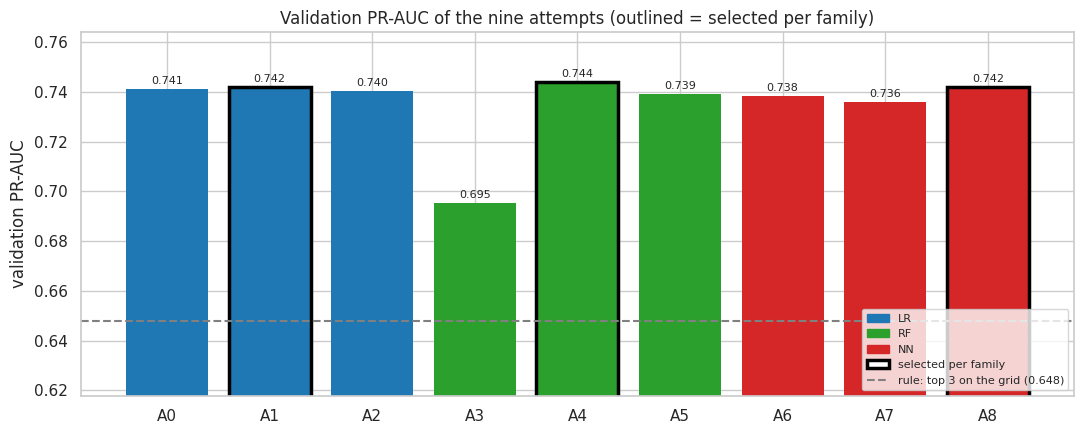

In [64]:
fam_col = {"LR": "#1f77b4", "RF": "#2ca02c", "NN": "#d62728"}
a_ = att[att["family"] != "rule"].reset_index(drop=True)
sel = set(BEST.values())
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(a_["attempt"], a_["val_pr_auc"], color=[fam_col[f] for f in a_["family"]],
       edgecolor=["black" if k in sel else "none" for k in a_["attempt"]], linewidth=2.5)
for i, v in enumerate(a_["val_pr_auc"]):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=8)
ax.axhline(RULE["va"]["pr_auc"], color="grey", ls="--", label=f"rule: top 3 on the grid ({RULE['va']['pr_auc']:.3f})")
ax.set_ylim(min(a_["val_pr_auc"].min(), RULE["va"]["pr_auc"]) - 0.03, a_["val_pr_auc"].max() + 0.02)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_col.values()]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", linewidth=2.5))
ax.legend(handles + [ax.get_lines()[0]], list(fam_col) + ["selected per family", ax.get_lines()[0].get_label()],
          fontsize=8, loc="lower right")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Validation PR-AUC of the nine attempts (outlined = selected per family)")
save_show(fig, "s4_attempts_val_pr_auc")

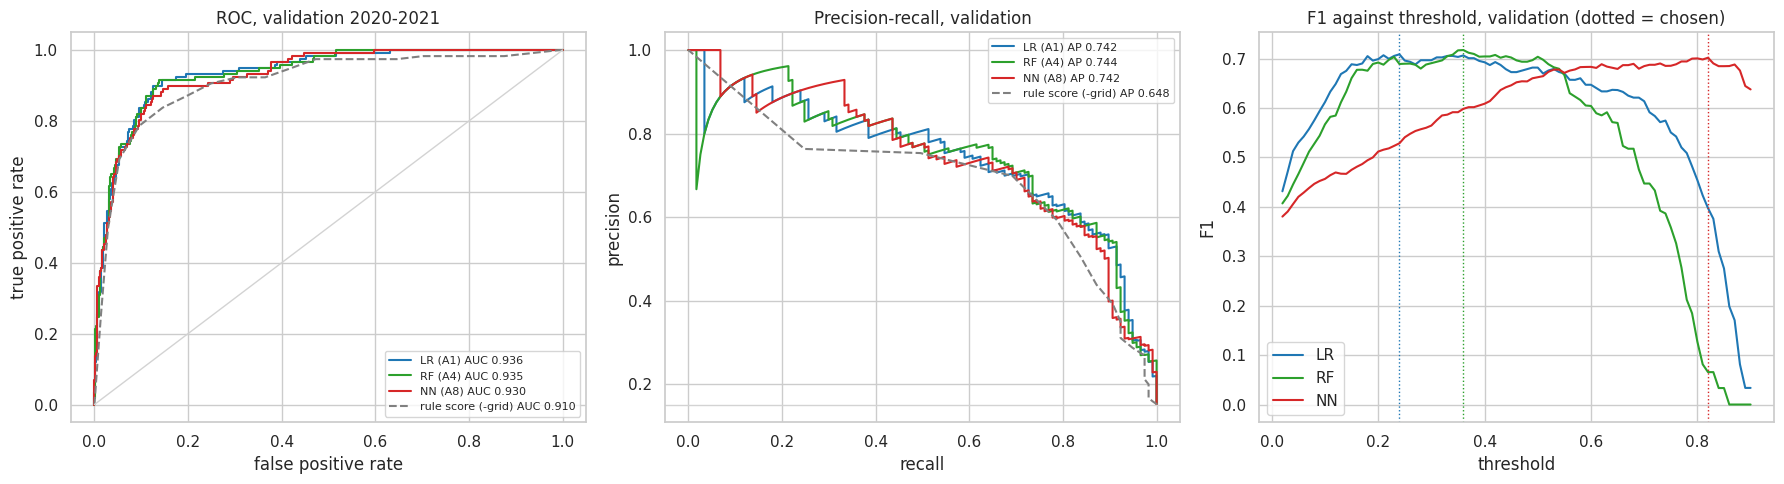

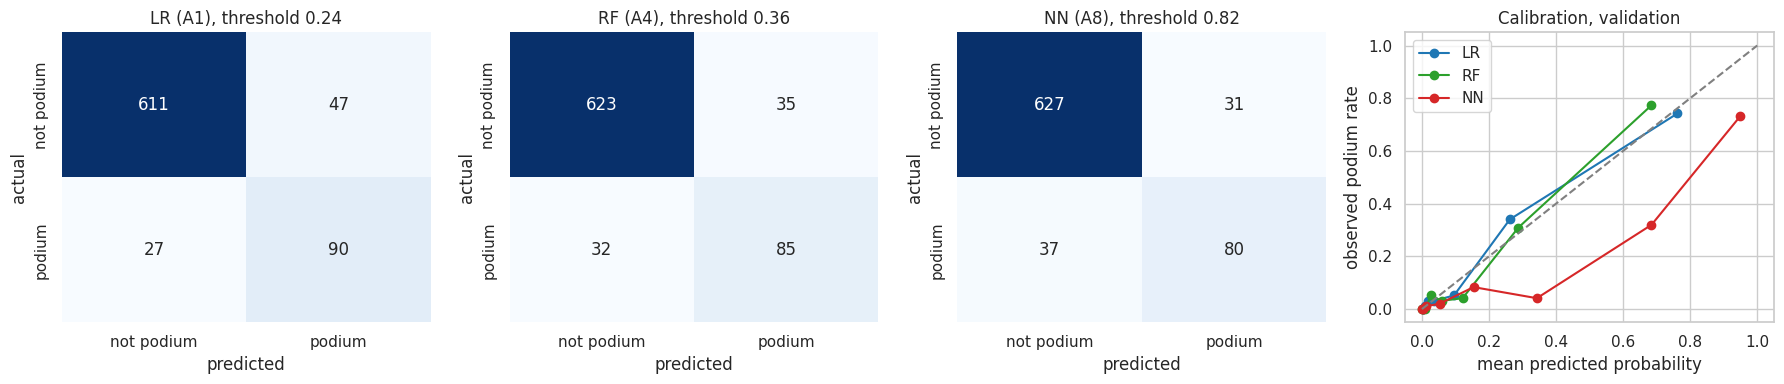

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
names = {"LR": BEST["LR"], "RF": BEST["RF"], "NN": BEST["NN"]}
cols = {"LR": "#1f77b4", "RF": "#2ca02c", "NN": "#d62728"}
for fam, k in names.items():
    p = REG[k]["p_va"]
    fpr, tpr, _ = roc_curve(yva, p); axes[0].plot(fpr, tpr, color=cols[fam], label=f"{fam} ({k}) AUC {REG[k]['va']['roc_auc']:.3f}")
    pr, rc, _ = precision_recall_curve(yva, p); axes[1].plot(rc, pr, color=cols[fam], label=f"{fam} ({k}) AP {REG[k]['va']['pr_auc']:.3f}")
    ts = np.linspace(0.02, 0.9, 89)
    axes[2].plot(ts, [f1_score(yva, (p >= t).astype(int), zero_division=0) for t in ts], color=cols[fam], label=f"{fam}")
    axes[2].axvline(REG[k]["thr"], color=cols[fam], ls=":", lw=1)
sc = -VA["grid_clean"].to_numpy(float)
fpr, tpr, _ = roc_curve(yva, sc); axes[0].plot(fpr, tpr, color="grey", ls="--", label=f"rule score (-grid) AUC {RULE['va']['roc_auc']:.3f}")
pr, rc, _ = precision_recall_curve(yva, sc); axes[1].plot(rc, pr, color="grey", ls="--", label=f"rule score (-grid) AP {RULE['va']['pr_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], color="lightgrey", lw=1)
axes[0].set_title("ROC, validation 2020-2021"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].legend(fontsize=8)
axes[1].axhline(yva.mean(), color="lightgrey", lw=1)
axes[1].set_title("Precision-recall, validation"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(fontsize=8)
axes[2].set_title("F1 against threshold, validation (dotted = chosen)"); axes[2].set_xlabel("threshold"); axes[2].set_ylabel("F1"); axes[2].legend()
save_show(fig, "s4_curves_validation")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (fam, k) in zip(axes[:3], names.items()):
    cm = confusion_matrix(yva, (REG[k]["p_va"] >= REG[k]["thr"]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["not podium", "podium"], yticklabels=["not podium", "podium"])
    ax.set_title(f"{fam} ({k}), threshold {REG[k]['thr']:.2f}"); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
for fam, k in names.items():
    fr, mp = calibration_curve(yva, REG[k]["p_va"], n_bins=8, strategy="quantile")
    axes[3].plot(mp, fr, marker="o", color=cols[fam], label=fam)
axes[3].plot([0, 1], [0, 1], color="grey", ls="--"); axes[3].set_title("Calibration, validation")
axes[3].set_xlabel("mean predicted probability"); axes[3].set_ylabel("observed podium rate"); axes[3].legend()
save_show(fig, "s4_confusion_calibration")

## 4.11 What the attempts tell us

Computed from the table above: which changes helped, which did not, and how the families compare.

In [66]:
def v(k, m="pr_auc"): return REG[k]["va"][m]
print("Validation PR-AUC by attempt: " + ", ".join(f"{k} {v(k):.3f}" for k in REG))
print(f"Rule reference PR-AUC {RULE['va']['pr_auc']:.3f}, F1 {RULE['va']['f1']:.3f}.")
bl = "A0"
for fam, k in BEST.items():
    lo, hi = ci_diff(yva, REG[bl]["p_va"], REG[k]["p_va"], BOOT_VA, average_precision_score)
    print(f"  {fam} best = {k}: PR-AUC {v(k):.4f} vs baseline A0 {v(bl):.4f} "
          f"(difference {v(k) - v(bl):+.4f}, 95% CI {lo:+.4f} to {hi:+.4f})")
over = att[att["gap"] > 0.15]
if len(over):
    print("Attempts with a train-minus-validation PR-AUC gap above 0.15 (overfitting): " + ", ".join(over["attempt"]) + ".")
spread = att[att["family"] != "rule"]["val_pr_auc"]
print(f"Spread of validation PR-AUC across all attempts: {spread.min():.3f} to {spread.max():.3f}. "
      "Compare this with the bootstrap interval widths above before reading differences as real.")

Validation PR-AUC by attempt: A0 0.741, A1 0.742, A2 0.740, A3 0.695, A4 0.744, A5 0.739, A6 0.738, A7 0.736, A8 0.742
Rule reference PR-AUC 0.648, F1 0.695.
  LR best = A1: PR-AUC 0.7420 vs baseline A0 0.7413 (difference +0.0007, 95% CI -0.0013 to +0.0035)
  RF best = A4: PR-AUC 0.7439 vs baseline A0 0.7413 (difference +0.0027, 95% CI -0.0200 to +0.0252)
  NN best = A8: PR-AUC 0.7420 vs baseline A0 0.7413 (difference +0.0007, 95% CI -0.0267 to +0.0246)
Attempts with a train-minus-validation PR-AUC gap above 0.15 (overfitting): A3.
Spread of validation PR-AUC across all attempts: 0.695 to 0.744. Compare this with the bootstrap interval widths above before reading differences as real.


## 4.12 Save the selected models

The three selected models and the fitted preprocessing are written to disk so the later sections (feature ablation, explanations, the inference function) reuse exactly the same objects. The models are trained on 2003-2019 only. Retraining on train plus validation would use more data, but the thresholds and early-stopping point were chosen on validation, so we keep the strict version.

In [67]:
FINAL = {fam: REG[k]["model"] for fam, k in BEST.items()}
THR = {fam: REG[k]["thr"] for fam, k in BEST.items()}
joblib.dump(PRE, "/kaggle/working/models/preprocessing.joblib")
joblib.dump(FINAL["LR"], "/kaggle/working/models/logistic_regression.joblib")
joblib.dump(FINAL["RF"], "/kaggle/working/models/random_forest.joblib")
FINAL["NN"].save("/kaggle/working/models/neural_network.keras")
joblib.dump({"features": FEATS, "thresholds": THR, "selected": BEST, "pre_names": PRE_NAMES},
            "/kaggle/working/models/model_card.joblib")
print("saved:", sorted(os.listdir("/kaggle/working/models")))
print("selected:", BEST, "| thresholds:", {k: round(v, 2) for k, v in THR.items()})

saved: ['logistic_regression.joblib', 'model_card.joblib', 'neural_network.keras', 'preprocessing.joblib', 'random_forest.joblib']
selected: {'LR': 'A1', 'RF': 'A4', 'NN': 'A8'} | thresholds: {'LR': 0.24, 'RF': 0.36, 'NN': 0.82}


## 4.13 Final evaluation on the unseen test seasons (2022 onward)

This is the first and only time the test rows are scored. The selected models, their hyperparameters and their thresholds are fixed. The baseline A0 and the rule are scored too, as reference points, not for selection.

Intervals come from resampling whole races 300 times. The last block reports the paired difference against the baseline A0, which answers "is the more complex model earning its place?".

In [68]:
TE = feat[feat["split"] == "test"].reset_index(drop=True)
yte = TE["podium"].to_numpy()
Xte = PRE.transform(TE[FEATS])
BOOT_TE = race_boots(TE)

def predict_any(model, X):
    out = model.predict(X, verbose=0) if hasattr(model, "layers") else model.predict_proba(X)[:, 1]
    return np.asarray(out).ravel()

test_pred = {"A0": predict_any(REG["A0"]["model"], Xte)}
for fam, k in BEST.items():
    test_pred[k] = predict_any(REG[k]["model"], Xte)

rows_ = []
TEST_M = {}
for k, p in test_pred.items():
    t = REG[k]["thr"]
    mt = metrics_at(yte, p, t)
    TEST_M[k] = mt
    lo_a, hi_a = np.percentile([roc_auc_score(yte[i], p[i]) for i in BOOT_TE], [2.5, 97.5])
    lo_p, hi_p = np.percentile([average_precision_score(yte[i], p[i]) for i in BOOT_TE], [2.5, 97.5])
    tag = f"{REG[k]['family']} {k}" + (" (baseline)" if k == "A0" else " (selected)")
    rows_.append({"model": tag, "train_pr_auc": REG[k]["tr"]["pr_auc"], "val_pr_auc": REG[k]["va"]["pr_auc"],
                  "test_roc_auc": mt["roc_auc"], "roc_ci": f"{lo_a:.3f}-{hi_a:.3f}",
                  "test_pr_auc": mt["pr_auc"], "pr_ci": f"{lo_p:.3f}-{hi_p:.3f}",
                  "test_f1": mt["f1"], "test_precision": mt["precision"], "test_recall": mt["recall"], "thr": t})
rr = rule_metrics(TE)
rows_.append({"model": "Rule: top 3 on grid", "train_pr_auc": RULE["tr"]["pr_auc"], "val_pr_auc": RULE["va"]["pr_auc"],
              "test_roc_auc": rr["roc_auc"], "roc_ci": "", "test_pr_auc": rr["pr_auc"], "pr_ci": "",
              "test_f1": rr["f1"], "test_precision": rr["precision"], "test_recall": rr["recall"], "thr": np.nan})
final_tbl = pd.DataFrame(rows_)
print("MODEL COMPARISON TABLE (thresholds chosen on validation; test scored once)")
display(final_tbl.round(4))

rows_ = []
for k in test_pred:
    for split_, mm in [("validation", REG[k]["va"]), ("test", TEST_M[k])]:
        rows_.append({"model": f"{REG[k]['family']} {k}", "split": split_, "ROC-AUC": mm["roc_auc"], "PR-AUC": mm["pr_auc"],
                      "F1": mm["f1"], "precision": mm["precision"], "recall": mm["recall"], "threshold": mm["thr"]})
for split_, mm in [("validation", RULE["va"]), ("test", rule_metrics(TE))]:
    rows_.append({"model": "Rule: top 3 on grid", "split": split_, "ROC-AUC": mm["roc_auc"], "PR-AUC": mm["pr_auc"],
                  "F1": mm["f1"], "precision": mm["precision"], "recall": mm["recall"], "threshold": np.nan})
print("\nALL FIVE METRICS ON VALIDATION AND TEST (the deliverable comparison table)")
display(pd.DataFrame(rows_).round(4))
print("Primary metric: PR-AUC, because podiums are rare (about 14% of rows) and the task is to rank true podium finishers above the rest. "
      "Secondary: ROC-AUC (overall separation, comparable across studies) and F1 with its precision and recall at the validation-chosen threshold "
      "(what a user acting on a yes/no prediction would experience).")

print("\nPaired difference against the baseline A0 on the test seasons (95% CI from resampled races):")
for fam, k in BEST.items():
    if k == "A0":
        print(f"  {fam}: the baseline itself was selected, nothing to compare.")
        continue
    for fn, lab in [(average_precision_score, "PR-AUC"), (roc_auc_score, "ROC-AUC")]:
        d = fn(yte, test_pred[k]) - fn(yte, test_pred["A0"])
        lo, hi = ci_diff(yte, test_pred["A0"], test_pred[k], BOOT_TE, fn)
        word = "no reliable difference" if lo <= 0 <= hi else ("better than baseline" if d > 0 else "worse than baseline")
        print(f"  {fam} {k} vs A0, test {lab}: {d:+.4f} (CI {lo:+.4f} to {hi:+.4f}) -> {word}")

pd.DataFrame({"resultId": TE["resultId"], "raceId": TE["raceId"], "driverId": TE["driverId"], "podium": yte,
              **{f"p_{k}": p for k, p in test_pred.items()}}).to_csv("/kaggle/working/test_predictions.csv", index=False)

MODEL COMPARISON TABLE (thresholds chosen on validation; test scored once)


,model,train_pr_auc,val_pr_auc,test_roc_auc,roc_ci,test_pr_auc,pr_ci,test_f1,test_precision,test_recall,thr
0,LR A0 (baseline),0.6986,0.7413,0.9258,0.904-0.946,0.7116,0.662-0.770,0.6797,0.5649,0.8529,0.24
1,LR A1 (selected),0.6980,0.7420,0.9255,0.903-0.945,0.7114,0.662-0.770,0.6745,0.5599,0.8480,0.24
2,RF A4 (selected),0.7277,0.7439,0.9384,0.920-0.954,0.7198,0.666-0.780,0.6830,0.6270,0.7500,0.36
3,NN A8 (selected),0.7231,0.7420,0.9279,0.909-0.945,0.6978,0.651-0.756,0.6497,0.6167,0.6863,0.82
4,Rule: top 3 on grid,0.6279,0.6478,0.9134,,0.6474,,0.6486,0.6502,0.6471,NaN



ALL FIVE METRICS ON VALIDATION AND TEST (the deliverable comparison table)


,model,split,ROC-AUC,PR-AUC,F1,precision,recall,threshold
0,LR A0,validation,0.9359,0.7413,0.7137,0.6594,0.7778,0.24
1,LR A0,test,0.9258,0.7116,0.6797,0.5649,0.8529,0.24
2,LR A1,validation,0.9359,0.7420,0.7087,0.6569,0.7692,0.24
3,LR A1,test,0.9255,0.7114,0.6745,0.5599,0.8480,0.24
4,RF A4,validation,0.9351,0.7439,0.7173,0.7083,0.7265,0.36
5,RF A4,test,0.9384,0.7198,0.6830,0.6270,0.7500,0.36
6,NN A8,validation,0.9301,0.7420,0.7018,0.7207,0.6838,0.82
7,NN A8,test,0.9279,0.6978,0.6497,0.6167,0.6863,0.82
8,Rule: top 3 on grid,validation,0.9102,0.6478,0.6953,0.6983,0.6923,NaN
9,Rule: top 3 on grid,test,0.9134,0.6474,0.6486,0.6502,0.6471,NaN


Primary metric: PR-AUC, because podiums are rare (about 14% of rows) and the task is to rank true podium finishers above the rest. Secondary: ROC-AUC (overall separation, comparable across studies) and F1 with its precision and recall at the validation-chosen threshold (what a user acting on a yes/no prediction would experience).

Paired difference against the baseline A0 on the test seasons (95% CI from resampled races):
  LR A1 vs A0, test PR-AUC: -0.0002 (CI -0.0010 to +0.0008) -> no reliable difference
  LR A1 vs A0, test ROC-AUC: -0.0003 (CI -0.0009 to +0.0002) -> no reliable difference
  RF A4 vs A0, test PR-AUC: +0.0082 (CI -0.0109 to +0.0326) -> no reliable difference
  RF A4 vs A0, test ROC-AUC: +0.0126 (CI +0.0023 to +0.0282) -> better than baseline
  NN A8 vs A0, test PR-AUC: -0.0138 (CI -0.0332 to +0.0039) -> no reliable difference
  NN A8 vs A0, test ROC-AUC: +0.0021 (CI -0.0045 to +0.0105) -> no reliable difference


### Train, validation and test for all five metrics

One table with every metric on every split, for the baseline, the three selected models and the rule. Thresholds were chosen on validation and are the same on all three splits. The table is also saved as `model_comparison_all_splits.csv`.

In [69]:
rows_ = []
METRIC_COLS = ["roc_auc", "pr_auc", "f1", "precision", "recall"]
for k in test_pred:
    tag = f"{REG[k]['family']} {k}" + (" (baseline)" if k == "A0" else " (selected)")
    for split_, mm in [("train", REG[k]["tr"]), ("validation", REG[k]["va"]), ("test", TEST_M[k])]:
        rows_.append({"model": tag, "split": split_, **{m_: mm[m_] for m_ in METRIC_COLS}, "threshold": mm["thr"]})
rule_te = rule_metrics(TE)
for split_, mm in [("train", RULE["tr"]), ("validation", RULE["va"]), ("test", rule_te)]:
    rows_.append({"model": "Rule: top 3 on grid", "split": split_, **{m_: mm[m_] for m_ in METRIC_COLS}, "threshold": np.nan})
ALL5 = pd.DataFrame(rows_)
print("ALL FIVE METRICS ON TRAIN, VALIDATION AND TEST")
display(ALL5.round(4))
ALL5.to_csv("/kaggle/working/model_comparison_all_splits.csv", index=False)

ALL FIVE METRICS ON TRAIN, VALIDATION AND TEST


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,LR A0 (baseline),train,0.9338,0.6986,0.6726,0.5655,0.8297,0.24
1,LR A0 (baseline),validation,0.9359,0.7413,0.7137,0.6594,0.7778,0.24
2,LR A0 (baseline),test,0.9258,0.7116,0.6797,0.5649,0.8529,0.24
3,LR A1 (selected),train,0.9338,0.6980,0.6728,0.5664,0.8287,0.24
4,LR A1 (selected),validation,0.9359,0.7420,0.7087,0.6569,0.7692,0.24
5,LR A1 (selected),test,0.9255,0.7114,0.6745,0.5599,0.8480,0.24
6,RF A4 (selected),train,0.9440,0.7277,0.6930,0.6466,0.7466,0.36
7,RF A4 (selected),validation,0.9351,0.7439,0.7173,0.7083,0.7265,0.36
8,RF A4 (selected),test,0.9384,0.7198,0.6830,0.6270,0.7500,0.36
9,NN A8 (selected),train,0.9454,0.7231,0.6732,0.6663,0.6802,0.82


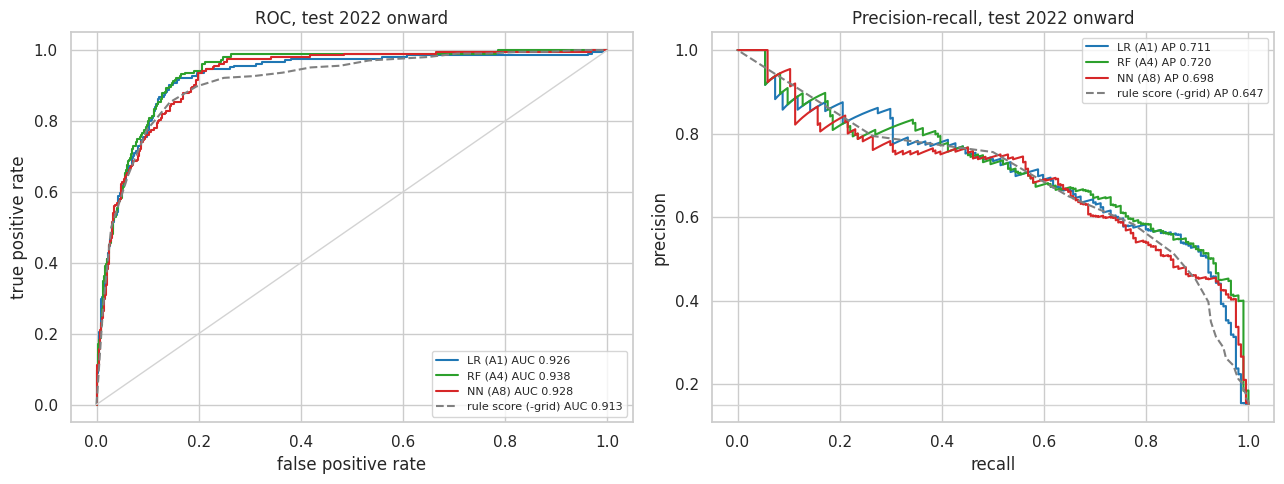

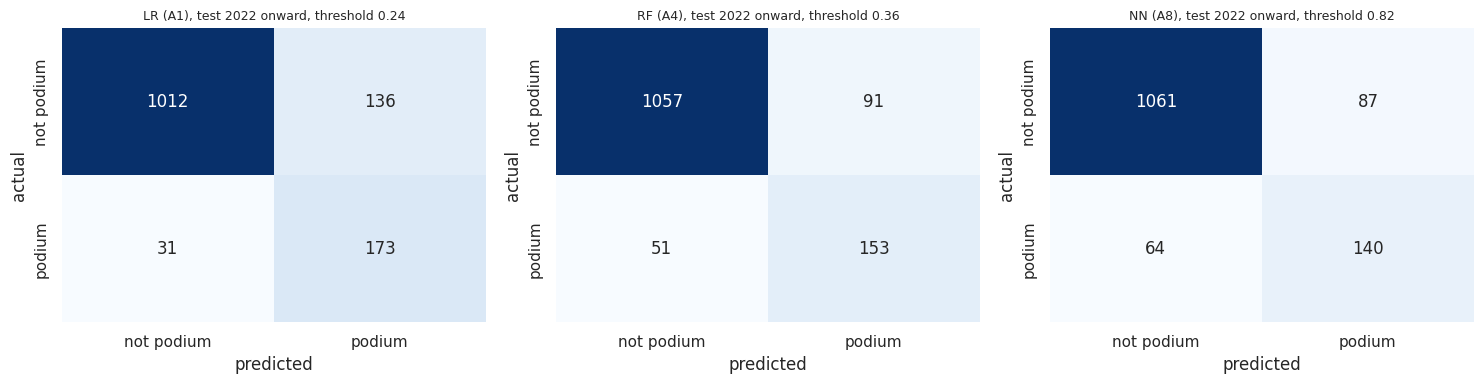

Reading the table: validation scores of the NN are slightly optimistic because early stopping used the validation seasons, and every threshold was tuned on validation, so test F1 can differ from validation F1 in either direction without anything being wrong. The test seasons (2022 onward) also follow the newest regulations, which the training data never saw.


In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for fam, k in BEST.items():
    p = test_pred[k]
    fpr, tpr, _ = roc_curve(yte, p); axes[0].plot(fpr, tpr, color=cols[fam], label=f"{fam} ({k}) AUC {roc_auc_score(yte, p):.3f}")
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, color=cols[fam], label=f"{fam} ({k}) AP {average_precision_score(yte, p):.3f}")
sc = -TE["grid_clean"].to_numpy(float)
fpr, tpr, _ = roc_curve(yte, sc); axes[0].plot(fpr, tpr, color="grey", ls="--", label=f"rule score (-grid) AUC {roc_auc_score(yte, sc):.3f}")
pr, rc, _ = precision_recall_curve(yte, sc); axes[1].plot(rc, pr, color="grey", ls="--", label=f"rule score (-grid) AP {average_precision_score(yte, sc):.3f}")
axes[0].plot([0, 1], [0, 1], color="lightgrey", lw=1); axes[1].axhline(yte.mean(), color="lightgrey", lw=1)
axes[0].set_title("ROC, test 2022 onward"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].legend(fontsize=8)
axes[1].set_title("Precision-recall, test 2022 onward"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(fontsize=8)
save_show(fig, "s4_curves_test")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (fam, k) in zip(axes, BEST.items()):
    cm_te = confusion_matrix(yte, (test_pred[k] >= REG[k]["thr"]).astype(int))
    sns.heatmap(cm_te, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not podium", "podium"], yticklabels=["not podium", "podium"])
    ax.set_title(f"{fam} ({k}), test 2022 onward, threshold {REG[k]['thr']:.2f}", fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
save_show(fig, "s4_confusion_test")

print("Reading the table: validation scores of the NN are slightly optimistic because early stopping used the validation seasons, "
      "and every threshold was tuned on validation, so test F1 can differ from validation F1 in either direction without anything being wrong. "
      "The test seasons (2022 onward) also follow the newest regulations, which the training data never saw.")

### Conclusion: which model, and is it worth its complexity?

**Recommended model: the random forest (A4).** On the unseen 2022-2024 seasons it has the best ROC-AUC (0.938) and the best PR-AUC (0.720) of the three families, and the best F1 (0.683, precision 0.627, recall 0.750 at the threshold chosen on validation).

**Against the baseline (logistic regression A0):** the forest is the only model that is reliably better on any metric. Its test ROC-AUC is 0.013 higher, and the 95% interval from resampled races excludes zero. Its PR-AUC gain (+0.008) is within noise. The tuned logistic regression (A1) is the same as the baseline in practice, and the neural network is not better than the baseline on either metric (PR-AUC -0.014, within noise). So the extra complexity of the forest buys a small but real improvement in ranking; the network's extra complexity buys nothing on this data. With about 6,800 training rows and a few strong, nearly linear signals (grid, qualifying, recent form), this is expected.

**Against the simple rule "podium if starting in the top 3":** every model clearly beats it on the primary metric (test PR-AUC about 0.70-0.72 against 0.65) and on ROC-AUC, so learning from more than the grid slot is worth it.

**Primary and secondary metrics.** PR-AUC is primary because podiums are only about 15% of rows: it rewards putting the actual podium finishers at the top of the ranking, which is what the predictor is for. ROC-AUC is secondary because it measures overall separation but looks good even when the rare class is ranked only moderately well. F1, with its precision and recall, describes what a user acting on the yes/no call at the chosen threshold would see.

**Validation to test.** All models lose some PR-AUC from validation to test (for example RF 0.744 to 0.720). The test seasons follow the 2022 ground-effect rules, which no training season covered, so a small drop is expected and does not indicate leakage or overfitting to validation.

The numbers in this paragraph are from the tables above. If a rerun changes them slightly, the tables are the reference.

## 4.14 Export the Section 4 report

Writes `section4_results.pdf` with only the Section 4 output and figures.

In [71]:
export_report("/kaggle/working/section4_results.pdf", S4_START, "s4_", "F1 Podium Prediction, Section 4 results")

Wrote /kaggle/working/section4_results.pdf: 3 text pages + 6 figure pages


# Section 5: Feature-Group Ablation

Section 3 justified each feature group before training, using exploratory evidence. This section measures what each group is actually worth after training: remove one group, retrain from scratch, and see how much the validation score drops.

Three views, because one view can mislead when features overlap (grid and qualifying position correlate at 0.97, and driver and team standings track each other):

| View | Question | Reading |
|---|---|---|
| Drop one group | How much worse is the model without this group? | A small drop can mean the group is useless, or that other groups cover for it |
| Only this group | How good is a model that sees nothing else? | Shows what a group can do alone |
| Build-up | Adding groups one at a time in a fixed order (grid, qualifying, driver form, team form, standings, circuit, era), what does each addition contribute? | Shows the incremental value, in the order a modeller would add them |

Setup:
- Each configuration refits the imputer and scaler on training rows (2003-2019) and retrains the model with the hyperparameters selected in Section 4 (LR: C from A1; RF: depth and leaf size from A4; NN: the A8 architecture).
- Scores are on the validation seasons (2020-2021) only. The test set is not used here.
- RF and NN are averaged over three random seeds per configuration (probabilities averaged), so a drop is not just seed luck.
- The reported change is the ablated score minus the full-model score, so a negative number means the group helped. Intervals come from resampling whole races.
- The NN is run for the drop-one view only, to keep the run time reasonable.

In [72]:
S5_START = len(TEE.buf)   # the Section 5 report starts here
GROUPS = list(FEATURE_GROUPS)
SEEDS = (11, 22, 33)

def fit_predict(kind, feats, seeds=SEEDS):
    pre = make_pre().fit(TR[feats])
    A, B = pre.transform(TR[feats]), pre.transform(VA[feats])
    if kind == "LR":
        return LogisticRegression(C=C_BEST, max_iter=3000).fit(A, ytr).predict_proba(B)[:, 1]
    ps = []
    for s in seeds:
        if kind == "RF":
            m = RandomForestClassifier(n_estimators=300, max_depth=RF_DEPTH, min_samples_leaf=RF_LEAF, max_features="sqrt",
                                       random_state=s, n_jobs=-1).fit(A, ytr)
            ps.append(m.predict_proba(B)[:, 1])
        else:
            m = build_nn(A.shape[1], (32, 16), dropout=0.3, l2=1e-4, seed=s)
            m.fit(A, ytr, validation_data=(B, yva), epochs=200, batch_size=128, verbose=0,
                  class_weight={0: 1.0, 1: w_pos},
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
            ps.append(m.predict(B, verbose=0).ravel())
    return np.mean(ps, axis=0)

def feats_of(groups):
    return [c for g in groups for c in FEATURE_GROUPS[g]]

P = {}   # (kind, view, label) -> validation probabilities
for kind in ["LR", "RF", "NN"]:
    P[(kind, "full", "all")] = fit_predict(kind, FEATS)
    for g in GROUPS:
        P[(kind, "drop", g)] = fit_predict(kind, feats_of([x for x in GROUPS if x != g]))
    if kind != "NN":
        for g in GROUPS:
            P[(kind, "only", g)] = fit_predict(kind, feats_of([g]))
        for i in range(1, len(GROUPS) + 1):
            P[(kind, "build", "+".join(GROUPS[:i]))] = fit_predict(kind, feats_of(GROUPS[:i]))
    f = P[(kind, "full", "all")]
    print(f"{kind}: full model, validation ROC-AUC {roc_auc_score(yva, f):.4f}, PR-AUC {average_precision_score(yva, f):.4f}")

LR: full model, validation ROC-AUC 0.9359, PR-AUC 0.7420
RF: full model, validation ROC-AUC 0.9346, PR-AUC 0.7418
NN: full model, validation ROC-AUC 0.9303, PR-AUC 0.7366


## 5.1 Drop one group

For each model, every group is removed in turn. The table lists the change in validation ROC-AUC and PR-AUC against the full model with a 95% interval from resampled races. "Reliable" means the interval excludes zero.

In [73]:
def delta_row(kind, view, label, ref_key):
    p_ref, p_new = P[ref_key], P[(kind, view, label)]
    out = {"model": kind, "view": view, "group": label,
           "n_features": None}
    for fn, nm in [(average_precision_score, "pr_auc"), (roc_auc_score, "roc_auc")]:
        out[nm] = fn(yva, p_new)
        out["d_" + nm] = fn(yva, p_new) - fn(yva, p_ref)
        lo, hi = ci_diff(yva, p_ref, p_new, BOOT_VA, fn)
        out["lo_" + nm], out["hi_" + nm] = lo, hi
    out["reliable"] = "yes" if (out["lo_pr_auc"] > 0 or out["hi_pr_auc"] < 0) else "no"
    return out

drop_rows = []
for kind in ["LR", "RF", "NN"]:
    for g in GROUPS:
        r = delta_row(kind, "drop", g, (kind, "full", "all"))
        r["n_features"] = len(FEATURE_GROUPS[g])
        drop_rows.append(r)
drop_df = pd.DataFrame(drop_rows)
view = drop_df[["model", "group", "n_features", "pr_auc", "d_pr_auc", "lo_pr_auc", "hi_pr_auc", "roc_auc", "d_roc_auc", "reliable"]]
display(view.round(4))

,model,group,n_features,pr_auc,d_pr_auc,lo_pr_auc,hi_pr_auc,roc_auc,d_roc_auc,reliable
0,LR,grid,2,0.7409,-0.0010,-0.0032,0.0002,0.9355,-0.0005,no
1,LR,qualifying,8,0.7181,-0.0238,-0.0463,-0.0009,0.9270,-0.0089,yes
2,LR,driver_form,4,0.7407,-0.0012,-0.0165,0.0163,0.9355,-0.0004,no
3,LR,constructor_form,4,0.7381,-0.0039,-0.0138,0.0052,0.9352,-0.0008,no
4,LR,standings,6,0.7367,-0.0053,-0.0248,0.0143,0.9361,0.0002,no
5,LR,circuit,2,0.7530,0.0110,0.0018,0.0208,0.9362,0.0002,yes
6,LR,era,2,0.7417,-0.0002,-0.0029,0.0013,0.9361,0.0002,no
7,RF,grid,2,0.7189,-0.0229,-0.0646,0.0041,0.9308,-0.0038,no
8,RF,qualifying,8,0.7271,-0.0147,-0.0323,0.0080,0.9288,-0.0059,no
9,RF,driver_form,4,0.7341,-0.0077,-0.0200,0.0021,0.9337,-0.0009,no


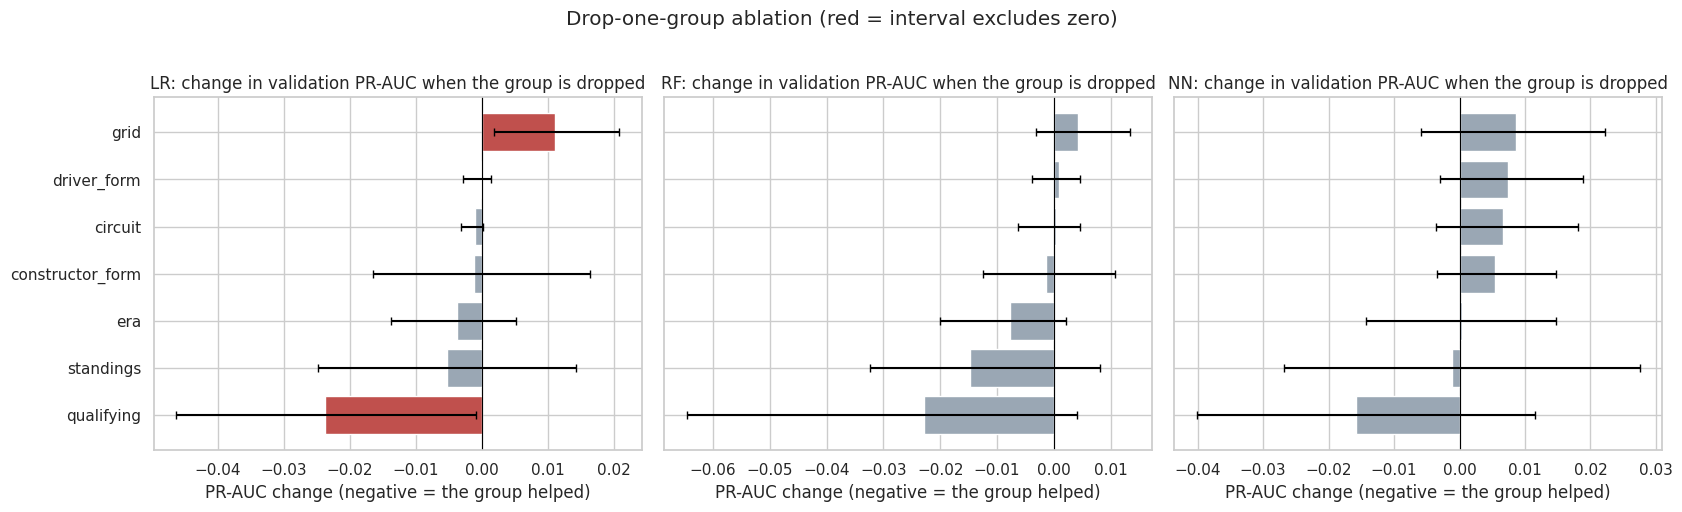

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, kind in zip(axes, ["LR", "RF", "NN"]):
    d = drop_df[drop_df["model"] == kind].sort_values("d_pr_auc")
    y = np.arange(len(d))
    ax.barh(y, d["d_pr_auc"], color=["#c0504d" if r == "yes" else "#9aa7b4" for r in d["reliable"]])
    ax.errorbar(d["d_pr_auc"], y, xerr=[d["d_pr_auc"] - d["lo_pr_auc"], d["hi_pr_auc"] - d["d_pr_auc"]], fmt="none", color="black", capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels(d["group"]); ax.set_title(f"{kind}: change in validation PR-AUC when the group is dropped")
    ax.set_xlabel("PR-AUC change (negative = the group helped)")
fig.suptitle("Drop-one-group ablation (red = interval excludes zero)", y=1.02)
save_show(fig, "s5_drop_one")

## 5.2 Only one group

A model that sees a single group. This is the generous view for each group, since it does not have to share credit with groups that carry the same information.

,model,group,n_features,roc_auc,pr_auc,d_pr_auc,lo_pr_auc,hi_pr_auc
0,LR,grid,2,0.9103,0.6478,-0.0941,-0.1455,-0.0469
1,LR,qualifying,8,0.9258,0.7180,-0.0239,-0.0727,0.0180
2,LR,driver_form,4,0.8909,0.6484,-0.0935,-0.1448,-0.0365
3,LR,constructor_form,4,0.8862,0.5602,-0.1818,-0.2322,-0.1147
4,LR,standings,6,0.8835,0.6546,-0.0873,-0.1473,-0.0356
5,LR,circuit,2,0.7055,0.3982,-0.3438,-0.4658,-0.2221
6,LR,era,2,0.5000,0.1510,-0.5910,-0.6997,-0.4835
7,RF,grid,2,0.9137,0.6490,-0.0928,-0.1437,-0.0379
8,RF,qualifying,8,0.9245,0.7085,-0.0333,-0.0813,0.0112
9,RF,driver_form,4,0.8851,0.6499,-0.0920,-0.1373,-0.0388


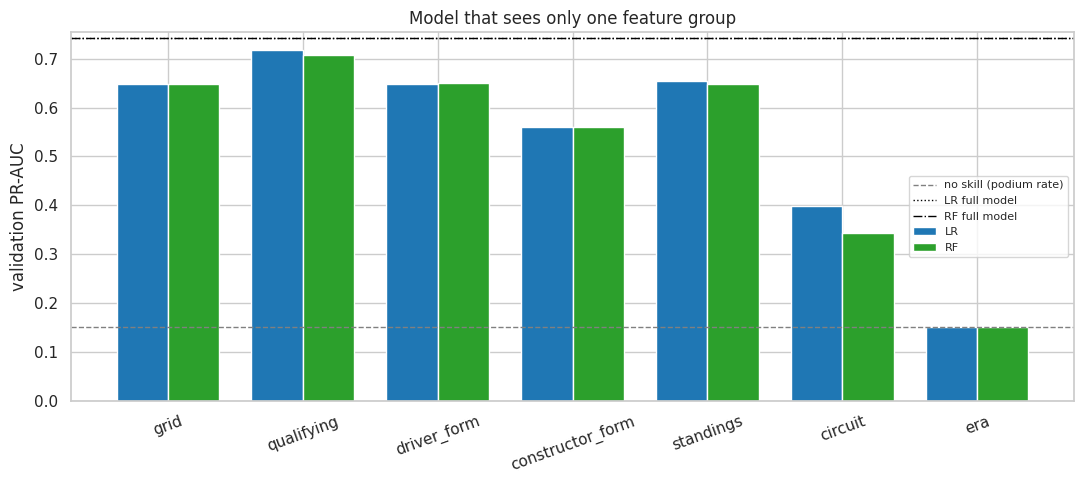

In [75]:
only_rows = []
ref_full = {k: P[(k, "full", "all")] for k in ["LR", "RF"]}
for kind in ["LR", "RF"]:
    for g in GROUPS:
        r = delta_row(kind, "only", g, (kind, "full", "all"))
        r["n_features"] = len(FEATURE_GROUPS[g])
        only_rows.append(r)
only_df = pd.DataFrame(only_rows)
display(only_df[["model", "group", "n_features", "roc_auc", "pr_auc", "d_pr_auc", "lo_pr_auc", "hi_pr_auc"]].round(4))

fig, ax = plt.subplots(figsize=(11, 5))
w = 0.38
xs = np.arange(len(GROUPS))
for j, (kind, col) in enumerate([("LR", "#1f77b4"), ("RF", "#2ca02c")]):
    d = only_df[only_df["model"] == kind].set_index("group").loc[GROUPS]
    ax.bar(xs + (j - 0.5) * w, d["pr_auc"], w, label=kind, color=col)
ax.axhline(yva.mean(), color="grey", ls="--", lw=1, label="no skill (podium rate)")
for kind, ls in [("LR", ":"), ("RF", "-.")]:
    ax.axhline(average_precision_score(yva, P[(kind, "full", "all")]), color="black", ls=ls, lw=1, label=f"{kind} full model")
ax.set_xticks(xs); ax.set_xticklabels(GROUPS, rotation=20); ax.set_ylabel("validation PR-AUC")
ax.set_title("Model that sees only one feature group"); ax.legend(fontsize=8)
save_show(fig, "s5_only_one")

## 5.3 Build-up

Groups are added in a fixed, sensible order: grid first, then qualifying, driver form, team form, standings, circuit history and era. Each line shows the validation PR-AUC after the addition, so the step size is the incremental value of that group given everything before it. The order matters when groups overlap, which is why this is a complement to the drop-one view and not a replacement.

,model,step,added,pr_auc,roc_auc,step_gain_pr,lo,hi,reliable
0,LR,1,grid,0.6478,0.9103,NaN,NaN,NaN,NaN
1,LR,2,qualifying,0.7116,0.9266,0.0638,0.0335,0.0904,yes
2,LR,3,driver_form,0.7446,0.9345,0.0330,-0.0055,0.0748,no
3,LR,4,constructor_form,0.7443,0.9357,-0.0002,-0.0129,0.0126,no
4,LR,5,standings,0.7528,0.9361,0.0085,-0.0083,0.0235,no
5,LR,6,circuit,0.7417,0.9361,-0.0111,-0.0204,-0.0023,yes
6,LR,7,era,0.7420,0.9359,0.0002,-0.0013,0.0029,no
7,RF,1,grid,0.6490,0.9137,NaN,NaN,NaN,NaN
8,RF,2,qualifying,0.7196,0.9278,0.0706,0.0321,0.1013,yes
9,RF,3,driver_form,0.7500,0.9353,0.0304,0.0037,0.0592,yes


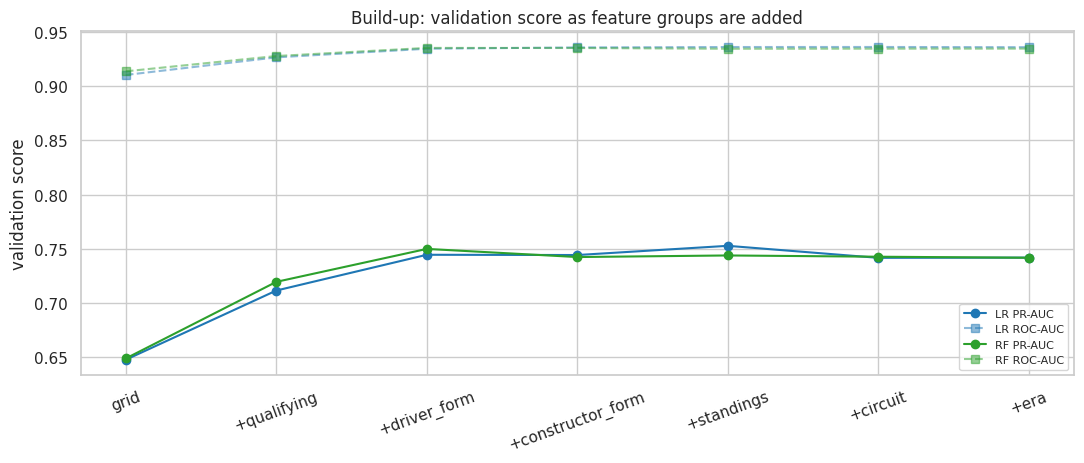

In [76]:
build_rows = []
for kind in ["LR", "RF"]:
    prev = None
    for i in range(1, len(GROUPS) + 1):
        key = (kind, "build", "+".join(GROUPS[:i]))
        p = P[key]
        row = {"model": kind, "step": i, "added": GROUPS[i - 1], "pr_auc": average_precision_score(yva, p),
               "roc_auc": roc_auc_score(yva, p)}
        if prev is not None:
            lo, hi = ci_diff(yva, prev, p, BOOT_VA, average_precision_score)
            row.update({"step_gain_pr": row["pr_auc"] - average_precision_score(yva, prev), "lo": lo, "hi": hi,
                        "reliable": "yes" if (lo > 0 or hi < 0) else "no"})
        build_rows.append(row)
        prev = p
build_df = pd.DataFrame(build_rows)
display(build_df.round(4))

fig, ax = plt.subplots(figsize=(11, 4.8))
for kind, col in [("LR", "#1f77b4"), ("RF", "#2ca02c")]:
    d = build_df[build_df["model"] == kind]
    ax.plot(d["step"], d["pr_auc"], marker="o", color=col, label=f"{kind} PR-AUC")
    ax.plot(d["step"], d["roc_auc"], marker="s", ls="--", color=col, alpha=0.5, label=f"{kind} ROC-AUC")
ax.set_xticks(range(1, len(GROUPS) + 1)); ax.set_xticklabels(["+" + g if i else g for i, g in enumerate(GROUPS)], rotation=20)
ax.set_ylabel("validation score"); ax.set_title("Build-up: validation score as feature groups are added"); ax.legend(fontsize=8)
save_show(fig, "s5_build_up")

## 5.4 What the ablation shows

Computed from the tables above. Where a model loses little without a group, either the group carries little information or another group carries the same information; the "only this group" and build-up views separate the two cases.

In [77]:
print("ABLATION SUMMARY (validation PR-AUC; negative change = removing the group hurts)\n")
for kind in ["LR", "RF", "NN"]:
    d = drop_df[drop_df["model"] == kind].sort_values("d_pr_auc")
    full = average_precision_score(yva, P[(kind, "full", "all")])
    print(f"{kind} (full model PR-AUC {full:.4f}):")
    print("  largest drops when removed: " + "; ".join(f"{r.group} {r.d_pr_auc:+.4f}" + (" (reliable)" if r.reliable == "yes" else "") for r in d.head(3).itertuples()))
    ok = d[d["reliable"] == "yes"]
    print("  groups whose removal reliably changes PR-AUC: " + (", ".join(f"{r.group} ({r.d_pr_auc:+.4f})" for r in ok.itertuples()) or "none"))
    flat = d[(d["reliable"] == "no")]
    print("  no reliable change when removed: " + ", ".join(flat["group"]))
for kind in ["LR", "RF"]:
    d = only_df[only_df["model"] == kind].sort_values("pr_auc", ascending=False)
    print(f"{kind} best single groups on their own: " + "; ".join(f"{r.group} PR-AUC {r.pr_auc:.3f}" for r in d.head(3).itertuples()) +
          f" (no-skill level {yva.mean():.3f})")
for kind in ["LR", "RF"]:
    d = build_df[build_df["model"] == kind]
    big = d[d["step"] > 1].sort_values("step_gain_pr", ascending=False).head(2)
    first = d.iloc[0]
    print(f"{kind} build-up: grid alone {first['pr_auc']:.4f}; biggest additions " +
          "; ".join(f"+{r.added} {r.step_gain_pr:+.4f}" + (" (reliable)" if r.reliable == "yes" else "") for r in big.itertuples()) +
          f"; final {d.iloc[-1]['pr_auc']:.4f}")
print("\nCaution: groups overlap (grid vs qualifying 0.97, driver vs team standings above 0.9), so a small drop does not prove a group is worthless, "
      "and the intervals are wide because validation has only about 40 races. Treat the ordering as indicative, not exact.")

ABLATION SUMMARY (validation PR-AUC; negative change = removing the group hurts)

LR (full model PR-AUC 0.7420):
  largest drops when removed: qualifying -0.0238 (reliable); standings -0.0053; constructor_form -0.0039
  groups whose removal reliably changes PR-AUC: qualifying (-0.0238), circuit (+0.0110)
  no reliable change when removed: standings, constructor_form, driver_form, grid, era
RF (full model PR-AUC 0.7418):
  largest drops when removed: grid -0.0229; qualifying -0.0147; driver_form -0.0077
  groups whose removal reliably changes PR-AUC: none
  no reliable change when removed: grid, qualifying, driver_form, standings, circuit, era, constructor_form
NN (full model PR-AUC 0.7366):
  largest drops when removed: qualifying -0.0158; standings -0.0012; era +0.0003
  groups whose removal reliably changes PR-AUC: none
  no reliable change when removed: qualifying, standings, era, constructor_form, circuit, driver_form, grid
LR best single groups on their own: qualifying PR-AUC 0.71

### Two groups that need a comment: era and circuit

**Era.** The two era flags mark 2003-2008 and 2009-2013, with 2014 onward as the baseline. Every validation and test row is from 2014 or later, so both flags are always 0 there. Their permutation importance in Section 6 is therefore exactly zero by construction, and removing them cannot change a validation score much: these results say nothing about whether the flags are useful. They only affect how the models fit the training seasons. The 2022 ground-effect rules also have no flag of their own, because no training season follows them.

**Circuit.** Removing the circuit group reliably improves the logistic regression (+0.011 validation PR-AUC), but not the forest or the network, where the change is within noise. The selected models were fixed in Section 4 before this ablation ran and before the test set was scored, so they keep the group; changing the feature set now would mean choosing a model after seeing test results. A model without the circuit group is the natural next step and is listed as a limitation.

## 5.5 Export the Section 5 report

In [78]:
export_report("/kaggle/working/section5_results.pdf", S5_START, "s5_", "F1 Podium Prediction, Section 5 results")

Wrote /kaggle/working/section5_results.pdf: 2 text pages + 3 figure pages


# Section 6: Model Explainability

Question: **what is each selected model relying on when it predicts a podium?**

| Step | Method | Scope |
|---|---|---|
| 6.1 | Permutation importance, per feature | Global |
| 6.2 | Permutation importance, per feature group | Global |
| 6.3 | SHAP: importance bars, beeswarm plots, dependence plots, direction of effects | Global |
| 6.4 | SHAP waterfall and LIME for single predictions | Local |
| 6.5 | Sanity checks and a plain summary | |

All explanations use the three models selected in Section 4 (LR, RF and NN), the validation seasons (2020-2021), and the Section 4 preprocessing. The test set is not used.

**These explanations are not causal.** A feature being important to a model means the model relies on it to make predictions. It does not show that the feature causes podium finishes. For example, a driver's recent podium rate and the team's strength are entangled with the car they drive, and a grid slot is itself a result of qualifying pace. Importance describes the model and its data, not the sport.

How the methods differ, in one line each:
- Permutation importance shuffles one feature (or group) among the validation rows and measures how much the PR-AUC falls. A big fall means the model leans on it.
- SHAP splits each individual prediction into a contribution per feature, so the contributions add up to the prediction. Averaging their absolute sizes gives a global ranking, and their sign shows the direction.
- LIME fits a small, simple model around one prediction by nudging the inputs, and reports which features that local model uses.

In [79]:
import subprocess, importlib
S6_START = len(TEE.buf)   # the Section 6 report starts here

def ensure(pkg, mod=None):
    try:
        importlib.import_module(mod or pkg); return True
    except ImportError:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True, capture_output=True, timeout=400)
            importlib.import_module(mod or pkg); return True
        except Exception as e:
            print(f"could not install {pkg}: {str(e)[:120]}"); return False

HAS_SHAP = ensure("shap")
HAS_LIME = ensure("lime")
assert HAS_SHAP, "shap is required for this section (it is preinstalled on Kaggle)"
import shap
print("shap", shap.__version__, "| lime available:", HAS_LIME)

N_BASE = len(FEATS)
BASE_OF = [n.replace("missingindicator_", "") for n in PRE_NAMES]            # raw feature behind every model column
GROUP_FOR = {c: GROUP_OF[c] for c in FEATS}
MODELS = {"LR": FINAL["LR"], "RF": FINAL["RF"], "NN": FINAL["NN"]}
COL = {"LR": "#1f77b4", "RF": "#2ca02c", "NN": "#d62728"}
GCOL = dict(zip(FEATURE_GROUPS, sns.color_palette("tab10", len(FEATURE_GROUPS))))

IMP_VA = PRE.named_steps["imp"].transform(VA[FEATS])                          # imputed raw values + missing flags
DISP_VA = np.hstack([VA[FEATS].to_numpy(float), IMP_VA[:, N_BASE:]])           # values to show on plots (NaN stays NaN)
P_VA = {k: predict_any(m, Xva) for k, m in MODELS.items()}
for k in MODELS:
    print(f"{k}: validation PR-AUC {average_precision_score(yva, P_VA[k]):.4f} (explained model: attempt {BEST[k]})")

shap 0.52.0 | lime available: True
LR: validation PR-AUC 0.7420 (explained model: attempt A1)
RF: validation PR-AUC 0.7439 (explained model: attempt A4)
NN: validation PR-AUC 0.7420 (explained model: attempt A8)


## 6.1 Permutation importance per feature

Each of the 28 features is shuffled among the validation rows 10 times; the importance is the average fall in validation PR-AUC (the primary metric from Section 4). A bar near zero means shuffling the feature did not hurt. Whiskers are the standard deviation over the 10 shuffles. Missing-value flags are shuffled together with their feature (the flag belongs to the raw feature).

,group,LR,RF,NN
unit,,,,
grid_clean,grid,0.1009,0.0505,0.0676
qual_pos,qualifying,0.1099,0.0350,0.0784
q3_gap_pct,qualifying,0.0067,0.0204,0.0196
q2_gap_pct,qualifying,0.0142,0.0168,0.0181
drv_points_share_before,standings,-0.0012,0.0096,-0.0020
drv_podium_rate_20,driver_form,0.0398,0.0092,0.0375
drv_standing_pos_before,standings,0.0218,0.0064,0.0065
drv_podium_rate_5,driver_form,0.0159,0.0062,0.0189
drv_avg_finish_5,driver_form,-0.0013,0.0049,0.0038


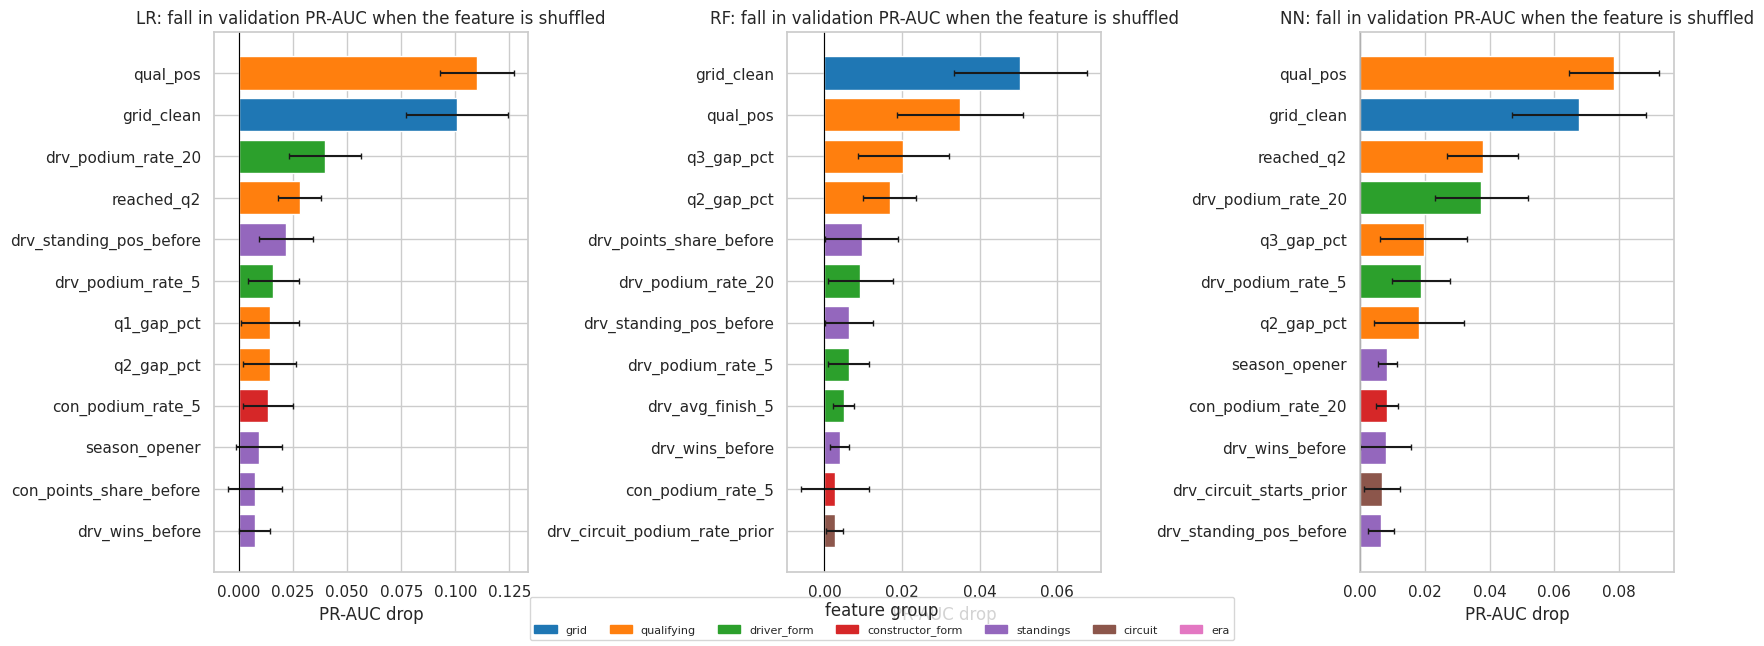

In [80]:
def perm_importance(kind, units, repeats=10, seed=SEED):
    rng = np.random.default_rng(seed)
    model = MODELS[kind]
    base = average_precision_score(yva, predict_any(model, Xva))
    rows = []
    for name, cols in units.items():
        drops = []
        for _ in range(repeats):
            d = VA[FEATS].copy()
            d[cols] = d[cols].to_numpy()[rng.permutation(len(d))]
            drops.append(base - average_precision_score(yva, predict_any(model, PRE.transform(d))))
        rows.append({"unit": name, "mean_drop": np.mean(drops), "sd": np.std(drops)})
    return pd.DataFrame(rows).set_index("unit")

PI_F = {k: perm_importance(k, {f: [f] for f in FEATS}) for k in MODELS}
tbl = pd.concat({k: v["mean_drop"] for k, v in PI_F.items()}, axis=1)
tbl.insert(0, "group", [GROUP_FOR[f] for f in tbl.index])
display(tbl.sort_values("RF", ascending=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
for ax, k in zip(axes, MODELS):
    d = PI_F[k].sort_values("mean_drop", ascending=False).head(12).iloc[::-1]
    ax.barh(d.index, d["mean_drop"], xerr=d["sd"], color=[GCOL[GROUP_FOR[f]] for f in d.index], capsize=2)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{k}: fall in validation PR-AUC when the feature is shuffled")
    ax.set_xlabel("PR-AUC drop")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GCOL.values()]
fig.legend(handles, list(GCOL), loc="lower center", ncol=7, fontsize=8, title="feature group")
save_show(fig, "s6_perm_importance_features")

## 6.2 Permutation importance per feature group

Whole groups are shuffled together (rows are permuted jointly, so a group keeps its internal structure). This answers the question the ablation asked, but without retraining: it shows what the already-trained model depends on. A group that scores high here but did not matter in the ablation is one the model uses but that other groups could replace.

,LR,RF,NN,ablation_LR,ablation_NN,ablation_RF
unit,,,,,,
qualifying,0.0930,0.0743,0.1130,-0.0238,-0.0158,-0.0147
grid,0.1123,0.0505,0.0776,-0.0010,0.0086,-0.0229
driver_form,0.0964,0.0361,0.0915,-0.0012,0.0074,-0.0077
standings,0.0438,0.0277,0.0217,-0.0053,-0.0012,-0.0015
constructor_form,0.0061,0.0061,0.0112,-0.0039,0.0055,0.0042
circuit,-0.0113,0.0020,-0.0060,0.0110,0.0067,0.0004
era,0.0000,0.0000,0.0000,-0.0002,0.0003,0.0010


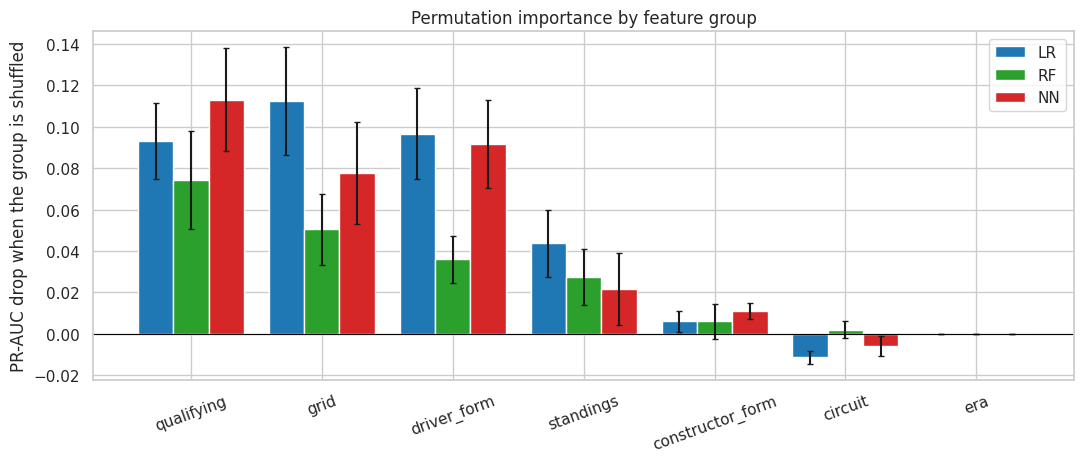

In [81]:
PI_G = {k: perm_importance(k, {g: v for g, v in FEATURE_GROUPS.items()}) for k in MODELS}
gt = pd.concat({k: v["mean_drop"] for k, v in PI_G.items()}, axis=1)
abl = drop_df.pivot(index="group", columns="model", values="d_pr_auc").rename(columns=lambda c: f"ablation_{c}")
display(gt.join(abl).sort_values("RF", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(11, 4.8))
w, xs = 0.27, np.arange(len(FEATURE_GROUPS))
order = gt["RF"].sort_values(ascending=False).index
for j, k in enumerate(MODELS):
    ax.bar(xs + (j - 1) * w, gt.loc[order, k], w, yerr=PI_G[k].loc[order, "sd"], color=COL[k], label=k, capsize=2)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=20); ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("PR-AUC drop when the group is shuffled"); ax.set_title("Permutation importance by feature group"); ax.legend()
save_show(fig, "s6_perm_importance_groups")

## 6.3 SHAP: global view

SHAP values are computed on the validation rows (columns include the missing-value flags added by the preprocessing):
- LR: exact linear SHAP, in log-odds units.
- RF: exact tree SHAP, in probability units.
- NN: Kernel SHAP, an approximation based on sampling, in probability units, on a random sample of 150 validation rows with a 15-cluster summary of the training data as background. It is slower and noisier than the other two.

For each prediction, the SHAP values plus the base value add up to the model output. Section 6.5 checks this. Because the units differ, models are compared through each feature's share of total importance, not through raw sizes.

Background dataset has 6783 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6783 when initializing the masker.


{'LR': (775, 45), 'RF': (775, 45), 'NN': (150, 45)}
Share of total mean |SHAP| per feature (missing-value flags added to their feature):


,group,LR,RF,NN
grid_clean,grid,0.163,0.170,0.176
qual_pos,qualifying,0.163,0.124,0.222
q3_gap_pct,qualifying,0.030,0.083,0.042
drv_podium_rate_20,driver_form,0.058,0.080,0.108
drv_standing_pos_before,standings,0.068,0.068,0.011
drv_points_share_before,standings,0.032,0.061,0.001
drv_podium_rate_5,driver_form,0.037,0.056,0.045
con_points_share_before,standings,0.045,0.055,0.054
con_podium_rate_5,constructor_form,0.033,0.051,0.011
q2_gap_pct,qualifying,0.074,0.041,0.084


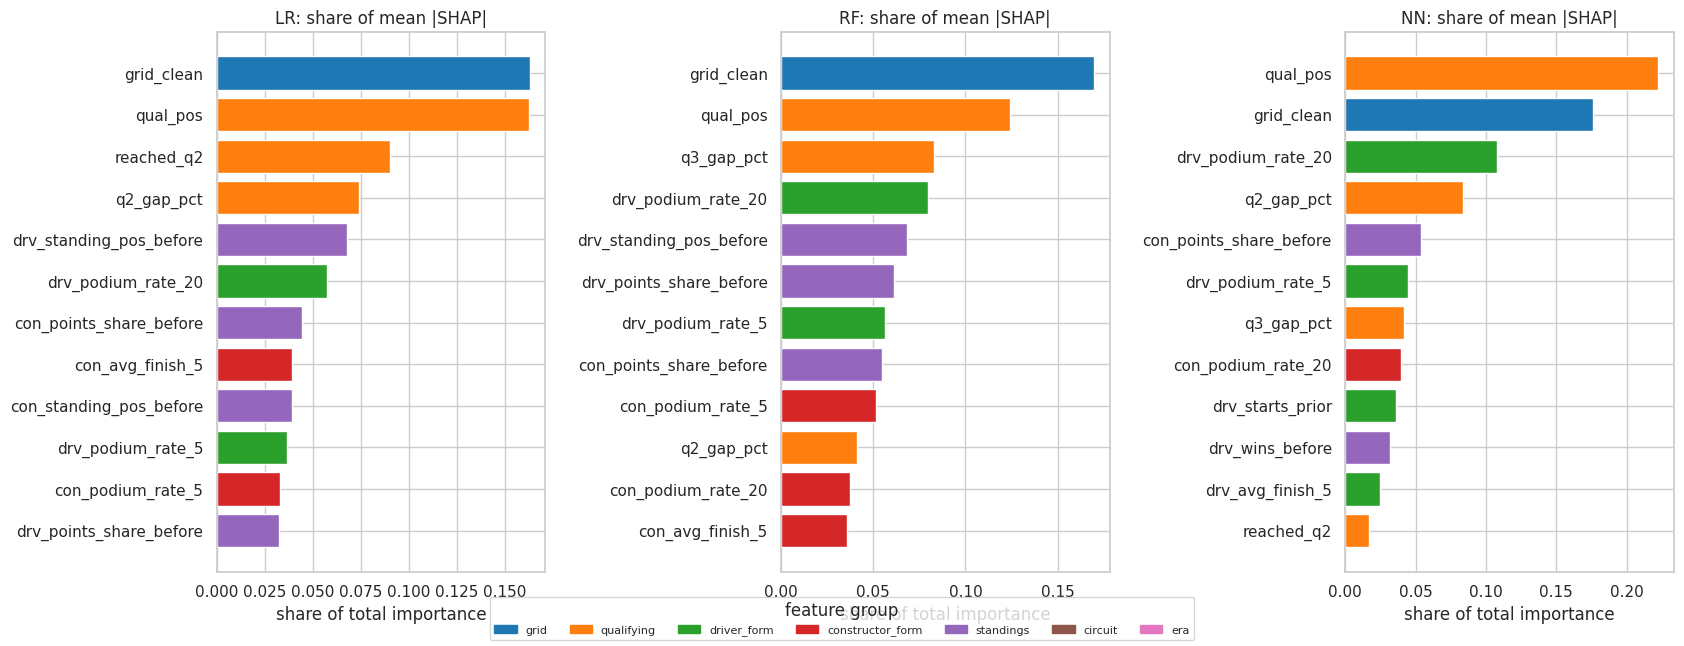

In [82]:
Xtr_bg = Xtr
ex_lr = shap.LinearExplainer(MODELS["LR"], Xtr_bg)
sv_lr = np.asarray(ex_lr.shap_values(Xva))
base_lr = float(np.ravel(ex_lr.expected_value)[0])

ex_rf = shap.TreeExplainer(MODELS["RF"])
sv_rf = ex_rf.shap_values(Xva, check_additivity=False)
if isinstance(sv_rf, list):
    sv_rf = sv_rf[1]
sv_rf = np.asarray(sv_rf)
if sv_rf.ndim == 3:
    sv_rf = sv_rf[:, :, 1]
base_rf = float(np.ravel(ex_rf.expected_value)[-1])

rng_s = np.random.default_rng(SEED)
SUB = np.sort(rng_s.choice(len(Xva), size=min(150, len(Xva)), replace=False))
f_nn = lambda Z: MODELS["NN"].predict(Z, verbose=0).ravel()
ex_nn = shap.KernelExplainer(f_nn, shap.kmeans(Xtr_bg, 15))
sv_nn = ex_nn.shap_values(Xva[SUB], nsamples=300, silent=True)
sv_nn = np.asarray(sv_nn[0] if isinstance(sv_nn, list) else sv_nn)
if sv_nn.ndim == 3:
    sv_nn = sv_nn[:, :, 0]
base_nn = float(np.ravel(ex_nn.expected_value)[0])

SV = {"LR": (sv_lr, base_lr, np.arange(len(Xva))), "RF": (sv_rf, base_rf, np.arange(len(Xva))), "NN": (sv_nn, base_nn, SUB)}
print({k: v[0].shape for k, v in SV.items()})

def shap_by_feature(values):
    s = pd.Series(np.abs(values).mean(0), index=BASE_OF).groupby(level=0).sum()
    return s.reindex(FEATS)

SI = pd.DataFrame({k: shap_by_feature(v[0]) for k, v in SV.items()})
SI_share = SI / SI.sum()
tbl = SI_share.copy()
tbl.insert(0, "group", [GROUP_FOR[f] for f in tbl.index])
print("Share of total mean |SHAP| per feature (missing-value flags added to their feature):")
display((tbl.sort_values("RF", ascending=False)).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
for ax, k in zip(axes, MODELS):
    d = SI_share[k].sort_values(ascending=False).head(12).iloc[::-1]
    ax.barh(d.index, d.values, color=[GCOL[GROUP_FOR[f]] for f in d.index])
    ax.set_title(f"{k}: share of mean |SHAP|"); ax.set_xlabel("share of total importance")
fig.legend(handles, list(GCOL), loc="lower center", ncol=7, fontsize=8, title="feature group")
save_show(fig, "s6_shap_importance_bars")

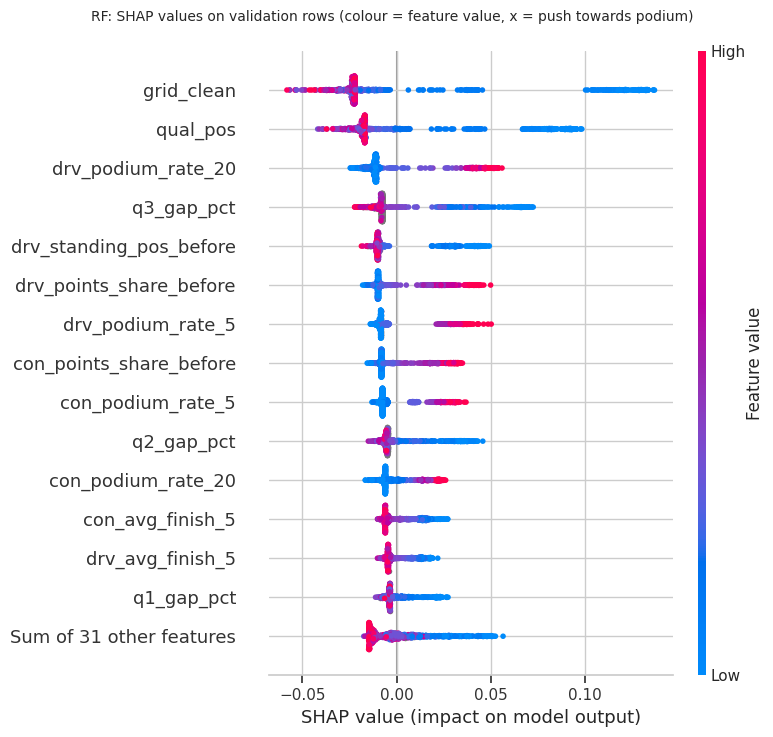

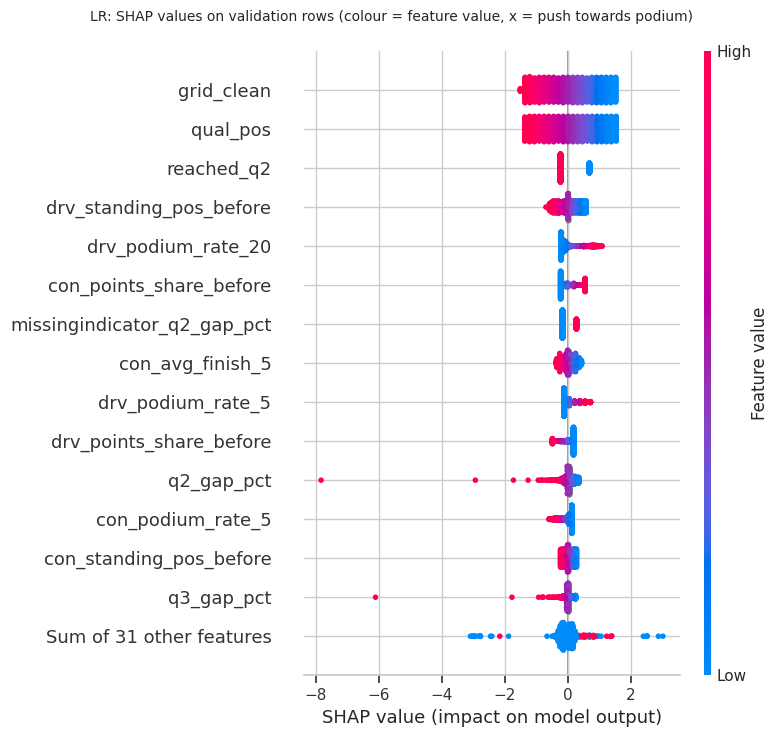

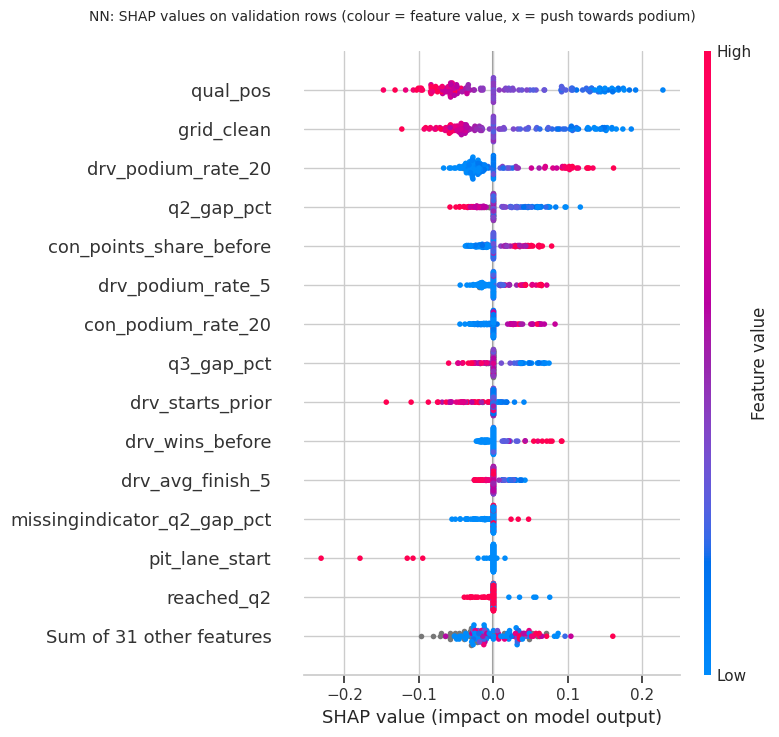

In [83]:
def beeswarm(kind, name):
    vals, base, idx = SV[kind]
    ex = shap.Explanation(values=vals, base_values=np.full(len(vals), base), data=DISP_VA[idx], feature_names=PRE_NAMES)
    plt.figure(figsize=(9, 6.5))
    shap.plots.beeswarm(ex, max_display=15, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{kind}: SHAP values on validation rows (colour = feature value, x = push towards podium)", fontsize=10)
    save_show(fig, name)

beeswarm("RF", "s6_shap_beeswarm_RF")
beeswarm("LR", "s6_shap_beeswarm_LR")
beeswarm("NN", "s6_shap_beeswarm_NN")

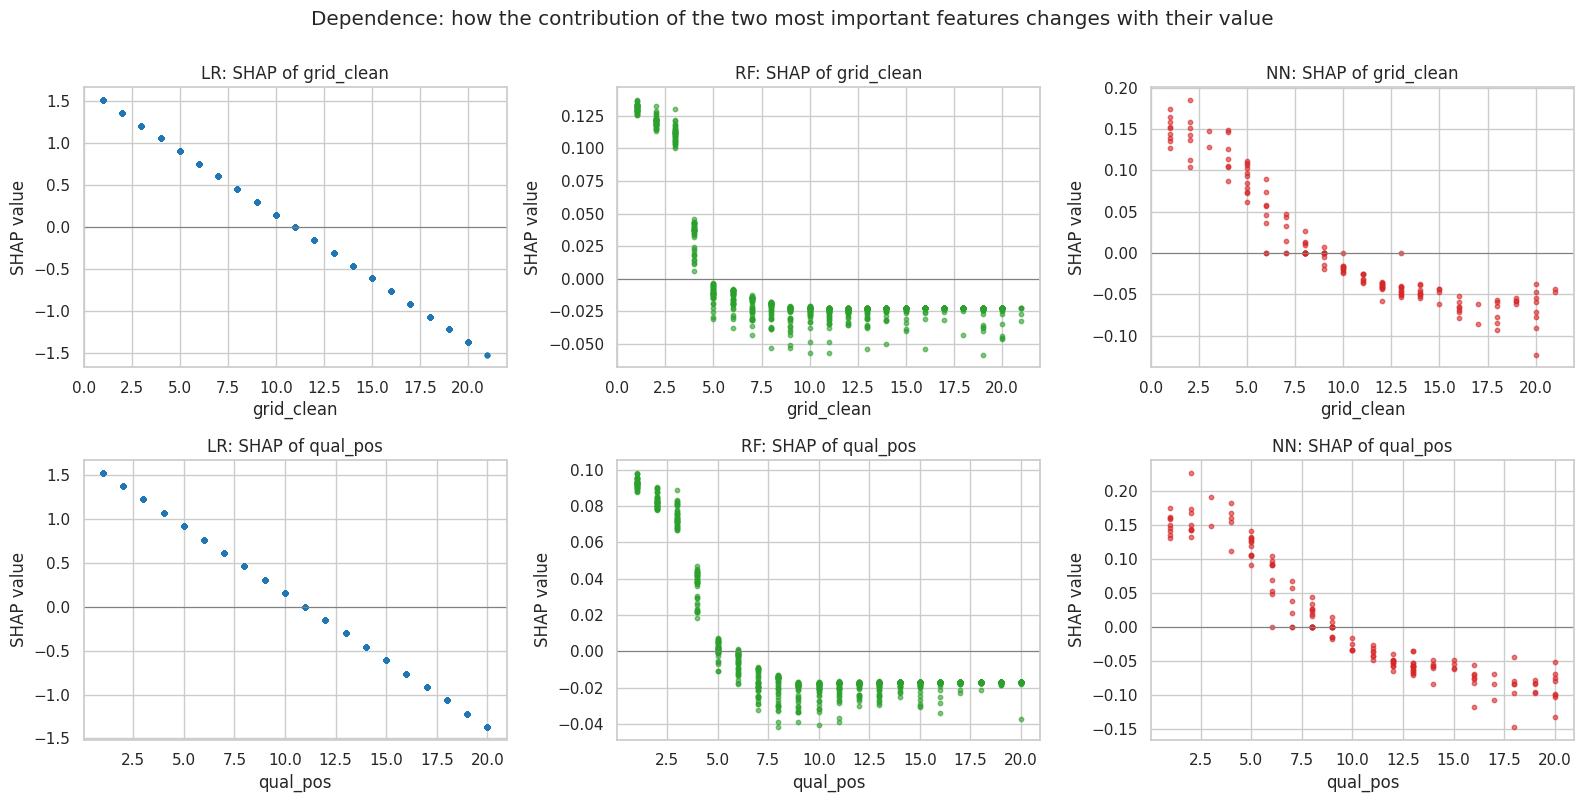

Direction of the most important features (Spearman between the feature value and its SHAP contribution):


,model,feature,share,"spearman(value, SHAP)",reading
0,LR,grid_clean,0.163,-1.000,higher value -> less likely podium
1,LR,qual_pos,0.163,-1.000,higher value -> less likely podium
2,LR,reached_q2,0.090,-1.000,higher value -> less likely podium
3,LR,q2_gap_pct,0.074,-1.000,higher value -> less likely podium
4,LR,drv_standing_pos_before,0.068,-1.000,higher value -> less likely podium
5,LR,drv_podium_rate_20,0.058,1.000,higher value -> more likely podium
6,LR,con_points_share_before,0.045,1.000,higher value -> more likely podium
7,LR,con_avg_finish_5,0.039,-1.000,higher value -> less likely podium
8,RF,grid_clean,0.170,-0.588,higher value -> less likely podium
9,RF,qual_pos,0.124,-0.528,higher value -> less likely podium


In [84]:
top2 = [f for f in SI["RF"].sort_values(ascending=False).index if f in FEATS][:2]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, f in enumerate(top2):
    j = FEATS.index(f)
    for c, k in enumerate(MODELS):
        vals, base, idx = SV[k]
        x = VA[f].to_numpy(float)[idx]
        ok = ~np.isnan(x)
        axes[r, c].scatter(x[ok], vals[ok, j], s=10, alpha=0.6, color=COL[k])
        axes[r, c].axhline(0, color="grey", lw=0.8)
        axes[r, c].set_title(f"{k}: SHAP of {f}"); axes[r, c].set_xlabel(f); axes[r, c].set_ylabel("SHAP value")
fig.suptitle("Dependence: how the contribution of the two most important features changes with their value", y=1.0)
save_show(fig, "s6_shap_dependence")

rows_ = []
for k in ["LR", "RF", "NN"]:
    vals, base, idx = SV[k]
    for f in SI[k].sort_values(ascending=False).head(8).index:
        j = FEATS.index(f)
        x = VA[f].to_numpy(float)[idx]
        ok = ~np.isnan(x)
        rho = stats.spearmanr(x[ok], vals[ok, j]).statistic if ok.sum() > 10 and np.nanstd(x[ok]) > 0 else np.nan
        rows_.append({"model": k, "feature": f, "share": SI_share.loc[f, k], "spearman(value, SHAP)": rho,
                      "reading": "higher value -> more likely podium" if rho > 0.2 else ("higher value -> less likely podium" if rho < -0.2 else "no clear monotone direction")})
dir_tbl = pd.DataFrame(rows_)
print("Direction of the most important features (Spearman between the feature value and its SHAP contribution):")
display(dir_tbl.round(3))

## 6.4 Local explanations: single predictions

The selected Random Forest (the attempt chosen in Section 4) is used as the explained model because it is the best trade-off between flexibility and exact explanations. Three validation rows are chosen by rule, not by hand:
- a confident correct case: the actual podium finisher the model gave the highest probability,
- a miss: the actual podium finisher the model gave the lowest probability,
- a false alarm: the non-podium driver the model gave the highest probability.

For each, a SHAP waterfall shows how the prediction moves from the base value (the average prediction) to the final probability, one feature at a time. LIME is shown for the first two cases.

In [85]:
DRV = T["drivers"].set_index("driverId"); RAC = T["races"].set_index("raceId")
p_rf = P_VA["RF"]
cases = {
    "confident correct (actual podium)": int(np.where(yva == 1)[0][np.argmax(p_rf[yva == 1])]),
    "miss (actual podium, low probability)": int(np.where(yva == 1)[0][np.argmin(p_rf[yva == 1])]),
    "false alarm (not a podium)": int(np.where(yva == 0)[0][np.argmax(p_rf[yva == 0])]),
}
KEYF = ["grid_clean", "qual_pos", "q1_gap_pct", "drv_podium_rate_20", "con_podium_rate_20", "drv_points_share_before"]
for lab, i in cases.items():
    r = VA.iloc[i]
    who = f"{DRV.loc[r.driverId, 'forename']} {DRV.loc[r.driverId, 'surname']}"
    race = f"{int(RAC.loc[r.raceId, 'year'])} {RAC.loc[r.raceId, 'name']}"
    print(f"\n{lab}: {who}, {race}\n  finished position {int(r.positionOrder)} | RF probability {p_rf[i]:.3f} (threshold {THR['RF']:.2f}) | "
          f"LR {P_VA['LR'][i]:.3f} | NN {P_VA['NN'][i]:.3f}")
    print("  " + ", ".join(f"{f}={r[f]:.2f}" if pd.notna(r[f]) else f"{f}=missing" for f in KEYF))


confident correct (actual podium): Lewis Hamilton, 2020 Belgian Grand Prix
  finished position 1 | RF probability 0.855 (threshold 0.36) | LR 0.881 | NN 0.977
  grid_clean=1.00, qual_pos=1.00, q1_gap_pct=0.00, drv_podium_rate_20=0.75, con_podium_rate_20=0.72, drv_points_share_before=1.00

miss (actual podium, low probability): Esteban Ocon, 2021 Hungarian Grand Prix
  finished position 1 | RF probability 0.021 (threshold 0.36) | LR 0.028 | NN 0.068
  grid_clean=8.00, qual_pos=8.00, q1_gap_pct=1.51, drv_podium_rate_20=0.05, con_podium_rate_20=0.07, drv_points_share_before=0.08

false alarm (not a podium): Lewis Hamilton, 2020 Italian Grand Prix
  finished position 7 | RF probability 0.850 (threshold 0.36) | LR 0.882 | NN 0.977
  grid_clean=1.00, qual_pos=1.00, q1_gap_pct=0.00, drv_podium_rate_20=0.75, con_podium_rate_20=0.72, drv_points_share_before=1.00


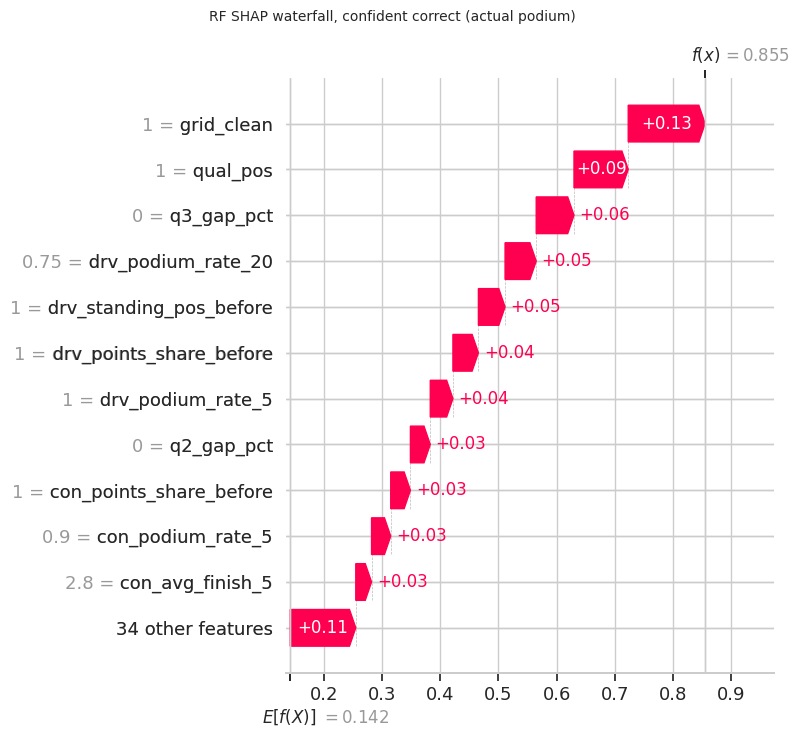

confident correct (actual podium): base 0.142 + contributions = 0.855 (model output 0.855)
  largest contributions: grid_clean +0.132; qual_pos +0.093; q3_gap_pct +0.069; drv_podium_rate_20 +0.054; drv_standing_pos_before +0.046


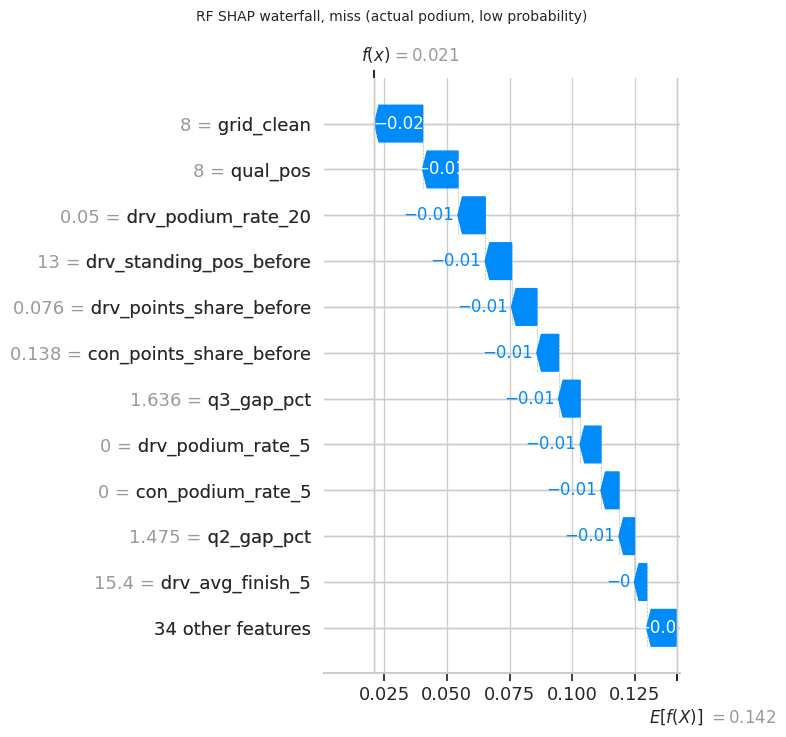

miss (actual podium, low probability): base 0.142 + contributions = 0.021 (model output 0.021)
  largest contributions: grid_clean -0.019; qual_pos -0.014; drv_podium_rate_20 -0.011; drv_standing_pos_before -0.011; drv_points_share_before -0.010


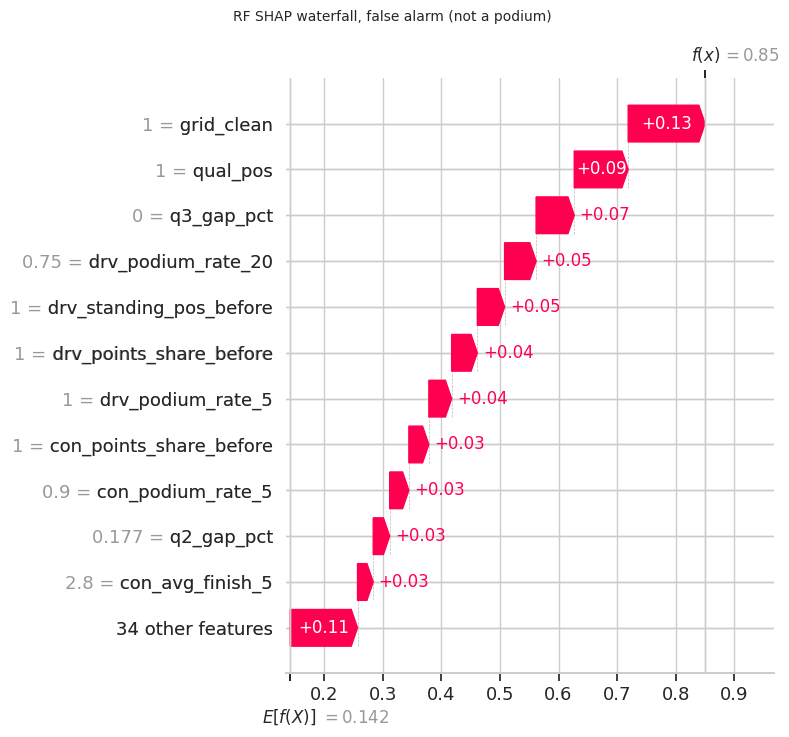

false alarm (not a podium): base 0.142 + contributions = 0.850 (model output 0.850)
  largest contributions: grid_clean +0.131; qual_pos +0.092; q3_gap_pct +0.069; drv_podium_rate_20 +0.054; drv_standing_pos_before +0.047


In [86]:
vals_rf, base_rf_, _ = SV["RF"]
for n, (lab, i) in enumerate(cases.items()):
    ex1 = shap.Explanation(values=vals_rf[i], base_values=base_rf_, data=DISP_VA[i], feature_names=PRE_NAMES)
    plt.figure(figsize=(9, 5.5))
    shap.plots.waterfall(ex1, max_display=12, show=False)
    fig = plt.gcf()
    fig.suptitle(f"RF SHAP waterfall, {lab}", fontsize=10)
    save_show(fig, f"s6_local_shap_{n + 1}")
    top = pd.Series(vals_rf[i], index=BASE_OF).groupby(level=0).sum().sort_values(key=np.abs, ascending=False).head(5)
    print(f"{lab}: base {base_rf_:.3f} + contributions = {base_rf_ + vals_rf[i].sum():.3f} (model output {p_rf[i]:.3f})")
    print("  largest contributions: " + "; ".join(f"{f} {v:+.3f}" for f, v in top.items()))

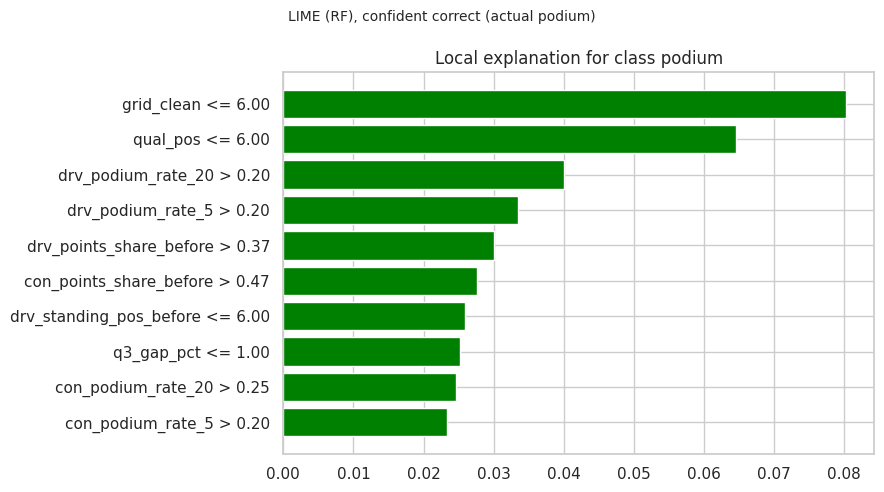

confident correct (actual podium): LIME local prediction 0.408 vs model 0.855
  LIME local surrogate fit (R^2 on its perturbed samples): 0.66
  LIME top 5: grid_clean (+0.080), qual_pos (+0.065), drv_podium_rate_20 (+0.040), drv_podium_rate_5 (+0.034), drv_points_share_before (+0.030)
  SHAP top 5: grid_clean (+0.132), qual_pos (+0.093), q3_gap_pct (+0.069), drv_podium_rate_20 (+0.054), drv_standing_pos_before (+0.046)
  features in both top-5 lists: 3 of 5


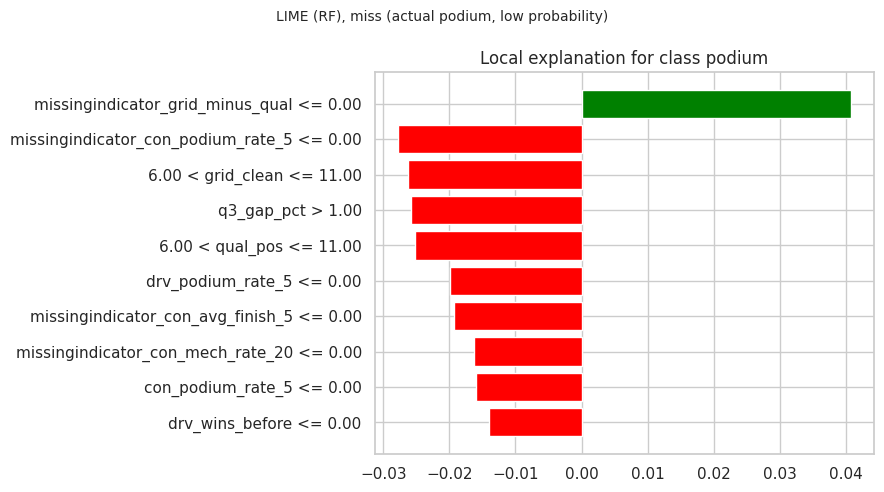

miss (actual podium, low probability): LIME local prediction 0.071 vs model 0.021
  LIME local surrogate fit (R^2 on its perturbed samples): 0.10
  LIME top 5: con_podium_rate_5 (-0.044), grid_minus_qual (+0.041), grid_clean (-0.026), q3_gap_pct (-0.026), qual_pos (-0.025)
  SHAP top 5: grid_clean (-0.019), qual_pos (-0.014), drv_podium_rate_20 (-0.011), drv_standing_pos_before (-0.011), drv_points_share_before (-0.010)
  features in both top-5 lists: 2 of 5


In [87]:
SHAP_TOP5, LIME_TOP5, LIME_FIT = {}, {}, {}
if HAS_LIME:
    from lime.lime_tabular import LimeTabularExplainer
    imp, sc = PRE.named_steps["imp"], PRE.named_steps["sc"]
    Z_tr = imp.transform(TR[FEATS])                   # raw (imputed) values + missing flags: rules stay readable
    le = LimeTabularExplainer(Z_tr, feature_names=PRE_NAMES, class_names=["not podium", "podium"], mode="classification",
                              discretize_continuous=True, random_state=SEED)
    predict_z = lambda Z: MODELS["RF"].predict_proba(sc.transform(Z))
    for n, (lab, i) in enumerate(list(cases.items())[:2]):
        exp = le.explain_instance(IMP_VA[i], predict_z, num_features=10, num_samples=3000)
        fig = exp.as_pyplot_figure()
        fig.set_size_inches(9, 5)
        fig.suptitle(f"LIME (RF), {lab}", fontsize=10)
        save_show(fig, f"s6_local_lime_{n + 1}")
        lime_feats = pd.Series({PRE_NAMES[k]: w for k, w in exp.as_map()[1]})
        lime_base = lime_feats.groupby(lime_feats.index.str.replace("missingindicator_", "")).sum().sort_values(key=np.abs, ascending=False)
        shap_base = pd.Series(vals_rf[i], index=BASE_OF).groupby(level=0).sum().sort_values(key=np.abs, ascending=False)
        LIME_TOP5[lab], SHAP_TOP5[lab] = list(lime_base.head(5).index), list(shap_base.head(5).index)
        print(f"{lab}: LIME local prediction {exp.local_pred[0]:.3f} vs model {p_rf[i]:.3f}")
        print(f"  LIME local surrogate fit (R^2 on its perturbed samples): {exp.score:.2f}")
        LIME_FIT[lab] = (float(exp.score), float(exp.local_pred[0]), float(p_rf[i]))
        print("  LIME top 5: " + ", ".join(f"{f} ({lime_base[f]:+.3f})" for f in LIME_TOP5[lab]))
        print("  SHAP top 5: " + ", ".join(f"{f} ({shap_base[f]:+.3f})" for f in SHAP_TOP5[lab]))
        print(f"  features in both top-5 lists: {len(set(LIME_TOP5[lab]) & set(SHAP_TOP5[lab]))} of 5")
else:
    print("LIME is not installed in this environment; the SHAP waterfalls above are the local explanations "
          "(the brief allows local SHAP, LIME or both).")

### Reading the three single predictions

**Confident correct case: Lewis Hamilton, 2020 Belgian Grand Prix (won from pole).** Everything points the same way: pole position, the fastest qualifying lap, a 75% podium rate over his last 20 races and the championship lead. The SHAP waterfall shows the grid slot and qualifying position adding the most, followed by the Q3 gap and recent form. This is the situation the model is built for.

**Miss: Esteban Ocon, 2021 Hungarian Grand Prix (won from 8th).** The model gave him about 2%. From the information available before the race, that was reasonable: 8th on the grid, a 5% recent podium rate and a midfield team. The race was decided by a first-lap pile-up at turn 1 in changing conditions that took out several cars ahead of him. Nothing in the pre-race data can predict a first-lap accident, so this miss is a limit of the prediction cutoff, not a fault in the model.

**False alarm: Lewis Hamilton, 2020 Italian Grand Prix (finished 7th from pole).** The model gave him about 85%, almost the same as the Belgian race, because the pre-race inputs were almost identical. He finished 7th after a stop-and-go penalty for entering the pit lane while it was closed, an event that happened during the race. Again the inputs were right; the outcome depended on something after the cutoff.

**SHAP and LIME agreement.** For the confident case 3 of the top 5 features agree, for the miss 2 of 5. Both methods put the grid slot and qualifying position among the most important features. The difference has a clear cause. SHAP for a random forest is exact: base value plus contributions equals the model output (checked in 6.5). LIME instead fits a small linear model on random variations of the row, drawn from the training distribution. For an extreme row such as a pole sitter with top form, the forest's output is far above what a straight line through those variations can reach, so LIME's local prediction is much lower than the model's (printed above, with the R² of LIME's local fit). LIME should therefore be read as a rough, direction-only check here, and SHAP as the faithful local explanation.

None of this is causal: the explanations describe what the model relies on, not why a driver finishes on the podium.

## 6.5 Sanity checks and what the explanations show

Before reading the explanations, three checks that they behave like explanations:
1. **Additivity.** For each explained row, the base value plus the SHAP values should equal the model output.
2. **Shuffling the top feature hurts.** If permutation importance were meaningless, shuffling the most important feature would not change the score.
3. **Methods agree.** The feature rankings from permutation importance and from SHAP should be similar, because they are two views of the same model.

In [88]:
chk = []
out_lr = MODELS["LR"].decision_function(Xva)
chk.append(("LR", "base + sum(SHAP) vs log-odds", float(np.abs(base_lr + sv_lr.sum(1) - out_lr).max())))
chk.append(("RF", "base + sum(SHAP) vs probability", float(np.abs(base_rf + sv_rf.sum(1) - P_VA["RF"]).max())))
chk.append(("NN", "base + sum(SHAP) vs probability (Kernel SHAP, approximate)", float(np.abs(base_nn + sv_nn.sum(1) - P_VA["NN"][SUB]).max())))
display(pd.DataFrame(chk, columns=["model", "check", "max abs error"]).round(5))

print("\nPermutation importance of the top feature (should be clearly above zero):")
for k in MODELS:
    d = PI_F[k]["mean_drop"].sort_values(ascending=False)
    print(f"  {k}: {d.index[0]} drop {d.iloc[0]:+.4f} (sd {PI_F[k].loc[d.index[0], 'sd']:.4f})")

print("\nAgreement between permutation importance and SHAP importance across the 28 features (Spearman):")
for k in MODELS:
    rho = stats.spearmanr(PI_F[k]["mean_drop"], SI[k]).statistic
    print(f"  {k}: rho = {rho:.2f}")
print("Agreement between models (Spearman of SHAP importance): " +
      "; ".join(f"{a} vs {b} {stats.spearmanr(SI[a], SI[b]).statistic:.2f}" for a, b in [("LR", "RF"), ("LR", "NN"), ("RF", "NN")]))

,model,check,max abs error
0,LR,base + sum(SHAP) vs log-odds,0.0
1,RF,base + sum(SHAP) vs probability,0.0
2,NN,"base + sum(SHAP) vs probability (Kernel SHAP, ...",0.0



Permutation importance of the top feature (should be clearly above zero):
  LR: qual_pos drop +0.1099 (sd 0.0172)
  RF: grid_clean drop +0.0505 (sd 0.0172)
  NN: qual_pos drop +0.0784 (sd 0.0139)

Agreement between permutation importance and SHAP importance across the 28 features (Spearman):
  LR: rho = 0.66
  RF: rho = 0.81
  NN: rho = 0.67
Agreement between models (Spearman of SHAP importance): LR vs RF 0.69; LR vs NN 0.55; RF vs NN 0.64


In [89]:
print("WHAT THE EXPLANATIONS SHOW (computed in this run)\n")
for k in MODELS:
    top_p = PI_F[k]["mean_drop"].sort_values(ascending=False).head(4)
    top_s = SI_share[k].sort_values(ascending=False).head(4)
    print(f"{k}:")
    print("  permutation importance, top 4: " + "; ".join(f"{f} {v:.3f}" for f, v in top_p.items()))
    print("  SHAP share, top 4: " + "; ".join(f"{f} {v:.0%}" for f, v in top_s.items()))
    g = PI_G[k]["mean_drop"].sort_values(ascending=False)
    print("  groups by permutation importance: " + ", ".join(f"{a} {b:.3f}" for a, b in g.items()))
d = dir_tbl[dir_tbl["model"] == "RF"]
print("\nDirection (RF): " + "; ".join(f"{r.feature}: {r.reading.replace('higher value -> ', 'higher means ')}" for r in d.head(5).itertuples()))
print("\nReading these results:")
print("- The models rely on the same few things: where the driver starts and how fast they were in qualifying, plus recent driver and team results.")
print("- Groups that overlap (grid and qualifying position, driver and team standings) share credit, so each can look smaller than it would alone. "
      "Compare this with the ablation in Section 5.")
print("- These are statements about what the models use, not about what causes podiums. A good grid slot comes from a fast car and a fast "
      "lap, and the model cannot separate the driver from the car.")
print("- Explanations were computed on 2020-2021 only; a different period could rank features differently.")

WHAT THE EXPLANATIONS SHOW (computed in this run)

LR:
  permutation importance, top 4: qual_pos 0.110; grid_clean 0.101; drv_podium_rate_20 0.040; reached_q2 0.028
  SHAP share, top 4: grid_clean 16%; qual_pos 16%; reached_q2 9%; q2_gap_pct 7%
  groups by permutation importance: grid 0.112, driver_form 0.096, qualifying 0.093, standings 0.044, constructor_form 0.006, era 0.000, circuit -0.011
RF:
  permutation importance, top 4: grid_clean 0.050; qual_pos 0.035; q3_gap_pct 0.020; q2_gap_pct 0.017
  SHAP share, top 4: grid_clean 17%; qual_pos 12%; q3_gap_pct 8%; drv_podium_rate_20 8%
  groups by permutation importance: qualifying 0.074, grid 0.050, driver_form 0.036, standings 0.028, constructor_form 0.006, circuit 0.002, era 0.000
NN:
  permutation importance, top 4: qual_pos 0.078; grid_clean 0.068; reached_q2 0.038; drv_podium_rate_20 0.037
  SHAP share, top 4: qual_pos 22%; grid_clean 18%; drv_podium_rate_20 11%; q2_gap_pct 8%
  groups by permutation importance: qualifying 0.113, d

## 6.6 Export the Section 6 report

In [90]:
export_report("/kaggle/working/section6_results.pdf", S6_START, "s6_", "F1 Podium Prediction, Section 6 results")

Wrote /kaggle/working/section6_results.pdf: 3 text pages + 12 figure pages


# Section 7: Inference Function

A reusable function that takes what is known about **one driver before one race** and returns a podium prediction. It is built to be used on real, imperfect input:

- Any subset of the 28 features may be given. The function separates two kinds of missing value:
  - **unknown**: the user did not supply the feature (it is left out, or passed as `None` or `""`). The function does not guess it. It switches to a **reduced model** of the same family, trained on the same training rows with only the features that were supplied, with its own threshold chosen on validation. Reduced models are trained once per set of supplied features and cached.
  - **missing as in the data**: the feature is passed as `NaN` because it does not exist for this driver, for example `q3_gap_pct` for a driver knocked out in Q2. The full model handles it exactly as in training (median fill plus a missing-value flag).
- Inputs are checked. Fields that only exist after the race (finishing position, points, status, lap times) are rejected with a clear message, because using them would break the prediction cutoff. Impossible values (a negative grid slot, a rate above 1) are rejected. Values outside the range seen in training are accepted with a warning.
- The function can run from the saved files alone (preprocessing, models, thresholds, and the training rows needed for reduced models), so it does not depend on the training session. Section 7.4 proves the two give the same answers.

**Why reduced models.** The first version filled unknown inputs with the training median. Section 7.3 keeps that version for comparison: it gave a pole sitter a podium probability of 0.0 when one feature group was unknown, and a higher probability when information was removed. The cause is the missing-value flags: in the training data a missing value means something specific (an old qualifying format, a rookie, a non-standard entry), and the models learned that meaning. A user who simply does not know a value is a different situation, so the function now leaves unknown features out instead of pretending they are missing in the data.

Output: probability of a podium, the yes/no call at the validation-chosen threshold, which inputs were unknown, which model was used (full or reduced, with the reduced model's validation PR-AUC), a reliability label, and the largest contributions to the prediction (exact for the logistic regression and the random forest).

The probability is a model score learned from 2003-2019 and checked on later seasons. Use it for comparing drivers within a race; it is not a betting-grade calibrated probability.

In [91]:
import difflib
S7_START = len(TEE.buf)   # the Section 7 report starts here

# fields that exist only after the race: never accepted as inputs
POST_RACE = {"positionOrder", "position", "points", "laps", "time", "milliseconds", "fastestLap", "fastestLapTime",
             "fastestLapSpeed", "rank", "statusId", "status", "podium", "resultId", "positionText"}
# hard limits: values outside are impossible, not just unusual
HARD = {
    "grid_clean": (1, 40), "pit_lane_start": (0, 1), "qual_pos": (1, 40), "q1_gap_pct": (0, 100), "q2_gap_pct": (0, 100),
    "q3_gap_pct": (0, 100), "reached_q2": (0, 1), "reached_q3": (0, 1), "grid_minus_qual": (-40, 40), "qual_missing": (0, 1),
    "drv_podium_rate_5": (0, 1), "drv_podium_rate_20": (0, 1), "drv_avg_finish_5": (1, 40), "drv_starts_prior": (0, 1000),
    "con_podium_rate_5": (0, 1), "con_podium_rate_20": (0, 1), "con_avg_finish_5": (1, 40), "con_mech_rate_20": (0, 1),
    "drv_points_share_before": (0, 1), "drv_standing_pos_before": (1, 200), "drv_wins_before": (0, 30),
    "con_points_share_before": (0, 1), "con_standing_pos_before": (1, 40), "season_opener": (0, 1),
    "drv_circuit_podium_rate_prior": (0, 1), "drv_circuit_starts_prior": (0, 500), "era_2003_08": (0, 1), "era_2009_13": (0, 1),
}
assert set(HARD) == set(FEATS), set(HARD) ^ set(FEATS)
TRAIN_RANGES = {f: (float(TR[f].min()), float(TR[f].max())) for f in FEATS}
CORE = ("grid_clean", "qual_pos", "drv_podium_rate_20")      # the three most important inputs in Sections 5 and 6

## 7.1 The function

Reliability labels, applied in this order:
- **low**: `grid_clean` is unknown or missing, or more than half of the inputs are unknown.
- **medium**: another core input (`qual_pos`, `drv_podium_rate_20`) is unknown, or more than a fifth of the inputs are unknown.
- **high**: otherwise.

Two fields are derived when possible and reported as such: `grid_minus_qual` (grid minus qualifying position) and `qual_missing` (from whether a qualifying position is given).

`predict(..., unknown="reduce")` is the default. `unknown="median"` reproduces the first version (median filling of unknown inputs) and is kept only for the comparison in section 7.3. `predict_batch` scores rows of a feature table: `NaN` there means missing as in the data, and columns that are absent from the table are treated as unknown.

Reduced random forests keep the selected depth and leaf size. When fewer than 10 columns remain they consider every column at each split instead of the square root of the number of columns: with only one or two columns per split, a tree often meets a column it cannot split (for example `pit_lane_start`, which has too few rows for a 50-row leaf), stops at the root and predicts the base rate. A first version without this rule gave a pole sitter with only the grid known 0.49 instead of about 0.80, because almost half of its trees never split. Section 7.3 prints how many trees never split as a check.


In [92]:
class PodiumPredictor:
    """Pre-race podium predictor. See Section 7 for the rules.

    unknown input  = left out of the record, or None / "": handled by a reduced model without that feature.
    missing input  = NaN: handled by the full model exactly as in training (median fill plus missing flag).
    """

    def __init__(self, pre, models, thresholds, feats, pre_names, train_ranges, hard=HARD, post_race=POST_RACE,
                 train_data=None, hyper=None):
        self.pre, self.models, self.thr = pre, models, thresholds
        self.feats, self.pre_names = list(feats), list(pre_names)
        self.ranges, self.hard, self.post_race = train_ranges, hard, post_race
        self.train_data, self.hyper = train_data, hyper
        self._bank, self._tree = {}, {}

    @classmethod
    def from_disk(cls, folder):
        card = joblib.load(f"{folder}/model_card.joblib")
        support = joblib.load(f"{folder}/inference_support.joblib")
        models = {"LR": joblib.load(f"{folder}/logistic_regression.joblib"),
                  "RF": joblib.load(f"{folder}/random_forest.joblib"),
                  "NN": keras.models.load_model(f"{folder}/neural_network.keras")}
        return cls(joblib.load(f"{folder}/preprocessing.joblib"), models, card["thresholds"], card["features"],
                   card["pre_names"], support["train_ranges"], support["hard"], set(support["post_race"]),
                   support["train_data"], support["hyper"])

    # ---------------------------------------------------------------- validation
    def check(self, record, strict=True):
        """Return (clean values, derived fields, warnings, unknown features). Raises ValueError on bad input."""
        if isinstance(record, pd.DataFrame):
            if len(record) != 1:
                raise ValueError("pass exactly one row, or use predict_batch for many")
            record = record.iloc[0]
        rec = dict(record)
        warns, derived = [], []
        for k in rec:
            if k in self.post_race:
                raise ValueError(f"'{k}' is only known after the race and cannot be used as an input at the prediction cutoff "
                                 f"(after qualifying, before the start).")
            if k not in self.feats:
                hint = difflib.get_close_matches(k, self.feats, n=2)
                raise ValueError(f"unknown feature '{k}'" + (f"; did you mean {' or '.join(hint)}?" if hint else "") +
                                 f". Valid features: {', '.join(self.feats)}")
        clean, unknown = {}, []
        for f in self.feats:
            v = rec.get(f, None)
            if v is None or (isinstance(v, str) and v.strip() == ""):
                clean[f] = np.nan
                unknown.append(f)
                continue
            try:
                v = float(v)
            except (TypeError, ValueError):
                raise ValueError(f"'{f}' must be a number, NaN or empty, got {rec[f]!r}")
            if not np.isnan(v):
                lo, hi = self.hard[f]
                if not (lo <= v <= hi):
                    raise ValueError(f"'{f}'={v:g} is impossible (allowed range {lo} to {hi})")
                tlo, thi = self.ranges[f]
                if not (tlo <= v <= thi):
                    warns.append(f"'{f}'={v:g} is outside the range seen in training ({tlo:g} to {thi:g}); the prediction extrapolates")
            clean[f] = v
        # derived fields
        if "qual_missing" in unknown and "qual_pos" not in unknown:
            clean["qual_missing"] = float(np.isnan(clean["qual_pos"]))
            unknown.remove("qual_missing"); derived.append("qual_missing")
        if "grid_minus_qual" in unknown and "grid_clean" not in unknown and "qual_pos" not in unknown:
            clean["grid_minus_qual"] = clean["grid_clean"] - clean["qual_pos"]
            unknown.remove("grid_minus_qual"); derived.append("grid_minus_qual")
        # consistency
        if clean["reached_q3"] == 1 and clean["reached_q2"] == 0:
            if strict:
                raise ValueError("inconsistent input: reached_q3 = 1 but reached_q2 = 0")
            warns.append("reached_q3 = 1 but reached_q2 = 0")
        if not (np.isnan(clean["grid_minus_qual"]) or np.isnan(clean["grid_clean"]) or np.isnan(clean["qual_pos"])):
            if abs(clean["grid_minus_qual"] - (clean["grid_clean"] - clean["qual_pos"])) > 1e-9:
                warns.append("grid_minus_qual does not equal grid_clean - qual_pos")
        if clean["qual_missing"] == 1 and not np.isnan(clean["qual_pos"]):
            warns.append("qual_missing = 1 but a qualifying position was given")
        return clean, derived, warns, unknown

    def _reliability(self, clean, unknown):
        n = len(self.feats)
        if "grid_clean" in unknown or np.isnan(clean["grid_clean"]) or len(unknown) > 0.5 * n:
            return "low"
        if any(c in unknown for c in CORE) or len(unknown) > 0.2 * n:
            return "medium"
        return "high"

    @staticmethod
    def _proba(m, Z):
        out = m.predict(Z, verbose=0) if hasattr(m, "layers") else m.predict_proba(Z)[:, 1]
        return np.asarray(out, dtype=float).ravel()

    # ---------------------------------------------------------------- full and reduced models
    def _bundle(self, model, known):
        known_set = set(known)
        known = [f for f in self.feats if f in known_set]
        if not known:
            raise ValueError("no usable input: supply at least one feature")
        if len(known) == len(self.feats):
            return {"pre": self.pre, "model": self.models[model], "names": self.pre_names, "feats": self.feats,
                    "thr": float(self.thr[model]), "reduced": False, "val_pr_auc": None}
        key = (model, tuple(known))
        if key not in self._bank:
            self._bank[key] = self._fit_reduced(model, known)
        return self._bank[key]

    def _fit_reduced(self, model, known):
        """Same family and hyperparameters as the selected model, trained on the training rows with only `known`."""
        if self.train_data is None or self.hyper is None:
            raise RuntimeError("reduced models need train_data and hyper (saved in inference_support.joblib)")
        td, h = self.train_data, self.hyper
        Xtr_, ytr_ = td["X_train"][known], td["y_train"]
        Xva_, yva_ = td["X_val"][known], td["y_val"]
        pre = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                        ("sc", StandardScaler())]).fit(Xtr_)
        A, B = pre.transform(Xtr_), pre.transform(Xva_)
        if model == "LR":
            m = LogisticRegression(C=h["C"], max_iter=3000).fit(A, ytr_)
        elif model == "RF":
            # With few columns, "sqrt" lets each split look at only one or two of them. If those cannot be split
            # (a constant flag, or pit_lane_start with too few rows for a 50-row leaf), the tree stops at the root
            # and predicts the base rate, which drags the forest towards 14%. Small column sets therefore use all columns.
            mf = "sqrt" if A.shape[1] >= 10 else None
            m = RandomForestClassifier(n_estimators=300, max_depth=h["rf_depth"], min_samples_leaf=h["rf_leaf"],
                                       max_features=mf, random_state=h["seed"], n_jobs=-1).fit(A, ytr_)
        else:
            keras.utils.set_random_seed(h["seed"])
            reg = keras.regularizers.l2(h["nn_l2"])
            m = keras.Sequential([keras.layers.Input((A.shape[1],)),
                                  keras.layers.Dense(32, activation="relu", kernel_regularizer=reg),
                                  keras.layers.Dropout(h["nn_dropout"]),
                                  keras.layers.Dense(16, activation="relu", kernel_regularizer=reg),
                                  keras.layers.Dropout(h["nn_dropout"]),
                                  keras.layers.Dense(1, activation="sigmoid")])
            m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
            m.fit(A, ytr_, validation_data=(B, yva_), epochs=200, batch_size=128, verbose=0,
                  class_weight={0: 1.0, 1: h["w_pos"]},
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
        pv = self._proba(m, B)
        ts = np.linspace(0.02, 0.90, 89)
        thr = float(ts[int(np.argmax([f1_score(yva_, (pv >= t).astype(int), zero_division=0) for t in ts]))])
        names = list(pre.named_steps["imp"].get_feature_names_out(known))
        unsplit = int(sum(t.tree_.node_count == 1 for t in m.estimators_)) if model == "RF" else None
        return {"pre": pre, "model": m, "names": names, "feats": known, "thr": thr, "reduced": True,
                "val_pr_auc": float(average_precision_score(yva_, pv)), "unsplit_trees": unsplit}

    # ---------------------------------------------------------------- explanation
    def _contributions(self, model, b, Z, clean, unknown, top_k):
        base_of = [n.replace("missingindicator_", "") for n in b["names"]]
        if model == "LR":
            lr = b["model"]
            contrib = lr.coef_[0] * Z[0]
            base, units = float(lr.intercept_[0]), "log-odds (relative to an average training row)"
        elif model == "RF":
            key = id(b["model"])
            if key not in self._tree:
                import shap
                self._tree[key] = shap.TreeExplainer(b["model"])
            ex = self._tree[key]
            sv = ex.shap_values(Z, check_additivity=False)
            sv = sv[1] if isinstance(sv, list) else np.asarray(sv)
            sv = sv[:, :, 1] if sv.ndim == 3 else sv
            contrib = sv[0]
            base, units = float(np.ravel(ex.expected_value)[-1]), "probability points (SHAP)"
        else:
            return None
        s = pd.Series(contrib, index=base_of).groupby(level=0).sum()
        s = s.sort_values(key=np.abs, ascending=False).head(top_k)

        def shown(f):
            if f in unknown:
                return "unknown (filled with training median)"
            if np.isnan(clean[f]):
                return "missing as in the data (median + flag)"
            return clean[f]
        rows = [{"feature": f, "value": shown(f), "contribution": float(c)} for f, c in s.items()]
        return {"base": base, "units": units, "top": rows}

    # ---------------------------------------------------------------- public
    def predict(self, record, model="RF", explain=True, top_k=5, unknown="reduce"):
        if model not in self.models:
            raise ValueError(f"model must be one of {list(self.models)}")
        if unknown not in ("reduce", "median"):
            raise ValueError("unknown must be 'reduce' (default) or 'median' (first version, kept for comparison)")
        clean, derived, warns, unk = self.check(record)
        if len(unk) == len(self.feats):
            raise ValueError("no usable input: supply at least one feature")
        known = self.feats if unknown == "median" else [f for f in self.feats if f not in unk]
        b = self._bundle(model, known)
        X = pd.DataFrame([[clean[f] for f in b["feats"]]], columns=b["feats"])
        Z = b["pre"].transform(X)
        p = float(self._proba(b["model"], Z)[0])
        res = {"model": model, "probability": p, "predicted_podium": bool(p >= b["thr"]), "threshold": b["thr"],
               "mode": unknown, "reduced": b["reduced"], "n_used": len(b["feats"]), "val_pr_auc": b["val_pr_auc"],
               "reliability": self._reliability(clean, unk), "n_missing": len(unk), "missing_features": unk,
               "data_missing": [f for f in self.feats if f not in unk and np.isnan(clean[f])],
               "derived_fields": derived, "warnings": warns}
        if explain:
            res["explanation"] = self._contributions(model, b, Z, clean, unk, top_k)
        return res

    def predict_batch(self, df, model="RF"):
        """Score rows of a feature table. NaN = missing as in the data; absent columns = unknown."""
        known = [c for c in self.feats if c in df.columns]
        rows = [self.check(r, strict=False)[0] for _, r in df[known].iterrows()]
        b = self._bundle(model, known)
        X = pd.DataFrame(rows, columns=self.feats)[b["feats"]]
        p = self._proba(b["model"], b["pre"].transform(X))
        return pd.DataFrame({"probability": p, "predicted_podium": p >= b["thr"]}, index=df.index)

    @staticmethod
    def describe(res):
        if res["reduced"]:
            how = (f"reduced model on the {res['n_used']} known features "
                   f"(its own validation PR-AUC {res['val_pr_auc']:.3f}, threshold {res['threshold']:.2f})")
        elif res["missing_features"]:
            how = "full model, unknown inputs filled with training medians (first version)"
        else:
            how = "full model"
        lines = [f"[{res['model']}] podium probability {res['probability']:.1%} -> "
                 f"{'PODIUM' if res['predicted_podium'] else 'no podium'} (threshold {res['threshold']:.2f}); "
                 f"reliability {res['reliability'].upper()}; {res['n_missing']} of {len(HARD)} inputs unknown",
                 f"  {how}"]
        if res["missing_features"]:
            lines.append(("  left out (unknown): " if res["reduced"] else "  filled with training medians: ")
                         + ", ".join(res["missing_features"]))
        if res["data_missing"]:
            lines.append("  missing as in the data (median + flag): " + ", ".join(res["data_missing"]))
        if res["derived_fields"]:
            lines.append("  derived from other inputs: " + ", ".join(res["derived_fields"]))
        for w in res["warnings"]:
            lines.append("  warning: " + w)
        ex = res.get("explanation")
        if ex:
            lines.append(f"  base {ex['base']:+.3f} | largest contributions in {ex['units']}:")
            for r in ex["top"]:
                v = r["value"] if isinstance(r["value"], str) else f"{r['value']:g}"
                lines.append(f"    {r['feature']:<30s} = {v:<10s} {r['contribution']:+.3f}")
        return "\n".join(lines)


# support file so the saved models (and reduced models) can be used without this session
SUPPORT = {"train_ranges": TRAIN_RANGES, "hard": HARD, "post_race": sorted(POST_RACE),
           "train_data": {"X_train": TR[FEATS].reset_index(drop=True), "y_train": ytr,
                          "X_val": VA[FEATS].reset_index(drop=True), "y_val": yva},
           "hyper": {"C": C_BEST, "rf_depth": RF_DEPTH, "rf_leaf": RF_LEAF, "seed": SEED,
                     "nn_l2": 1e-4, "nn_dropout": 0.3, "w_pos": w_pos}}
joblib.dump(SUPPORT, "/kaggle/working/models/inference_support.joblib")
PRED = PodiumPredictor(PRE, MODELS, THR, FEATS, PRE_NAMES, TRAIN_RANGES,
                       train_data=SUPPORT["train_data"], hyper=SUPPORT["hyper"])
print("predictor ready; models:", list(MODELS), "| thresholds of the full models:", {k: round(v, 2) for k, v in THR.items()})

predictor ready; models: ['LR', 'RF', 'NN'] | thresholds of the full models: {'LR': 0.24, 'RF': 0.36, 'NN': 0.82}


## 7.2 Demonstration 1: a complete record

A real driver-race from the test seasons: the pole sitter of the latest race that has a complete feature row. The inputs are exactly the 28 pre-race features; the finishing result is shown only afterwards for comparison. (Scoring a test row here is a demonstration of the function, not a new evaluation.)

In [93]:
TEs = feat[feat["split"] == "test"].copy()
full = TEs[TEs[FEATS].notna().all(axis=1)]
last_race = full["race_idx"].max()
row = full[full["race_idx"] == last_race].sort_values("grid_clean").iloc[0]
who = f"{DRV.loc[row.driverId, 'forename']} {DRV.loc[row.driverId, 'surname']}"
race = f"{int(RAC.loc[row.raceId, 'year'])} {RAC.loc[row.raceId, 'name']}"
COMPLETE = {f: float(row[f]) for f in FEATS}
print(f"Record: {who}, {race} (all {len(FEATS)} inputs supplied)")
print({k: round(v, 3) for k, v in COMPLETE.items()})
print()
for m in ["LR", "RF", "NN"]:
    print(PodiumPredictor.describe(PRED.predict(COMPLETE, model=m)))
print(f"\nWhat happened (known only after the race): finished position {int(row.positionOrder)} -> podium: {bool(row.podium)}")

Record: Lando Norris, 2024 Abu Dhabi Grand Prix (all 28 inputs supplied)
{'grid_clean': 1.0, 'pit_lane_start': 0.0, 'qual_pos': 1.0, 'q1_gap_pct': 0.456, 'q2_gap_pct': 0.136, 'q3_gap_pct': 0.0, 'reached_q2': 1.0, 'reached_q3': 1.0, 'grid_minus_qual': 0.0, 'qual_missing': 0.0, 'drv_podium_rate_5': 0.2, 'drv_podium_rate_20': 0.55, 'drv_avg_finish_5': 5.6, 'drv_starts_prior': 127.0, 'con_podium_rate_5': 0.2, 'con_podium_rate_20': 0.475, 'con_avg_finish_5': 5.9, 'con_mech_rate_20': 0.0, 'drv_points_share_before': 0.814, 'drv_standing_pos_before': 2.0, 'drv_wins_before': 3.0, 'con_points_share_before': 1.0, 'con_standing_pos_before': 1.0, 'season_opener': 0.0, 'drv_circuit_podium_rate_prior': 0.0, 'drv_circuit_starts_prior': 5.0, 'era_2003_08': 0.0, 'era_2009_13': 0.0}

[LR] podium probability 82.2% -> PODIUM (threshold 0.24); reliability HIGH; 0 of 28 inputs unknown
  full model
  base -3.467 | largest contributions in log-odds (relative to an average training row):
    qual_pos           

## 7.3 Demonstration 2: partially missing records

Same driver and race, but with information unknown, as would happen in practice (qualifying times not yet loaded, form history not computed, a circuit the driver has never raced). The values are passed as `None`, which means unknown. The function must still answer, say which model it used and what it left out, and lower its reliability label.

In [94]:
partial = {k: v for k, v in COMPLETE.items()}
for k in FEATURE_GROUPS["qualifying"][1:] + FEATURE_GROUPS["driver_form"][:3] + FEATURE_GROUPS["circuit"]:
    partial[k] = None            # None, NaN and "" are all treated as missing
print("Partial record A: qualifying gaps, driver form and circuit history unknown")
for m in ["LR", "RF", "NN"]:
    print(PodiumPredictor.describe(PRED.predict(partial, model=m)))

minimal = {"grid_clean": 5, "qual_pos": 5, "con_podium_rate_20": 0.4}
print("\nPartial record B: only three inputs supplied (a hand-typed record)")
for m in ["LR", "RF"]:
    print(PodiumPredictor.describe(PRED.predict(minimal, model=m, explain=(m == "RF"))))

print("\nPartial record C: grid slot unknown")
print(PodiumPredictor.describe(PRED.predict({k: v for k, v in COMPLETE.items() if k != "grid_clean"}, model="RF", explain=False)))

Partial record A: qualifying gaps, driver form and circuit history unknown
[LR] podium probability 71.3% -> PODIUM (threshold 0.32); reliability MEDIUM; 10 of 28 inputs unknown
  reduced model on the 18 known features (its own validation PR-AUC 0.732, threshold 0.32)
  left out (unknown): q1_gap_pct, q2_gap_pct, q3_gap_pct, reached_q2, reached_q3, drv_podium_rate_5, drv_podium_rate_20, drv_avg_finish_5, drv_circuit_podium_rate_prior, drv_circuit_starts_prior
  derived from other inputs: qual_missing, grid_minus_qual
  base -3.640 | largest contributions in log-odds (relative to an average training row):
    qual_pos                       = 1          +1.427
    grid_clean                     = 1          +1.422
    drv_standing_pos_before        = 2          +0.590
    con_podium_rate_20             = 0.475      +0.361
    drv_points_share_before        = 0.81352    +0.281
[RF] podium probability 71.5% -> PODIUM (threshold 0.27); reliability MEDIUM; 10 of 28 inputs unknown
  reduced mo

### Before and after: median filling against reduced models

The table and figure below repeat the record with one feature group at a time unknown, scored both ways: with the first version (unknown inputs filled with training medians, `unknown="median"`) and with reduced models (`unknown="reduce"`, the default). A useful predictor should move smoothly towards what the remaining information supports; for a pole sitter with only the grid known, that is roughly the historical podium rate from pole.

,scenario,n_unknown,LR median-fill,LR reduced,RF median-fill,RF reduced,RF reduced val PR-AUC,NN median-fill,NN reduced,reliability
0,complete,0,0.822,0.822,0.720,0.720,0.744,0.965,0.965,high
1,without grid,2,0.504,0.821,0.525,0.691,0.719,0.866,0.967,low
2,without qualifying,8,0.325,0.751,0.437,0.637,0.725,0.015,0.962,medium
3,without driver_form,4,0.771,0.774,0.643,0.735,0.734,0.994,0.952,medium
4,without constructor_form,4,0.165,0.806,0.646,0.753,0.746,0.000,0.961,high
5,without standings,6,0.525,0.754,0.577,0.706,0.743,0.939,0.947,medium
6,without circuit,2,0.798,0.808,0.715,0.730,0.742,0.967,0.953,high
7,without era,2,0.822,0.827,0.720,0.710,0.742,0.965,0.951,high
8,grid only,26,0.003,0.676,0.113,0.803,0.649,0.000,0.941,low


Reference: pole sitters in the training seasons finished on the podium 80.3% of the time.
Sanity check, trees that never split (they predict the base rate): full RF 0 of 300; reduced RFs, max over all scenarios 0 of 300.
LR: range over the scenarios, median-fill 0.003 to 0.822; reduced 0.676 to 0.827. Grid only: median-fill 0.003, reduced 0.676.
RF: range over the scenarios, median-fill 0.113 to 0.720; reduced 0.637 to 0.803. Grid only: median-fill 0.113, reduced 0.803.
NN: range over the scenarios, median-fill 0.000 to 0.994; reduced 0.941 to 0.967. Grid only: median-fill 0.000, reduced 0.941.


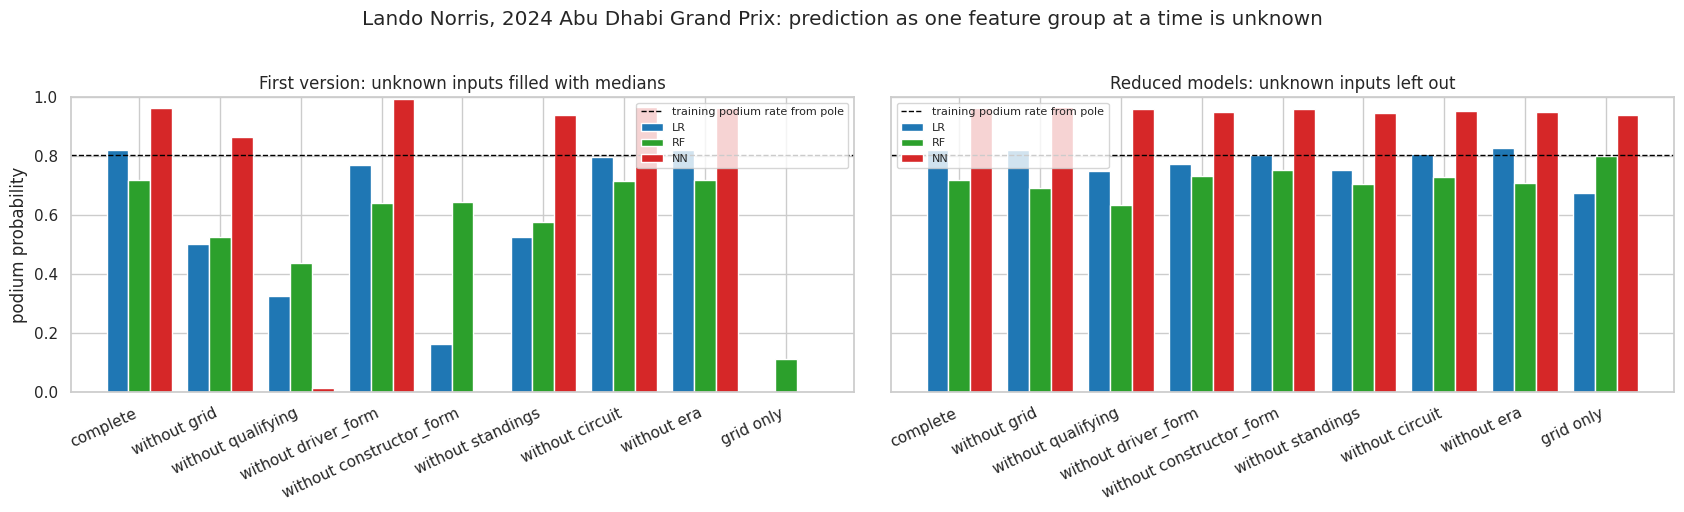

In [98]:
# Before and after: the first version (median filling of unknown inputs) against reduced models,
# removing one feature group at a time from the complete record.
scen = {"complete": []}
for g in GROUPS:
    scen[f"without {g}"] = FEATURE_GROUPS[g]
scen["grid only"] = [f for f in FEATS if f not in FEATURE_GROUPS["grid"]]
rows_ = []
for name, drop in scen.items():
    rec = {k: (None if k in drop else v) for k, v in COMPLETE.items()}
    out = {"scenario": name, "n_unknown": len(drop)}
    for m in ["LR", "RF", "NN"]:
        out[f"{m} median-fill"] = PRED.predict(rec, model=m, explain=False, unknown="median")["probability"]
        r_ = PRED.predict(rec, model=m, explain=False, unknown="reduce")
        out[f"{m} reduced"] = r_["probability"]
        if m == "RF":
            out["RF reduced val PR-AUC"] = r_["val_pr_auc"] if r_["reduced"] else REG[BEST["RF"]]["va"]["pr_auc"]
    out["reliability"] = r_["reliability"]
    rows_.append(out)
miss_tbl = pd.DataFrame(rows_)
display(miss_tbl.round(3))

pole_rate = float(TR.loc[TR["grid_clean"] == 1, "podium"].mean())
print(f"Reference: pole sitters in the training seasons finished on the podium {pole_rate:.1%} of the time.")
full_unsplit = sum(t.tree_.node_count == 1 for t in MODELS["RF"].estimators_)
red_unsplit = {k[1][:3]: b_["unsplit_trees"] for k, b_ in PRED._bank.items() if k[0] == "RF"}
print(f"Sanity check, trees that never split (they predict the base rate): full RF {full_unsplit} of 300; "
      f"reduced RFs, max over all scenarios {max(red_unsplit.values()) if red_unsplit else 0} of 300.")
for m in ["LR", "RF", "NN"]:
    a, b = miss_tbl[f"{m} median-fill"], miss_tbl[f"{m} reduced"]
    print(f"{m}: range over the scenarios, median-fill {a.min():.3f} to {a.max():.3f}; reduced {b.min():.3f} to {b.max():.3f}. "
          f"Grid only: median-fill {a.iloc[-1]:.3f}, reduced {b.iloc[-1]:.3f}.")

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
w, xs = 0.27, np.arange(len(miss_tbl))
for ax, mode, title in [(axes[0], "median-fill", "First version: unknown inputs filled with medians"),
                        (axes[1], "reduced", "Reduced models: unknown inputs left out")]:
    for j, m in enumerate(["LR", "RF", "NN"]):
        ax.bar(xs + (j - 1) * w, miss_tbl[f"{m} {mode}"], w, color=COL[m], label=m)
    ax.axhline(pole_rate, color="black", ls="--", lw=1, label="training podium rate from pole")
    ax.set_xticks(xs); ax.set_xticklabels(miss_tbl["scenario"], rotation=25, ha="right")
    ax.set_ylim(0, 1); ax.set_title(title); ax.legend(fontsize=8)
axes[0].set_ylabel("podium probability")
fig.suptitle(f"{who}, {race}: prediction as one feature group at a time is unknown", y=1.02)
save_show(fig, "s7_missing_information")

## 7.4 Input validation, and proof that the saved files give the same answers

Bad input must fail loudly and early. Then the predictor is rebuilt from the files on disk only and compared with the in-session one on 200 validation rows and on the demonstration record.

In [99]:
tests = [
    ("post-race field", {"grid_clean": 3, "positionOrder": 1}),
    ("another post-race field", {"grid_clean": 3, "points": 25}),
    ("impossible grid slot", {"grid_clean": -2}),
    ("rate above 1", {"grid_clean": 3, "drv_podium_rate_20": 1.7}),
    ("text instead of a number", {"grid_clean": "front"}),
    ("misspelled feature", {"grid_clen": 3}),
    ("reached Q3 without Q2", {"grid_clean": 3, "reached_q3": 1, "reached_q2": 0}),
    ("nothing supplied", {}),
]
for label, rec in tests:
    try:
        PRED.predict(rec, explain=False)
        print(f"{label:28s} NOT REJECTED (unexpected)")
    except ValueError as e:
        print(f"{label:28s} rejected: {str(e)[:150]}")
print()
try:
    r38 = PRED.predict({"grid_clean": 38}, explain=False)
    print("grid_clean=38 accepted (possible, but outside the training range):", r38["warnings"])
except ValueError as e:
    print("grid_clean=38 rejected:", e)

PRED_DISK = PodiumPredictor.from_disk("/kaggle/working/models")
sample = VA.sample(200, random_state=SEED)
chk = []
for m in ["LR", "RF", "NN"]:
    a = PRED.predict_batch(sample, model=m)["probability"].to_numpy()
    b = PRED_DISK.predict_batch(sample, model=m)["probability"].to_numpy()
    ref = pd.Series(P_VA[m], index=VA.index).loc[sample.index].to_numpy()
    chk.append({"model": m, "max |memory - disk|": float(np.abs(a - b).max()), "max |function - Section 4 predictions|": float(np.abs(a - ref).max())})
display(pd.DataFrame(chk))
assert all(r["max |memory - disk|"] < 1e-5 and r["max |function - Section 4 predictions|"] < 1e-5 for r in chk)
one_mem = PRED.predict(COMPLETE, model="RF", explain=False)["probability"]
one_disk = PRED_DISK.predict(COMPLETE, model="RF", explain=False)["probability"]
print(f"complete record, RF: in-session {one_mem:.6f} | from disk {one_disk:.6f}")
assert abs(one_mem - one_disk) < 1e-9
for m in ["LR", "RF"]:
    a_ = PRED.predict(minimal, model=m, explain=False)["probability"]
    b_ = PRED_DISK.predict(minimal, model=m, explain=False)["probability"]
    print(f"three-input record, {m} reduced model: in-session {a_:.6f} | from disk {b_:.6f}")
    assert abs(a_ - b_) < 1e-9
print("PASSED: the function reproduces the Section 4 predictions, and full and reduced models work from the saved files alone.")

post-race field              rejected: 'positionOrder' is only known after the race and cannot be used as an input at the prediction cutoff (after qualifying, before the start).
another post-race field      rejected: 'points' is only known after the race and cannot be used as an input at the prediction cutoff (after qualifying, before the start).
impossible grid slot         rejected: 'grid_clean'=-2 is impossible (allowed range 1 to 40)
rate above 1                 rejected: 'drv_podium_rate_20'=1.7 is impossible (allowed range 0 to 1)
text instead of a number     rejected: 'grid_clean' must be a number, NaN or empty, got 'front'
misspelled feature           rejected: unknown feature 'grid_clen'; did you mean grid_clean?. Valid features: grid_clean, pit_lane_start, qual_pos, q1_gap_pct, q2_gap_pct, q3_gap_pct, reach
reached Q3 without Q2        rejected: inconsistent input: reached_q3 = 1 but reached_q2 = 0
nothing supplied             rejected: no usable input: supply at least one fe

,model,max |memory - disk|,max |function - Section 4 predictions|
0,LR,0.000000e+00,0.000000e+00
1,RF,2.220446e-16,1.110223e-16
2,NN,0.000000e+00,2.235174e-08


complete record, RF: in-session 0.720263 | from disk 0.720263
three-input record, LR reduced model: in-session 0.343688 | from disk 0.343688
three-input record, RF reduced model: in-session 0.234215 | from disk 0.234215
PASSED: the function reproduces the Section 4 predictions, and full and reduced models work from the saved files alone.


## 7.5 Usage and limits

```python
predictor = PodiumPredictor.from_disk("/kaggle/working/models")
# features that are not known are simply left out; NaN means "missing as in the data"
result = predictor.predict({"grid_clean": 3, "qual_pos": 3, "q1_gap_pct": 0.4, "drv_podium_rate_20": 0.35,
                            "con_podium_rate_20": 0.6}, model="RF")
print(PodiumPredictor.describe(result))
```

Limits worth stating next to the function:
- It scores one driver at a time. Two drivers in the same race are not constrained to share the three podium places, so probabilities within a race need not add up to 3.
- The 28 features must be computed with the same definitions as in Section 3 (for example, form features use only earlier races). The function checks ranges and consistency, not how a number was computed.
- A reduced model is trained the first time a new combination of known features is seen (a second or two for LR and RF, longer for the network) and then cached. Its validation PR-AUC is reported, so a user can see how much accuracy the missing information costs.
- The caller must use `None` (unknown) and `NaN` (missing as in the data) correctly. Passing `NaN` for a value that simply is not known sends the record through the full model's missing-value flags, which is the behaviour section 7.3 shows to be unreliable.
- The models were trained on 2003-2019. New regulations or rule changes can move performance in ways no feature captures.

## 7.6 Export the Section 7 report

In [100]:
export_report("/kaggle/working/section7_results.pdf", S7_START, "s7_", "F1 Podium Prediction, Section 7 results")

Wrote /kaggle/working/section7_results.pdf: 2 text pages + 1 figure pages


# Section 8: Known limitations and conclusions

This section collects the limitations that earlier sections point to, so they can be read in one place and copied into the written report.

## 8.1 Data and cleaning
- **Qualifying data is missing before 2003.** Qualifying records cover 0% of rows before 1994, 46% in 1994-2002 and 99.8% from 2003 (Section 1.5.3). This forced the main training window to start in 2003 and leaves about 64% of the history unusable for qualifying features. Experiment C shows that longer windows without qualifying features do not help.
- **Rule R2 uses a little post-cutoff information.** Drivers who qualified but did not start (47 rows from 2003 on, all non-podiums) are removed. At the cutoff nobody knows yet that the driver will not start. The effect on the training data is small (47 of about 7,000 rows), but strictly the model is evaluated only on drivers who did start.
- **Shared drives in the 1950s.** Keeping the row with the best grid slot (a pre-race rule) means 17 driver-race pairs lose a podium that belonged to the shared car, and 3 races have only two podium rows. These rows are history only and never training rows.
- **Judgement calls in the data-engineering questions.** The nationality-to-country mapping (Q2), the grouping of 139 status values into mechanical and other causes (Q3, where `Retired` and `Fuel leak` are not counted as mechanical in the main answer) and the team lineages are all manual. Sensitivity checks show the conclusions do not depend on them, but other reasonable choices exist.

## 8.2 Features
- **Era sensitivity.** The era flags are always 0 in validation and test (2014 onward), so they only affect how the model fits the training seasons. The 2022 ground-effect regulations have no flag at all, because no training season follows them. A future rule change can move performance in ways no feature captures.
- **Grid and qualifying overlap.** Grid and qualifying position correlate at 0.97, and driver and team standings at about 0.9. Importance is shared between them, so no single feature's importance should be over-read.
- **The circuit group hurts the logistic regression.** Removing it improves validation PR-AUC by about 0.011 for LR, but not for RF or NN (Section 5.4). The models were fixed before the ablation and the test run, so the group is kept; a model without it is the next thing to try.
- **Form features need history.** Drivers with fewer than 3 earlier starts and teams with fewer than 3 earlier races have no form values; they are filled with the training median plus a missing-value flag, so predictions for rookies and new teams are less reliable.

## 8.3 Models and evaluation
- **Small validation set.** Validation covers 39 races. Most differences between attempts are within the bootstrap noise, so the choice between tied attempts rests on design reasons (Section 4.10), not on score.
- **Probabilities are scores, not calibrated chances.** Class weighting (NN) shifts probabilities upward, and no model is constrained so that the probabilities in one race add up to three podium places. Use them to rank drivers within a race.
- **Early stopping looked at validation.** The network's validation scores are slightly optimistic; the test set is the fair comparison.
- **Single random split in time.** One validation period and one test period are used. A rolling evaluation over several seasons would give a more robust estimate.
- **What the cutoff cannot see.** First-lap accidents, safety cars, weather changes, penalties and mechanical failures during the race decide many podiums (Section 6.4). No pre-race model can predict them, which puts a ceiling on achievable accuracy.

## 8.4 Explanations
- Permutation importance, SHAP and LIME describe **what the models rely on, not what causes a podium**. A good grid slot is itself the result of a fast car and a fast lap.
- Kernel SHAP for the network is approximate and uses 150 validation rows. LIME's local surrogate fits extreme rows poorly, so it is used only as a direction check next to SHAP.
- Explanations were computed on 2020-2021 only; another period could rank features differently.

## 8.5 Conclusions
1. **Data engineering.** No circuit reliably converts front-row starts better than others, but front-row conversion rose clearly in the hybrid era (Q1). There is no detectable home advantage once grid position is controlled (Q2). Mechanical retirements fell from 8.9% to 5.4% of starts between 2014-2021 and 2022-2024, with McLaren and Red Bull improving most (Q3).
2. **Features.** Starting position and qualifying pace carry most of the signal, followed by the driver's recent podium rate. All features pass an automated leakage test.
3. **Models.** All models beat the "top 3 on the grid" rule. The random forest is the best model on the unseen 2022-2024 seasons and the only one reliably better than the logistic-regression baseline (on ROC-AUC). The shallow neural network does not earn its extra complexity on about 6,800 training rows.
4. **Use.** The inference function gives a podium probability from any subset of pre-race inputs, says which inputs were unknown and how reliable the answer is, and rejects post-race fields.